# Uncertainty-Aware Fairness: experiments

This notebook accompanies the paper and presents the C1–C4 methods, experimental settings, results and supporting analyses. Each section connects the research question to its calculation, tables and figures.

**Run:** use a Python 3 kernel with NumPy, pandas, SciPy, Matplotlib and IPython; choose **Restart Kernel and Run All**. All numerical inputs and displayed figures are embedded. No account, network connection, patient records or external file paths are required. Saved output is supplied so that the evidence can also be read without execution.

**Execution.** Running the notebook recalculates C1 probabilities, C2 conditional quantities, an allocation-algorithm example and exact pooled C4 decisions. Other tables are reconstructed from the included aggregate experiment records. Model fits, runtime and memory benchmarks, bootstrap-law results and the two external audit adapters (the Cherian and Candès bootstrap and the Uncertainty Matters wrapper) are supplied as recorded results; the adapter code is not included in this repository.

**Navigation**
1. Study questions, decision targets and pipeline
2. Cohorts, partitions, protected groups and complete model settings
3. C1: exact repeated-audit computation, support, rules and external comparisons
4. C2: source sensitivity and conditional evidence requirements
5. C3: allocation, correctness, forecasts and grid sensitivity
6. C4: matched policy review and error trade-offs
7. Numerical checks and aggregate-input catalogue
8. Full technical-companion tables and figure catalogue

Sections 2–7 explain the main results. Section 8 provides the technical-companion index; expand an entry to read its protocol, derivation or results.

In [1]:
import base64, hashlib, html, io, json, platform, re, time, zlib
from itertools import product
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import beta, betabinom, binom, hypergeom, norm
from IPython.display import display, HTML, Markdown, Image

started = time.perf_counter()
checks = []
def record(name, condition, scope):
    assert bool(condition), name
    checks.append({'Check': name, 'Status': 'Passed', 'Scope': scope})

pd.options.display.float_format = '{:.7g}'.format
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
cohort_name = {'texas':'Texas-100X', 'eicu':'eICU', 'mimic':'MIMIC-III'}
display(pd.DataFrame([{'Python':platform.python_version(), 'NumPy':np.__version__,
    'pandas':pd.__version__, 'SciPy':scipy.__version__, 'Matplotlib':matplotlib.__version__}]))
display(HTML('<style>.table-scroll{overflow-x:auto;max-height:650px;overflow-y:auto} td,th{padding:6px;text-align:left;vertical-align:top} details{margin:8px 0} summary{cursor:pointer;font-weight:bold}</style>'))

,Python,NumPy,pandas,SciPy,Matplotlib
0,3.11.9,2.4.2,2.3.3,1.15.3,3.10.8


The next cell stores the frozen aggregate inputs and manuscript exhibit catalogue. The compressed payload keeps the notebook portable; the following cell checks every embedded table against its checksum. The computation code remains visible and editable.

In [2]:
payload_bytes = zlib.decompress(base64.b64decode('...'))
assert hashlib.sha256(payload_bytes).hexdigest() == '509c8de60d74d577c679d1476308c18eee619db5782dc07495db6c5fea7023fe'
evidence = json.loads(payload_bytes)

In [3]:
def frame(key):
    return pd.read_csv(io.StringIO(evidence['datasets'][key]))

for item in evidence['provenance']:
    raw = evidence['datasets'][item['key']].encode()
    assert hashlib.sha256(raw).hexdigest() == item['embedded_sha256'], item['key']
    assert len(frame(item['key'])) == item['rows'], item['key']
record('Embedded numerical evidence integrity', True, 'Aggregate-file checksums and row counts')

def show_table(number, document='main'):
    key = 'main_tables' if document == 'main' else 'supp_tables'
    matches = [t for t in evidence[key] if str(t['number']) == str(number) or t['label'] == number]
    assert len(matches) == 1, number
    t = matches[0]
    display(HTML('<h4>'+html.escape(('Main ' if document=='main' else 'Companion ')+str(t['number'])+': '+t['caption'])+'</h4>'+t['html']))

def show_figure(number, document='main'):
    key = 'main_figures' if document == 'main' else 'supp_figures'
    figures = [f for f in evidence[key] if str(f['number']) == str(number)]
    assert figures, number
    for f in figures:
        display(Image(data=base64.b64decode(f['png'])))
        display(Markdown('**Figure '+str(f['number'])+'.** '+f['caption']))

print(f"Loaded {len(evidence['datasets'])} aggregate datasets, {len(evidence['main_tables'])} main tables, "
      f"{len(evidence['supp_tables'])} companion tables, {len(evidence['main_figures'])} main figures and "
      f"{len(evidence['supp_figures'])} companion figure occurrences.")

Loaded 57 aggregate datasets, 12 main tables, 101 companion tables, 3 main figures and 7 companion figure occurrences.


## 1. Study questions and pipeline

The study audits fixed predictions; it does not train a model to make every group fair. An audit records a difference in errors or selection rates, compares its interval with a declared tolerance, and preserves an **inconclusive** outcome when the evidence supports neither passing nor failing. This keeps sparse groups visible instead of silently treating missing evidence as a pass.

| Question / contribution | What is initially known? | Calculation | Decision informed |
|---|---|---|---|
| RQ1 / C1 | Group counts, a shared reference, a fixed audit rule and a count law | Exact probabilities of repeated pass, inconclusive and fail; reusable boundary runs | Whether a recorded verdict is stable and whether computation can be reused |
| RQ2 / C2 | Repeated supported hospital comparisons and fitted variance components | Conditional risk attribution and sufficient count guard | Which fitted variation additional within-hospital observations could reduce |
| RQ3 / C3 | Positive-outcome group membership, finite group sizes and pilot prediction linkage | Budget allocation, confirmation probabilities and pilot-based forecast bounds | Where to verify more records and whether the pilot supports a gain over balancing |
| RQ4 / C4 | Two frozen predictions and their disagreement records | Outcome verification and criterion-specific finite-population bounds | Whether a proposed policy meets a declared miss/false-alert criterion |

C2 is a sensitivity branch, not an input that has been validated to set C3 allocations. C3 verifies prediction linkage within a known positive frame; C4 verifies outcomes within known prediction disagreements. Their review units and assumptions must not be exchanged.

Analysis,Known before calculation/review,Acquired or estimated,Evaluation-only or unpriced information
C1 probabilities,"Rule, denominators, shared reference and supplied count law","Law parameters, when fitted upstream",Unknown population law; preparation cost reported separately
C2 binary risk sensitivity,Supported hospital-by-sex counts; replication design,"Mean, hospital variance, working sampling variance and constant",Synthetic truth; no calibrated clinical confidence guarantee
C3 positive frame,"Categories, complete positive membership/sizes, frozen predictor and access design",Pilot/confirmation prediction-linkage or error verification,Complete errors for evaluation/oracle; complete positive-frame construction and ascertainment unpriced
C4 net-miss/count caps,"Both classifications, categories, disagreement sizes and signed alert changes",Outcomes in reviewed disagreements,Complete confusion counts assess truth; no full outcome denominators needed
C4 positive rate allowances,"Above, plus complete positive/negative group totals for false-negative/false-positive rate (FNR/FPR) allowances",Same disagreement outcomes,Denominator acquisition cost is external; full linked ascertainment already reveals policy truth


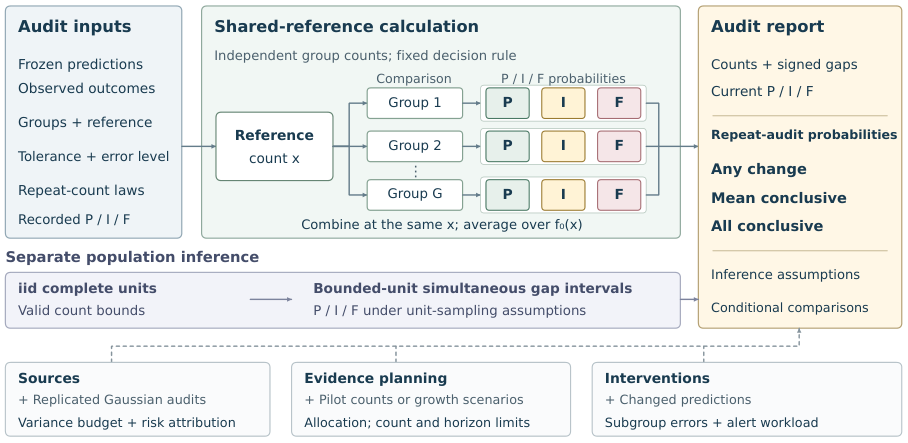

**Figure 1.** Shared-reference audit computation for disjoint independent count groups. Conditional state probabilities are averaged over the reference mass. C2 sensitivity and C3 allocation within a known positive frame retain separate assumptions: C2 does not set C3 allocations. The diagram's growth/horizon extensions remain unvalidated.

In [4]:
show_table('I')
show_table('II')
show_figure('1')

Table I describes the tasks addressed by related methods. A full circle means that the task is implemented in the cited formulation, a half circle means related or narrower support, and an empty circle means it is not reported there. These marks do not demonstrate superiority. Table II supplies the information and cost assumptions needed to interpret each branch of the pipeline.

## 2. Cohorts, models, parameters and data checks

Texas-100X predicts **length of stay greater than three days**. The two ICU cohorts predict hospital mortality after a 24-hour ICU landmark. Hospital-separated or patient-separated development partitions have different roles: training fits parameters, tuning chooses configurations, calibration fixes the operating threshold, and test predictions supply the audit inputs. All clinical analyses are exploratory because these cohorts had already been examined.

The code below checks partition arithmetic and reconstructs the main cohort table. Missing patient identifiers in Texas mean that hospital separation cannot establish patient separation. MIMIC-III has one institution; the repeated `1` in the hospital column does not mean one patient.

In [5]:
partitions = frame('partitions')
assert len(partitions) == 12
assert (partitions.positive_outcomes <= partitions.records).all()
analytic = partitions.groupby('dataset').records.sum()
assert analytic.to_dict() == {'eicu':111214, 'mimic':32315, 'texas':923754}
test = partitions.query("partition == 'test'").set_index('dataset')
assert test.records.to_dict() == {'eicu':20572, 'mimic':4848, 'texas':169933}
assert test.positive_outcomes.to_dict() == {'eicu':1792, 'mimic':541, 'texas':75316}
partition_display = partitions.copy()
for column in ['records', 'positive_outcomes', 'hospitals', 'patients', 'encounters']:
    missing = 'Unavailable' if column == 'patients' else 'Not recorded'
    partition_display[column] = partition_display[column].map(
        lambda value: missing if pd.isna(value) else f'{int(value):,}')
partition_display['dataset'] = partition_display.dataset.map(cohort_name)
partition_display['partition'] = partition_display.partition.map(
    {'train':'Training', 'tune':'Tuning', 'calibration':'Calibration', 'test':'Test'})
partition_display = partition_display.rename(columns={
    'dataset':'Cohort', 'partition':'Partition', 'records':'Records',
    'positive_outcomes':'Positive outcomes', 'hospitals':'Hospitals',
    'patients':'Unique patients', 'encounters':'Encounters'})
assert partition_display['Unique patients'].eq('Unavailable').sum() == 4
assert partition_display['Encounters'].eq('Not recorded').sum() == 8
assert not partition_display.isna().any().any()
display(partition_display.style.hide(axis='index'))
display(Markdown('**Unavailable:** Texas-100X has no patient-linkage identifiers, so unique patients cannot be counted. '
    '**Not recorded:** the partition export does not provide a separate encounter count for Texas-100X or MIMIC-III. '
    'Neither label means zero; the record counts are the analysis denominators.'))
display(frame('flow').style.format(na_rep='Not recorded', precision=0, thousands=',').hide(axis='index'))
show_table('III')
record('Main Table III', True, 'Reconstructed from all 12 partition records')
show_table('tab:hyperparameters', 'supplement')
display(frame('selected_xgb'))

Cohort,Partition,Records,Positive outcomes,Hospitals,Unique patients,Encounters
Texas-100X,Calibration,"98,212","42,923",66,Unavailable,Not recorded
Texas-100X,Test,"169,933","75,316",66,Unavailable,Not recorded
Texas-100X,Training,"549,370","251,498",241,Unavailable,Not recorded
Texas-100X,Tuning,"106,239","45,991",66,Unavailable,Not recorded
eICU,Calibration,"15,619","1,303",31,"13,718","15,619"
eICU,Test,"20,572","1,792",32,"18,118","20,572"
eICU,Training,"61,714","5,495",113,"54,181","61,714"
eICU,Tuning,"13,309","1,291",31,"11,939","13,309"
MIMIC-III,Calibration,"4,847",473,1,"4,847",Not recorded
MIMIC-III,Test,"4,848",541,1,"4,848",Not recorded


**Unavailable:** Texas-100X has no patient-linkage identifiers, so unique patients cannot be counted. **Not recorded:** the partition export does not provide a separate encounter count for Texas-100X or MIMIC-III. Neither label means zero; the record counts are the analysis denominators.

dataset,stage,n_remaining,n_excluded,hospitals
texas,raw discharge records,"925,128",0,441
texas,exclude suppressed hospital codes,"923,928","1,200",Not recorded
texas,exclude exact duplicate rows,"923,754",174,439
eicu,all_unit_stays,"200,859",0,208
eicu,available_linkage_and_relative_admission_time,"200,859",0,208
eicu,first_icu_stay_per_hospital_encounter,"166,355","34,504",208
eicu,known_adult_age,"165,795",560,208
eicu,still_in_icu_after_24h,"115,941","49,854",208
eicu,hospital_outcome_occurs_after_24h,"115,877",64,208
eicu,known_subsequent_hospital_outcome,"114,810","1,067",207


Cohort,"Analytic / sample, $n$","Test / sample, $n$",Test positives / $n$ (%)
Texas-100X,"923,754","169,933","75,316 (44.32)"
eICU,"111,214","20,572","1,792 (8.71)"
MIMIC-III,"32,315","4,848",541 (11.16)


Model,Search and fixed settings,Selected Texas / eICU / MIMIC,Optimization
Logistic regression,"$C\in\{0.1,1\}$; $L_2$ penalty; training-only standardization and sparse categorical encoding",$1/0.1/0.1$,"LBFGS; at most 1,000 iterations"
XGBoost,"Depth $\{3,6\}$; at most 1,000 trees; learning rate 0.05; row/column subsampling 0.8; child weight 10; $L_2=1$",Depth $6/6/6$,Histogram method; 40-round early stopping; four CPU threads or recorded GPU
MLP,"Two hidden layers; width $\{64,128\}$; ReLU; dropout 0.1",-- / 64 / 128,"AdamW; batches 2,048"
Residual network,"Two residual blocks; width $\{64,128\}$; dropout 0.1",-- / 128 / 128,"AdamW; batches 2,048"
Attention,"Two pre-normalized blocks; four heads; width $\{16,32\}$; GELU; dropout 0.1",-- / 32 / 16,AdamW; batches 256


,configuration,seed,selected_depth,best_iteration_zero_based,trees_used_for_prediction,threshold
0,texas_admission_diagnosis,11,6,999,1000,0.42192
1,eicu_primary,11,6,376,377,0.07371559
2,mimic_common_vitals,11,6,141,142,0.0834484


### 2.1 Complete training and audit configuration

Training-only preprocessing learns medians, missingness indicators, scaling and category vocabularies. The principal Texas model uses age code, admission type, admission source and admitting diagnosis. eICU uses 90 numeric and two categorical predictors; MIMIC-III uses 42 numeric predictors and constant context. The feature inventory below lists the recorded columns. Source recording times limit ICU inputs to information available by 24 hours; Texas prospective timing is unverified.

**Logistic regression:** search $C\in\{0.1,1\}$, $L_2$ regularization, LBFGS and at most 1,000 iterations. Selected $C$ values are 1, 0.1 and 0.1 for Texas, eICU and MIMIC.

**XGBoost:** search depth 3 or 6, maximum 1,000 trees, learning rate 0.05, row and column subsampling 0.8, minimum child weight 10 and $L_2=1$. Histogram fitting stops after 40 rounds without tuning-log-loss improvement. All selected depths are six. Seed-11 tree counts are 1,000, 377 and 142, with thresholds 0.421920, 0.073716 and 0.083448. The stored table gives unrounded thresholds. Seeds 29 and 47 provide conditional training sensitivities, not new cohorts.

**Neural comparators:** two-layer MLP and two-block residual network search widths 64/128, with dropout 0.1. Two attention blocks use four heads, pre-normalization, GELU and token widths 16/32. Selected MLP widths are 64/128, residual widths 128/128, and attention widths 32/16 for eICU/MIMIC. AdamW uses learning rate 0.001, weight decay 0.0001, binary cross-entropy with logits, at most 40 epochs, gradient norm cap one, patience six and minimum log-loss improvement $10^{-5}$. Training batches are 2,048 for MLP/ResNet and 256 for attention; prediction batches are 512.

Configuration selection maximizes tuning average precision. The selected within-configuration checkpoint minimizes tuning log loss. A separate calibration partition selects the highest threshold reaching 80% sensitivity. This is a declared research operating point, not a clinically endorsed threshold.

**Audit configuration:** family error 0.05, minimum denominator one and principal tolerance 0.10, with 0.05/0.15 sensitivity. Principal unit bootstraps use 9,999 draws, secondary families 1,999 and predictive intervals 500. These are separate from C–C's 1,999 and UM's 19,999 draws in the external-method comparison. Section 3 gives their exact definitions.

Training environment records specify Python 3.12.14, NumPy/pandas 2.3.3, SciPy 1.16.2, scikit-learn 1.7.2, XGBoost 3.0.5, joblib 1.6.0 and PyTorch 2.8.0 with CUDA 12.8 on an RTX 5070 Laptop GPU. Historical timing studies used a different Python/SciPy environment, stated in Section 3. Saved settings establish provenance; this notebook does not retrain those models.

In [6]:
display(frame('actual_predictor_columns'))
overlap = frame('partition_overlap')
required = overlap.expected_separate.astype(str).str.lower().eq('true')
assert overlap.loc[required, 'shared_ids'].eq(0).all()
preprocessing = frame('training_preprocessing_checks')
assert preprocessing.passed.astype(str).str.lower().eq('true').all()
display(overlap)
display(preprocessing)
record('Stored partition and preprocessing checks', True, 'Rechecked exported audit results; no raw patient join rerun')

,dataset,feature,role
0,texas,PAT_AGE,numeric
1,texas,TYPE_OF_ADMISSION,categorical
2,texas,SOURCE_OF_ADMISSION,categorical
3,texas,ADMITTING_DIAGNOSIS,categorical
4,eicu,age_topcoded,numeric
...,...,...,...
134,mimic,vital_noninvasive_map_min,numeric
135,mimic,vital_noninvasive_map_max,numeric
136,mimic,vital_noninvasive_map_last,numeric
137,mimic,vital_noninvasive_map_mean,numeric


,dataset,partition_a,partition_b,identifier,shared_ids,expected_separate
0,texas,train,tune,record_id,0,True
1,texas,train,tune,hospital_id,0,True
2,texas,train,calibration,record_id,0,True
3,texas,train,calibration,hospital_id,0,True
4,texas,train,test,record_id,0,True
5,texas,train,test,hospital_id,0,True
6,texas,tune,calibration,record_id,0,True
7,texas,tune,calibration,hospital_id,0,True
8,texas,tune,test,record_id,0,True
9,texas,tune,test,hospital_id,0,True


,dataset,statistic,features,max_absolute_difference,passed
0,texas,imputer_medians,1,0,True
1,texas,scaler_means,1,0,True
2,texas,scaler_variances,1,0,True
3,texas,scaler_scale,1,0,True
4,eicu,imputer_medians,90,0,True
5,eicu,scaler_means,90,0,True
6,eicu,scaler_variances,90,0,True
7,eicu,scaler_scale,90,0,True
8,mimic,imputer_medians,42,0,True
9,mimic,scaler_means,42,0,True


### 2.2 Protected groups and prediction performance

Race and ethnicity retain their source-specific definitions. Texas separates race from Hispanic ethnicity; eICU combines ethnicity categories; MIMIC preserves all 41 source ethnicity labels. Reference categories are White, Caucasian and WHITE respectively. Missing or unknown identities remain recorded categories. A small group count establishes sparse evidence, not clinical vulnerability by itself. The full category table and all comparison numerators and denominators are included.

The next cell recomputes sensitivity, specificity, accuracy, positive predictive value and alert fraction from confusion counts. AUROC, average precision, calibration and bootstrap intervals require scores or resamples and are retained as saved results. This distinction prevents count-based checks from being mistaken for score reconstruction.

,dataset,attribute,group,is_reference,records,positive_outcomes,negative_outcomes,missed_positives,false_positives,positive_classifications
0,texas,sex,Male,True,60362,31312,29050,4872,15275,41715
1,texas,sex,Female,False,109571,44004,65567,8435,18548,54117
2,texas,age_group,40-64,True,53890,24873,29017,5048,12670,32495
3,texas,age_group,0-17,False,5686,1528,4158,942,644,1230
4,texas,age_group,18-39,False,46505,8925,37580,5060,3288,7153
...,...,...,...,...,...,...,...,...,...,...
100,mimic,sex_by_age,Female|65-79,False,637,78,559,12,216,282
101,mimic,sex_by_age,Female|80+,False,587,108,479,12,303,399
102,mimic,sex_by_age,Male|18-39,False,287,14,273,7,34,41
103,mimic,sex_by_age,Male|65-79,False,862,88,774,20,268,336


,dataset,attribute,metric,reference,group,n,k,n0,k0
0,texas,sex,fnr,Male,Female,44004,8435,31312,4872
1,texas,sex,fpr,Male,Female,65567,18548,29050,15275
2,texas,sex,spd,Male,Female,109571,54117,60362,41715
3,texas,age_group,fnr,40-64,0-17,1528,942,24873,5048
4,texas,age_group,fnr,40-64,18-39,8925,5060,24873,5048
...,...,...,...,...,...,...,...,...,...
271,mimic,sex_by_age,spd,Male|40-64,Female|65-79,637,282,1153,290
272,mimic,sex_by_age,spd,Male|40-64,Female|80+,587,399,1153,290
273,mimic,sex_by_age,spd,Male|40-64,Male|18-39,287,41,1153,290
274,mimic,sex_by_age,spd,Male|40-64,Male|65-79,862,336,1153,290


,dataset,family,seed,threshold,auroc,auprc,sensitivity,specificity,ppv,accuracy,alert_fraction
0,texas,lr,11,0.4266169,0.8183967,0.7569546,0.806004,0.6763689,0.6647067,0.7338245,0.5374236
1,texas,xgb,11,0.42192,0.8105894,0.7470257,0.8233178,0.6425272,0.6470594,0.7226554,0.5639399
3,eicu,lr,11,0.07012583,0.8161598,0.3721209,0.7979911,0.6682109,0.1866597,0.6795158,0.3723994
4,eicu,xgb,11,0.07371559,0.8377994,0.398186,0.7840402,0.729606,0.2167207,0.7343477,0.3151371
5,eicu,mlp,11,0.07074247,0.8273861,0.3778571,0.7996652,0.6885517,0.1967866,0.6982306,0.3539763
6,eicu,resnet,11,0.08141733,0.8272286,0.3822571,0.7935268,0.692279,0.1974726,0.7010986,0.3500389
7,eicu,attention,11,0.08162383,0.8276523,0.3877644,0.8158482,0.6701278,0.1909364,0.6828213,0.3722049
9,mimic,lr,11,0.07524108,0.7378158,0.3048078,0.780037,0.5347109,0.1739489,0.5620875,0.5004125
10,mimic,xgb,11,0.0834484,0.7953162,0.3666083,0.7707948,0.6661249,0.2247978,0.6778053,0.382632
11,mimic,mlp,11,0.0879598,0.7886285,0.3606984,0.7689464,0.6538194,0.2181437,0.6666667,0.3933581


,dataset,seed,records,events,units,brier,brier_low,brier_high,mean_probability,prevalence,calibration_intercept,calibration_slope
0,texas,11,169933,75316,66,0.1764608,0.164454,0.1868154,0.4537944,0.44321,-0.05330866,1.139981
1,texas,29,169933,75316,66,0.1764638,0.1644803,0.1867928,0.4537014,0.44321,-0.05288931,1.138388
2,texas,47,169933,75316,66,0.1764465,0.1644378,0.1868087,0.4534954,0.44321,-0.05167208,1.138008
3,eicu,11,20572,1792,25,0.06461427,0.05395575,0.07673862,0.08487597,0.08710869,0.003700218,0.9828883
4,eicu,29,20572,1792,25,0.06474086,0.05427599,0.07672411,0.08509072,0.08710869,0.04283254,1.005759
5,eicu,47,20572,1792,25,0.06474086,0.05438068,0.07665925,0.08493922,0.08710869,0.01993469,0.9922084
6,mimic,11,4848,541,4848,0.08458951,0.0789688,0.09031382,0.1035334,0.1115924,0.1039797,1.002708
7,mimic,29,4848,541,4848,0.0848865,0.07926205,0.09070168,0.103378,0.1115924,0.07993764,0.9881072
8,mimic,47,4848,541,4848,0.08451056,0.07891948,0.09021885,0.1040108,0.1115924,0.06981808,0.9867388


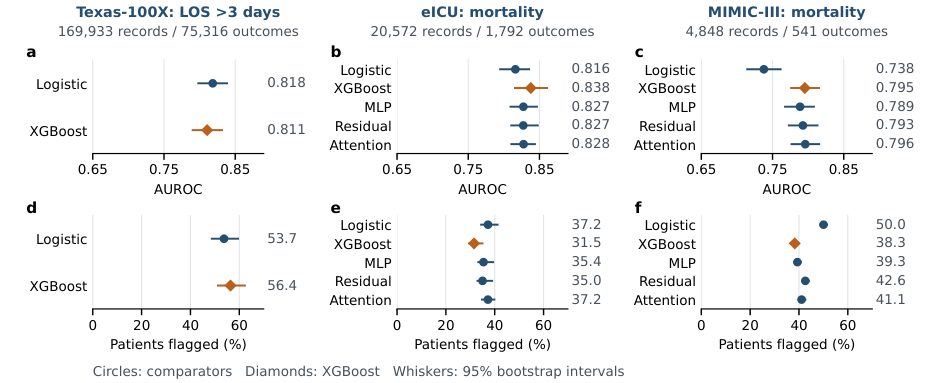

**Figure 2.** Predictive performance by cohort: (a--c) AUROC; (d--f) percentage flagged. Diamonds: principal XGBoost fits; whiskers: 95% paired-bootstrap intervals.

In [7]:
display(frame('categories'))
display(frame('comparisons')[['dataset','attribute','metric','reference','group','n','k','n0','k0']])
predictive = frame('predictive').query("family != 'always_negative'").dropna(subset=['seed']).copy()
predictive = predictive[predictive.family.isin(['lr','xgb','mlp','resnet','attention'])]
assert len(predictive) == 12
for metric, numerator, denominator in [
    ('sensitivity',predictive.tp,predictive.tp+predictive.fn),
    ('specificity',predictive.tn,predictive.tn+predictive.fp),
    ('accuracy',predictive.tp+predictive.tn,predictive.n),
    ('alert_fraction',predictive.tp+predictive.fp,predictive.n)]:
    np.testing.assert_allclose(predictive[metric], numerator/denominator, atol=1e-12)
predictive['ppv'] = predictive.tp/(predictive.tp+predictive.fp)
display(predictive[['dataset','family','seed','threshold','auroc','auprc','sensitivity','specificity','ppv','accuracy','alert_fraction']])
display(frame('calibration'))
record('Predictive confusion-count consistency', True, '12 frozen fits; score metrics retained from recorded evaluations')
show_figure('2')

In [8]:
data = json.loads(r'''
{
"Texas counts": [
{"group":"Asian","n":540,"k":111,"n0":52770,"k0":8496},
{"group":"Black","n":9779,"k":1734,"n0":52770,"k0":8496},
{"group":"Native American","n":75,"k":12,"n0":52770,"k0":8496},
{"group":"Other","n":12152,"k":2954,"n0":52770,"k0":8496}
],
"principal forecasts": [
{"dataset":"texas","law":"plugin_binomial","r_any":0.538038524443234,"c_mean":0.593650240262353,"c_all":6.9814652e-08},
{"dataset":"texas","law":"jeffreys_predictive","r_any":0.598158873341542,"c_mean":0.568716868869258,"c_all":0.000137916654474},
{"dataset":"eicu","law":"plugin_binomial","r_any":0.003612885596984,"c_mean":0.000602227970102,"c_all":1.32804338330838e-192},
{"dataset":"eicu","law":"jeffreys_predictive","r_any":0.034476441644052,"c_mean":0.005777262155403,"c_all":1.60698727028648e-20},
{"dataset":"mimic","law":"plugin_binomial","r_any":0.005074980011256,"c_mean":0.000126878329239,"c_all":0.0},
{"dataset":"mimic","law":"jeffreys_predictive","r_any":0.028281928304662,"c_mean":0.000710077453581,"c_all":0.0}
],
"feasibility": [
{"dataset":"texas","declared_comparisons":4,"zero_support":0,"supported_no_conclusive_configuration":0,"potentially_conclusive":4,"pass_incapable":0,"observed_pass":3,"observed_inconclusive":1,"observed_fail":0},
{"dataset":"eicu","declared_comparisons":6,"zero_support":0,"supported_no_conclusive_configuration":0,"potentially_conclusive":6,"pass_incapable":3,"observed_pass":0,"observed_inconclusive":6,"observed_fail":0},
{"dataset":"mimic","declared_comparisons":40,"zero_support":23,"supported_no_conclusive_configuration":11,"potentially_conclusive":6,"pass_incapable":39,"observed_pass":0,"observed_inconclusive":40,"observed_fail":0}
],
"timing prefixes": [
{"method":"run_compressed","queries":1,"setup_seconds":2.426171900006011,"law_generation_seconds":0.300534597598016,"integration_seconds":0.215201902203262,"setup_laws_integration_seconds":2.941908399807289},
{"method":"run_compressed","queries":10,"setup_seconds":2.426171900006011,"law_generation_seconds":3.366390395443886,"integration_seconds":2.424916604300961,"setup_laws_integration_seconds":8.217478899750859},
{"method":"run_compressed","queries":100,"setup_seconds":2.426171900006011,"law_generation_seconds":34.6394273317419,"integration_seconds":23.349219569237903,"setup_laws_integration_seconds":60.41481880098581},
{"method":"indexed","queries":1,"setup_seconds":2.408872900065034,"law_generation_seconds":0.374950101831928,"integration_seconds":12.070081098470837,"setup_laws_integration_seconds":14.8539041003678},
{"method":"indexed","queries":10,"setup_seconds":2.408872900065034,"law_generation_seconds":5.234946001088247,"integration_seconds":144.3004088990856,"setup_laws_integration_seconds":151.94422780023888},
{"method":"direct","queries":1,"setup_seconds":3.085751200094819,"law_generation_seconds":0.571725201560184,"integration_seconds":83.55436889827251,"setup_laws_integration_seconds":87.21184529992752}
],
"candidate timings": [
{"cohort":"texas","repeat":0,"method":"run_compressed","completed_queries":4,"computation_seconds":0.437709899997572},
{"cohort":"texas","repeat":0,"method":"indexed","completed_queries":4,"computation_seconds":0.244204600006924},
{"cohort":"texas","repeat":0,"method":"direct","completed_queries":4,"computation_seconds":1.272680300025968},
{"cohort":"texas","repeat":1,"method":"indexed","completed_queries":4,"computation_seconds":0.433486299982178},
{"cohort":"texas","repeat":1,"method":"direct","completed_queries":4,"computation_seconds":1.69949239998823},
{"cohort":"texas","repeat":1,"method":"run_compressed","completed_queries":4,"computation_seconds":0.257600799988722},
{"cohort":"texas","repeat":2,"method":"direct","completed_queries":4,"computation_seconds":1.608017899998231},
{"cohort":"texas","repeat":2,"method":"run_compressed","completed_queries":4,"computation_seconds":0.364231400002609},
{"cohort":"texas","repeat":2,"method":"indexed","completed_queries":4,"computation_seconds":0.303058500008774},
{"cohort":"texas","repeat":3,"method":"run_compressed","completed_queries":4,"computation_seconds":0.29211719999148},
{"cohort":"texas","repeat":3,"method":"indexed","completed_queries":4,"computation_seconds":0.375261199980741},
{"cohort":"texas","repeat":3,"method":"direct","completed_queries":4,"computation_seconds":2.011697699999786},
{"cohort":"texas","repeat":4,"method":"indexed","completed_queries":4,"computation_seconds":0.399794100012514},
{"cohort":"texas","repeat":4,"method":"direct","completed_queries":4,"computation_seconds":1.606752899999265},
{"cohort":"texas","repeat":4,"method":"run_compressed","completed_queries":4,"computation_seconds":0.289913600005093},
{"cohort":"eicu","repeat":0,"method":"indexed","completed_queries":62,"computation_seconds":0.184538300032727},
{"cohort":"eicu","repeat":0,"method":"direct","completed_queries":62,"computation_seconds":0.19379330004449},
{"cohort":"eicu","repeat":0,"method":"run_compressed","completed_queries":62,"computation_seconds":0.188089400005992},
{"cohort":"eicu","repeat":1,"method":"direct","completed_queries":62,"computation_seconds":0.164648800113355},
{"cohort":"eicu","repeat":1,"method":"run_compressed","completed_queries":62,"computation_seconds":0.257209700066596},
{"cohort":"eicu","repeat":1,"method":"indexed","completed_queries":62,"computation_seconds":0.139487999971607},
{"cohort":"eicu","repeat":2,"method":"run_compressed","completed_queries":62,"computation_seconds":0.142433699962567},
{"cohort":"eicu","repeat":2,"method":"indexed","completed_queries":62,"computation_seconds":0.195570399955614},
{"cohort":"eicu","repeat":2,"method":"direct","completed_queries":62,"computation_seconds":0.224866199976532},
{"cohort":"eicu","repeat":3,"method":"indexed","completed_queries":62,"computation_seconds":0.151425400050357},
{"cohort":"eicu","repeat":3,"method":"direct","completed_queries":62,"computation_seconds":0.189451700032805},
{"cohort":"eicu","repeat":3,"method":"run_compressed","completed_queries":62,"computation_seconds":0.136800400097854},
{"cohort":"eicu","repeat":4,"method":"direct","completed_queries":62,"computation_seconds":0.231729300066945},
{"cohort":"eicu","repeat":4,"method":"run_compressed","completed_queries":62,"computation_seconds":0.170944900019094},
{"cohort":"eicu","repeat":4,"method":"indexed","completed_queries":62,"computation_seconds":0.214659799996298},
{"cohort":"mimic","repeat":0,"method":"direct","completed_queries":62,"computation_seconds":0.231103999976767},
{"cohort":"mimic","repeat":0,"method":"run_compressed","completed_queries":62,"computation_seconds":0.429219700003159},
{"cohort":"mimic","repeat":0,"method":"indexed","completed_queries":62,"computation_seconds":0.467473899960169},
{"cohort":"mimic","repeat":1,"method":"run_compressed","completed_queries":62,"computation_seconds":0.427657799897133},
{"cohort":"mimic","repeat":1,"method":"indexed","completed_queries":62,"computation_seconds":0.320001000087359},
{"cohort":"mimic","repeat":1,"method":"direct","completed_queries":62,"computation_seconds":0.251758199970936},
{"cohort":"mimic","repeat":2,"method":"indexed","completed_queries":62,"computation_seconds":0.493126599947573},
{"cohort":"mimic","repeat":2,"method":"direct","completed_queries":62,"computation_seconds":0.328720500023337},
{"cohort":"mimic","repeat":2,"method":"run_compressed","completed_queries":62,"computation_seconds":0.333699099937803},
{"cohort":"mimic","repeat":3,"method":"direct","completed_queries":62,"computation_seconds":0.295276300021214},
{"cohort":"mimic","repeat":3,"method":"run_compressed","completed_queries":62,"computation_seconds":0.284825399867259},
{"cohort":"mimic","repeat":3,"method":"indexed","completed_queries":62,"computation_seconds":0.404470000139554},
{"cohort":"mimic","repeat":4,"method":"run_compressed","completed_queries":62,"computation_seconds":0.279272400148329},
{"cohort":"mimic","repeat":4,"method":"indexed","completed_queries":62,"computation_seconds":0.375910400005523},
{"cohort":"mimic","repeat":4,"method":"direct","completed_queries":62,"computation_seconds":0.433582400015439}
],
"candidate verification": {"unique_candidates": 64, "unique_queries": 128, "matched_completed_calls": 1920, "maximum_absolute_output_difference": 2.220446049250313e-15},
"source fits": [
{"dataset":"texas","supported_hospitals":58,"mean_gap":0.042706553085944,"site_variance":0.004351007948735,"sampling_constant":0.273856297722913,"observed_cell_sampling_variance":0.002368445056935,"observed_cell_site_shapley":0.184854430031589,"observed_cell_sampling_shapley":0.098290746399086,"risk_at_n500":0.227240146320487},
{"dataset":"eicu","supported_hospitals":9,"mean_gap":-0.038902968651551,"site_variance":0.000424361062005,"sampling_constant":0.33975168360992,"observed_cell_sampling_variance":0.006243121640002,"observed_cell_site_shapley":0.007032697700981,"observed_cell_sampling_shapley":0.264587756786727,"risk_at_n500":0.032978190512744}
],
"planning": [
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.003450172982631,"target_upper":0.897391226263807,"target_truth":0.377653327576647,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.377652811508288,"baseline_correct":0.377652811508288},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.005347491450102,"target_upper":0.980382317859823,"target_truth":0.364485638178253,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.364485270935968,"baseline_correct":0.364485270935968},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.004550148856112,"target_upper":0.977003405260422,"target_truth":0.376526439071816,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.376526080753297,"baseline_correct":0.376526080753297},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.005416981012305,"target_upper":0.866810078966435,"target_truth":0.371676385597276,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.371676016382043,"baseline_correct":0.371676016382043},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.003505516195812,"target_upper":0.985681652044529,"target_truth":0.37646062316029,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.376460346946335,"baseline_correct":0.376460346946335},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.004001181402143,"target_upper":0.997978071966517,"target_truth":0.377681289117425,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.377681061163662,"baseline_correct":0.377681061163662},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.005334442908977,"target_upper":0.863573286865228,"target_truth":0.375720128611124,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.375719889571913,"baseline_correct":0.375719889571913},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.003921578398153,"target_upper":0.861495025221788,"target_truth":0.380074079303962,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.380073469889156,"baseline_correct":0.380073469889156},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.004553484454767,"target_upper":0.972456260464446,"target_truth":0.372666178301711,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.372665855625454,"baseline_correct":0.372665855625454},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.003853336985617,"target_upper":0.997580435694745,"target_truth":0.376105998934142,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.376105701747972,"baseline_correct":0.376105701747972},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.003887180451495,"target_upper":0.846504017230143,"target_truth":0.363498394649958,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.363498209662835,"baseline_correct":0.363498209662835},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.005357857898711,"target_upper":0.935595256126916,"target_truth":0.366921761520279,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.366921394035631,"baseline_correct":0.366921394035631},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.00478394211778,"target_upper":0.863810726499987,"target_truth":0.361331314315041,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.361331039844003,"baseline_correct":0.361331039844003},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.004800728815783,"target_upper":0.952117002730724,"target_truth":0.372525259506745,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.372524769639116,"baseline_correct":0.372524769639116},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.003921578398153,"target_upper":0.861495025221788,"target_truth":0.380074079303962,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.380073469889156,"baseline_correct":0.380073469889156},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.004624460013162,"target_upper":0.975549174436182,"target_truth":0.365214312035451,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.365214184628806,"baseline_correct":0.365214184628806},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.00462445998939,"target_upper":0.975528590892519,"target_truth":0.365214327562692,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.365214183639143,"baseline_correct":0.365214183639143},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.003725304116685,"target_upper":0.999021967094274,"target_truth":0.376567944267325,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.376567654702202,"baseline_correct":0.376567654702202},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.004690532275198,"target_upper":0.889362445162708,"target_truth":0.36875779624122,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.368757326876539,"baseline_correct":0.368757326876539},
{"dataset":"eicu","pilot_cap":200,"budget":250,"reviews":661,"target":0.1,"target_lower":0.003847371629272,"target_upper":0.977659782293126,"target_truth":0.376423904125119,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.376423683791347,"baseline_correct":0.376423683791347},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.00351589033357,"target_upper":0.999999978707579,"target_truth":0.24227514486274,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.242273981782552,"baseline_correct":0.242273981782552},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.003156595637042,"target_upper":0.999999157471295,"target_truth":0.253549801805927,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.253549151100306,"baseline_correct":0.253549151100306},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.003156595641914,"target_upper":0.999999156680554,"target_truth":0.274318377177832,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.274317726472642,"baseline_correct":0.274317726472642},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.004114656612075,"target_upper":0.998959144784667,"target_truth":0.274437268585012,"correct_gain_lower":-0.169690911307512,"correct_gain_upper":0.318009933572399,"identical":false,"dp_correct":0.27443675300589,"baseline_correct":0.246769790032543},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.00354664010711,"target_upper":1.0,"target_truth":0.253163665549916,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.253163110010025,"baseline_correct":0.253163110010025},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.004114656972646,"target_upper":0.999867408589765,"target_truth":0.274437055408948,"correct_gain_lower":-0.336359416865068,"correct_gain_upper":0.471444347794111,"identical":false,"dp_correct":0.274436753005902,"baseline_correct":0.246769790032649},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.003365283117704,"target_upper":0.999999857849216,"target_truth":0.274437055797497,"correct_gain_lower":-0.169692737458476,"correct_gain_upper":0.317934234457514,"identical":false,"dp_correct":0.27443675300591,"baseline_correct":0.244500263203847},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.003555108762349,"target_upper":0.99999937961745,"target_truth":0.258905442003121,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.258904535083177,"baseline_correct":0.258904535083177},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.003696174629805,"target_upper":0.999974323306552,"target_truth":0.266587580836708,"correct_gain_lower":-0.334301631739983,"correct_gain_upper":0.466730967359774,"identical":false,"dp_correct":0.266586970578115,"baseline_correct":0.254251880475718},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.00350085485919,"target_upper":0.999999996301029,"target_truth":0.242393775523703,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.242392615127457,"baseline_correct":0.242392615127457},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.004114656972646,"target_upper":0.999867408589765,"target_truth":0.274437055408948,"correct_gain_lower":-0.336359416865068,"correct_gain_upper":0.471444347794111,"identical":false,"dp_correct":0.274436753005902,"baseline_correct":0.246769790032649},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.004114661650515,"target_upper":0.999999843334341,"target_truth":0.274437259140547,"correct_gain_lower":-0.336357979583594,"correct_gain_upper":0.47225966350022,"identical":false,"dp_correct":0.274436753006284,"baseline_correct":0.244500263203739},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.00336365282497,"target_upper":0.999862239427744,"target_truth":0.274437055448883,"correct_gain_lower":-0.336359416865068,"correct_gain_upper":0.471444347794111,"identical":false,"dp_correct":0.274436753006296,"baseline_correct":0.246769790032649},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.004114660988313,"target_upper":0.999944737863252,"target_truth":0.274437259100612,"correct_gain_lower":-0.336357979583594,"correct_gain_upper":0.47225966350022,"identical":false,"dp_correct":0.27443675300589,"baseline_correct":0.244500263203739},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.002577211122699,"target_upper":0.999999786451591,"target_truth":0.242345936363337,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.242344775090646,"baseline_correct":0.242344775090646},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.003555108233776,"target_upper":0.99999937961745,"target_truth":0.24234565012711,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.242344778406939,"baseline_correct":0.242344778406939},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.003057505911162,"target_upper":0.999998410559503,"target_truth":0.255019636272908,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.255018939522535,"baseline_correct":0.255018939522535},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.003351778291786,"target_upper":0.99999999661099,"target_truth":0.276530981736683,"correct_gain_lower":-0.336256626329487,"correct_gain_upper":0.468889891454474,"identical":false,"dp_correct":0.276530747494404,"baseline_correct":0.256449819751285},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.003765005150859,"target_upper":1.0,"target_truth":0.243681730756108,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.243681105516803,"baseline_correct":0.243681105516803},
{"dataset":"eicu","pilot_cap":20,"budget":250,"reviews":475,"target":0.1,"target_lower":0.00305750719138,"target_upper":0.999998912478921,"target_truth":0.243831520139522,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.243830792201393,"baseline_correct":0.243830792201393},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.075639581398886,"target_upper":0.425,"target_truth":0.400024868212764,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.4000247789918,"baseline_correct":0.4000247789918},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.075310614846709,"target_upper":0.425,"target_truth":0.40003060907906,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.40003060907906,"baseline_correct":0.40003060907906},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.050360329963933,"target_upper":0.425,"target_truth":0.400011646422793,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.400011646422793,"baseline_correct":0.400011646422793},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.300291702275134,"target_upper":0.425,"target_truth":0.400009370904042,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.400009370904042,"baseline_correct":0.400009370904042},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.289134609559438,"target_upper":0.425,"target_truth":0.40003060907906,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.40003060907906,"baseline_correct":0.40003060907906},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.075489442827508,"target_upper":0.425,"target_truth":0.400024860508685,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.4000247789918,"baseline_correct":0.4000247789918},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.075816861258939,"target_upper":0.425,"target_truth":0.400012092533944,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.400006481887587,"baseline_correct":0.400006481887587},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.050362384004494,"target_upper":0.425,"target_truth":0.400009370904042,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.400009370904042,"baseline_correct":0.400009370904042},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.050425122963761,"target_upper":0.425,"target_truth":0.400009370904042,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.400009370904042,"baseline_correct":0.400009370904042},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.075639581398886,"target_upper":0.425,"target_truth":0.400009370904042,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.400009370904042,"baseline_correct":0.400009370904042},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.300310223060857,"target_upper":0.425,"target_truth":0.400012978589234,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.400012978589234,"baseline_correct":0.400012978589234},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.300310223060857,"target_upper":0.425,"target_truth":0.400009370904042,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.400009370904042,"baseline_correct":0.400009370904042},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.300257160362181,"target_upper":0.425,"target_truth":0.400024836819474,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.4000247789918,"baseline_correct":0.4000247789918},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.300274023343308,"target_upper":0.425,"target_truth":0.40003060907906,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.40003060907906,"baseline_correct":0.40003060907906},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.050494563768098,"target_upper":0.425,"target_truth":0.400009370904042,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.400009370904042,"baseline_correct":0.400009370904042},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.300291702275134,"target_upper":0.425,"target_truth":0.400024843079036,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.4000247789918,"baseline_correct":0.4000247789918},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.075513104941474,"target_upper":0.425,"target_truth":0.400011646422793,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.400011646422793,"baseline_correct":0.400011646422793},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.300291702275134,"target_upper":0.425,"target_truth":0.40003060907906,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.40003060907906,"baseline_correct":0.40003060907906},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.075663119614949,"target_upper":0.425,"target_truth":0.400011646422793,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.400011646422793,"baseline_correct":0.400011646422793},
{"dataset":"mimic","pilot_cap":200,"budget":250,"reviews":508,"target":0.1,"target_lower":0.075310614846709,"target_upper":0.425,"target_truth":0.40003060907906,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.40003060907906,"baseline_correct":0.40003060907906},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.003614788137156,"target_upper":0.425,"target_truth":0.399110229113478,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.399110229113462,"baseline_correct":0.399110229113462},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.007776133634296,"target_upper":0.425,"target_truth":0.398953820205067,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.398953820205035,"baseline_correct":0.398953820205035},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.007776133634286,"target_upper":0.425,"target_truth":0.39895417207153,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.398954172071498,"baseline_correct":0.398954172071498},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.007776133634286,"target_upper":0.425,"target_truth":0.39895417207153,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.398954172071498,"baseline_correct":0.398954172071498},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.007429674179731,"target_upper":0.425,"target_truth":0.399110853583542,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.399110853583521,"baseline_correct":0.399110853583521},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.005454809690196,"target_upper":0.425,"target_truth":0.398778803361528,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.398778803361468,"baseline_correct":0.398778803361468},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.004017722238296,"target_upper":0.425,"target_truth":0.398954843584988,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.398954843584956,"baseline_correct":0.398954843584956},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.006922275517848,"target_upper":0.425,"target_truth":0.3987624771704,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.398762477170365,"baseline_correct":0.398762477170365},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.007429674179731,"target_upper":0.425,"target_truth":0.399111197425006,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.399111197424989,"baseline_correct":0.399111197424989},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.002398376162208,"target_upper":0.425,"target_truth":0.398778384933145,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.398778384933085,"baseline_correct":0.398778384933085},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.007429674179731,"target_upper":0.425,"target_truth":0.399111197425006,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.399111197424989,"baseline_correct":0.399111197424989},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.008327787866909,"target_upper":0.425,"target_truth":0.39876122318581,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.398761223185775,"baseline_correct":0.398761223185775},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.007776133634286,"target_upper":0.425,"target_truth":0.398954843584988,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.398954843584956,"baseline_correct":0.398954843584956},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.002398376162208,"target_upper":0.425,"target_truth":0.398778384933145,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.398778384933085,"baseline_correct":0.398778384933085},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.005404648562035,"target_upper":0.425,"target_truth":0.39895417207153,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.398954172071498,"baseline_correct":0.398954172071498},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.001230734672218,"target_upper":0.425,"target_truth":0.399111197425006,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.399111197424989,"baseline_correct":0.399111197424989},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.008141371766625,"target_upper":0.425,"target_truth":0.39877938495393,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.39877938495387,"baseline_correct":0.39877938495387},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.008819797054758,"target_upper":0.425,"target_truth":0.398557377589352,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.398557377589285,"baseline_correct":0.398557377589285},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.00881491439275,"target_upper":0.425,"target_truth":0.398580585874124,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.398580585874012,"baseline_correct":0.398580585874012},
{"dataset":"mimic","pilot_cap":20,"budget":250,"reviews":435,"target":0.1,"target_lower":0.228250169082626,"target_upper":0.425,"target_truth":0.39910511862346,"correct_gain_lower":0.0,"correct_gain_upper":0.0,"identical":true,"dp_correct":0.399105118620848,"baseline_correct":0.399105118620848},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":1.0539410258e-05,"target_upper":0.767348603959251,"target_truth":0.432215123679906,"correct_gain_lower":-0.956566432551966,"correct_gain_upper":0.767348603959251,"identical":false,"dp_correct":0.432100580635393,"baseline_correct":0.300649464058966},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":1.43130678e-07,"target_upper":0.777450077095719,"target_truth":0.43808143839549,"correct_gain_lower":-0.998556259810475,"correct_gain_upper":0.777450077095719,"identical":false,"dp_correct":0.437964037537147,"baseline_correct":0.304590006783874},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":7.00941045e-07,"target_upper":0.637842885563586,"target_truth":0.434386630661973,"correct_gain_lower":-0.746385897683238,"correct_gain_upper":0.637842885563586,"identical":false,"dp_correct":0.434277058097514,"baseline_correct":0.300797524966205},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":8.8692706e-08,"target_upper":0.76336463832917,"target_truth":0.435640415449464,"correct_gain_lower":-0.971417161432659,"correct_gain_upper":0.76336463832917,"identical":false,"dp_correct":0.435527560914769,"baseline_correct":0.304104973439966},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":8.468681966e-06,"target_upper":0.764823048958407,"target_truth":0.23806920261569,"correct_gain_lower":-0.97578864316087,"correct_gain_upper":0.764823048958407,"identical":false,"dp_correct":0.238065188501922,"baseline_correct":0.305675772306452},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":5.45426873e-07,"target_upper":0.559609549178791,"target_truth":0.433476768821242,"correct_gain_lower":-0.737945619850152,"correct_gain_upper":0.559609549178791,"identical":false,"dp_correct":0.433373579106236,"baseline_correct":0.300285681902861},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":1.3017908064e-05,"target_upper":0.751239837587592,"target_truth":0.434262333871518,"correct_gain_lower":-0.923202402982587,"correct_gain_upper":0.751239837587592,"identical":false,"dp_correct":0.434149388098236,"baseline_correct":0.301244561363053},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":5.064959688e-06,"target_upper":0.748469174602986,"target_truth":0.438067144278881,"correct_gain_lower":-0.932048686051223,"correct_gain_upper":0.748469174602986,"identical":false,"dp_correct":0.437953909514366,"baseline_correct":0.30084876193567},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":1.0886637e-08,"target_upper":0.648660324085091,"target_truth":0.43491873345695,"correct_gain_lower":-0.779276506226795,"correct_gain_upper":0.648660324085091,"identical":false,"dp_correct":0.434813738147551,"baseline_correct":0.301501015966711},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":7.0751745e-08,"target_upper":0.753033973188278,"target_truth":0.435547976532643,"correct_gain_lower":-0.93313391784268,"correct_gain_upper":0.753033973188278,"identical":false,"dp_correct":0.435437265625421,"baseline_correct":0.301925771261905},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":2.70126109e-07,"target_upper":0.613664495674894,"target_truth":0.434708579889371,"correct_gain_lower":-0.784034679161266,"correct_gain_upper":0.613664495674894,"identical":false,"dp_correct":0.434594507003362,"baseline_correct":0.303692872069616},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":5.3723323e-08,"target_upper":0.731244954055713,"target_truth":0.434344270512794,"correct_gain_lower":-0.902611038002208,"correct_gain_upper":0.731244954055713,"identical":false,"dp_correct":0.434228035082584,"baseline_correct":0.303662106829713},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":2.89538362e-07,"target_upper":0.635556659731202,"target_truth":0.434419364928054,"correct_gain_lower":-0.738488319785643,"correct_gain_upper":0.635556659731202,"identical":false,"dp_correct":0.434310323883881,"baseline_correct":0.302592187614936},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":1.3002731136e-05,"target_upper":0.958060528869869,"target_truth":0.366690877558178,"correct_gain_lower":-0.939207695676618,"correct_gain_upper":0.958060528869869,"identical":false,"dp_correct":0.366688939829092,"baseline_correct":0.301410166472695},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":7.3777528e-08,"target_upper":0.769996525307267,"target_truth":0.434265256235484,"correct_gain_lower":-0.98075862480623,"correct_gain_upper":0.769996525307267,"identical":false,"dp_correct":0.434154649123522,"baseline_correct":0.300101159151586},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":1.336985932e-06,"target_upper":0.915177494712989,"target_truth":0.329089014527772,"correct_gain_lower":-0.923524150287052,"correct_gain_upper":0.915177494712989,"identical":false,"dp_correct":0.329087862643144,"baseline_correct":0.300286994705799},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":1.588315882e-06,"target_upper":0.621636576843901,"target_truth":0.435402179685132,"correct_gain_lower":-0.664153523545659,"correct_gain_upper":0.621636576843901,"identical":false,"dp_correct":0.435294057483877,"baseline_correct":0.302362059905782},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":2.7845997e-08,"target_upper":0.721293473352628,"target_truth":0.435922134647165,"correct_gain_lower":-0.913130207735838,"correct_gain_upper":0.721293473352628,"identical":false,"dp_correct":0.435815677397689,"baseline_correct":0.302810053102876},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":9.1460257e-08,"target_upper":0.74646959586992,"target_truth":0.435344391177208,"correct_gain_lower":-0.896727282919313,"correct_gain_upper":0.74646959586992,"identical":false,"dp_correct":0.435236490870572,"baseline_correct":0.302230816507232},
{"dataset":"texas","pilot_cap":200,"budget":2000,"reviews":2878,"target":0.1,"target_lower":5.96113278e-07,"target_upper":0.593820615962656,"target_truth":0.435904221246314,"correct_gain_lower":-0.726780952002846,"correct_gain_upper":0.593820615962656,"identical":false,"dp_correct":0.435797011027491,"baseline_correct":0.304817274549624},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":3.5409757e-08,"target_upper":0.280130854133833,"target_truth":4.0677186917e-05,"correct_gain_lower":-0.299397562815066,"correct_gain_upper":0.280130854133833,"identical":false,"dp_correct":0.0,"baseline_correct":2.7049e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":2.5087182e-08,"target_upper":0.285863787509404,"target_truth":4.0128899012e-05,"correct_gain_lower":-0.319905071296036,"correct_gain_upper":0.285863787509404,"identical":false,"dp_correct":0.0,"baseline_correct":1.64765e-10},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":7.533439e-09,"target_upper":0.075999964316096,"target_truth":4.805001526e-06,"correct_gain_lower":-0.032322403089597,"correct_gain_upper":0.075999964316096,"identical":false,"dp_correct":3.7609e-11,"baseline_correct":2.0359e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":5.0128948e-08,"target_upper":0.235290867519113,"target_truth":4.0182880059e-05,"correct_gain_lower":-0.20072732036738,"correct_gain_upper":0.235290867519113,"identical":false,"dp_correct":0.0,"baseline_correct":5.0447e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":1.13690235e-07,"target_upper":0.270168895995976,"target_truth":3.2774171235e-05,"correct_gain_lower":-0.201582587192168,"correct_gain_upper":0.270168895995976,"identical":false,"dp_correct":1.2997833e-08,"baseline_correct":1.03032e-10},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":6.26831e-10,"target_upper":0.041170533841784,"target_truth":1.0125949858e-05,"correct_gain_lower":-0.032680688253446,"correct_gain_upper":0.041170533841784,"identical":false,"dp_correct":1.3638e-11,"baseline_correct":7.5015e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":2.404687e-09,"target_upper":0.272075140955647,"target_truth":4.1548253302e-05,"correct_gain_lower":-0.278527241749805,"correct_gain_upper":0.272075140955647,"identical":false,"dp_correct":0.0,"baseline_correct":8.8233e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":9.42596e-10,"target_upper":0.26220805061299,"target_truth":3.9681846825e-05,"correct_gain_lower":-0.263208055402895,"correct_gain_upper":0.26220805061299,"identical":false,"dp_correct":0.0,"baseline_correct":2.4417e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":4.00958e-10,"target_upper":0.086648442277157,"target_truth":4.0009737038e-05,"correct_gain_lower":-0.046250265643373,"correct_gain_upper":0.086648442277157,"identical":false,"dp_correct":3.466876e-09,"baseline_correct":1.7915e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":1.7541091e-08,"target_upper":0.136102223909096,"target_truth":4.0911284631e-05,"correct_gain_lower":-0.093512794107603,"correct_gain_upper":0.136102223909096,"identical":false,"dp_correct":3.418713e-09,"baseline_correct":1.5044e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":4.224484e-09,"target_upper":0.10760381838874,"target_truth":4.720433814e-06,"correct_gain_lower":-0.075499640098911,"correct_gain_upper":0.10760381838874,"identical":false,"dp_correct":3.7045e-11,"baseline_correct":1.10389e-10},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":1.6250793e-08,"target_upper":0.231858446512894,"target_truth":1.8209043535e-05,"correct_gain_lower":-0.147780187140954,"correct_gain_upper":0.231858446512894,"identical":false,"dp_correct":3.03e-13,"baseline_correct":5.7922e-10},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":1.328729e-09,"target_upper":0.087900373710184,"target_truth":3.9896710027e-05,"correct_gain_lower":-0.048647732738705,"correct_gain_upper":0.087900373710184,"identical":false,"dp_correct":3.466876e-09,"baseline_correct":5.0138e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":1.317676e-08,"target_upper":0.28876056537736,"target_truth":4.731004475e-06,"correct_gain_lower":-0.206046811189489,"correct_gain_upper":0.28876056537736,"identical":false,"dp_correct":8.15610150522162e-18,"baseline_correct":2.008e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":1.2130722e-08,"target_upper":0.22849768565152,"target_truth":4.0877388795e-05,"correct_gain_lower":-0.189919238053305,"correct_gain_upper":0.22849768565152,"identical":false,"dp_correct":5.0339664e-08,"baseline_correct":2.6702e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":9.50195e-10,"target_upper":0.237895277708958,"target_truth":3.994933451e-05,"correct_gain_lower":-0.203667162348604,"correct_gain_upper":0.237895277708958,"identical":false,"dp_correct":0.0,"baseline_correct":1.9887e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":2.4283716e-08,"target_upper":0.028084095299187,"target_truth":4.154813521e-05,"correct_gain_lower":-0.01240024006851,"correct_gain_upper":0.028084095299187,"identical":false,"dp_correct":1.186e-12,"baseline_correct":1.6212e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":6.856588e-09,"target_upper":0.250425584848611,"target_truth":2.330454815e-05,"correct_gain_lower":-0.152009047513324,"correct_gain_upper":0.250425584848611,"identical":false,"dp_correct":4.821853e-09,"baseline_correct":6.1418e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":2.795215e-09,"target_upper":0.243907250531951,"target_truth":4.1343790972e-05,"correct_gain_lower":-0.214669839403211,"correct_gain_upper":0.243907250531951,"identical":false,"dp_correct":0.0,"baseline_correct":1.6126e-11},
{"dataset":"texas","pilot_cap":200,"budget":250,"reviews":1128,"target":0.1,"target_lower":3.215195e-09,"target_upper":0.100140837522177,"target_truth":2.3467066677e-05,"correct_gain_lower":-0.048954376869567,"correct_gain_upper":0.100140837522177,"identical":false,"dp_correct":7.61332e-10,"baseline_correct":1.04483e-10},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":1.1789376e-08,"target_upper":0.999841687082066,"target_truth":0.29634570358987,"correct_gain_lower":-0.999841679524268,"correct_gain_upper":0.999841687082066,"identical":false,"dp_correct":0.296344214968184,"baseline_correct":0.265610556640417},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":7.6065286e-08,"target_upper":0.999996601197231,"target_truth":0.318475085355315,"correct_gain_lower":-0.99999660119723,"correct_gain_upper":0.999996601197231,"identical":false,"dp_correct":0.318473270337386,"baseline_correct":0.263733463806341},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":5.2721555e-08,"target_upper":0.999999999966821,"target_truth":0.327636963921068,"correct_gain_lower":-0.999999999605674,"correct_gain_upper":0.999999999966821,"identical":false,"dp_correct":0.32763302317288,"baseline_correct":0.264510247971332},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":8.55809284e-07,"target_upper":1.0,"target_truth":0.266998784171672,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.266997217051468,"baseline_correct":0.264709401510905},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":5.3333397e-08,"target_upper":1.0,"target_truth":0.346323101049,"correct_gain_lower":-0.999999999801109,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.346319515391979,"baseline_correct":0.26479357127416},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":3.2150935e-08,"target_upper":1.0,"target_truth":0.294393018207139,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.294391522664574,"baseline_correct":0.26506090840385},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":4.48102954e-07,"target_upper":1.0,"target_truth":0.265464787740076,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.265463219920089,"baseline_correct":0.264872711137843},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":4.4122769e-08,"target_upper":1.0,"target_truth":0.295373675950781,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.295372208974483,"baseline_correct":0.263736593770706},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":2.20251224e-07,"target_upper":1.0,"target_truth":0.307488180822501,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.307486237759154,"baseline_correct":0.264352159919169},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":4.70563584e-07,"target_upper":1.0,"target_truth":0.325940545491528,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.325937893729788,"baseline_correct":0.264694705964049},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":1.94453732e-07,"target_upper":1.0,"target_truth":0.256462111497398,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.256460888920265,"baseline_correct":0.264370284976836},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":6.5961193e-07,"target_upper":0.999999969458932,"target_truth":0.140862323689111,"correct_gain_lower":-0.999999880957165,"correct_gain_upper":0.999999969458932,"identical":false,"dp_correct":0.140861291430372,"baseline_correct":0.263510804106034},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":4.23200549e-07,"target_upper":1.0,"target_truth":0.26758020191041,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.267578634090372,"baseline_correct":0.264057137863018},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":2.42200954e-07,"target_upper":1.0,"target_truth":0.26788735244691,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.267885787052944,"baseline_correct":0.264840273914339},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":4.1935483e-08,"target_upper":1.0,"target_truth":0.316861239298504,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.31685933212168,"baseline_correct":0.26490085879592},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":3.5497867e-08,"target_upper":1.0,"target_truth":0.29490797541467,"correct_gain_lower":-0.999999954260516,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.294906479872107,"baseline_correct":0.263993245898639},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":3.68583499e-07,"target_upper":1.0,"target_truth":0.202822597880634,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.202821020001479,"baseline_correct":0.264292029704352},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":3.8858454e-08,"target_upper":1.0,"target_truth":0.306271214985773,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.306269265190528,"baseline_correct":0.264660505977353},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":7.5646408e-08,"target_upper":1.0,"target_truth":0.364201272584566,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.364191354383601,"baseline_correct":0.264214450930403},
{"dataset":"texas","pilot_cap":20,"budget":2000,"reviews":2223,"target":0.1,"target_lower":1.38642637e-07,"target_upper":1.0,"target_truth":0.343204397702691,"correct_gain_lower":-1.0,"correct_gain_upper":1.0,"identical":false,"dp_correct":0.343200630935093,"baseline_correct":0.26366734237282},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.87649079763982,"target_truth":1.7886416298e-05,"correct_gain_lower":-0.5,"correct_gain_upper":0.5,"identical":false,"dp_correct":8.027e-12,"baseline_correct":9.028e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.891420972390346,"target_truth":6.630090467e-06,"correct_gain_lower":-0.999272858636259,"correct_gain_upper":0.891420972390346,"identical":false,"dp_correct":2.83689512181071e-16,"baseline_correct":8.199e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":4.1687e-11,"target_upper":0.843983579138796,"target_truth":6.164648635e-06,"correct_gain_lower":-0.5,"correct_gain_upper":0.5,"identical":false,"dp_correct":7.965e-12,"baseline_correct":8.873e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.956048236845212,"target_truth":3.5872333148e-05,"correct_gain_lower":-0.982769135670754,"correct_gain_upper":0.956048236845212,"identical":false,"dp_correct":1.5837e-11,"baseline_correct":9.227e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.926167657196583,"target_truth":7.586072973e-06,"correct_gain_lower":-0.5,"correct_gain_upper":0.5,"identical":false,"dp_correct":1.129e-11,"baseline_correct":8.042e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.94844358234712,"target_truth":9.502306936e-06,"correct_gain_lower":-0.99184896080875,"correct_gain_upper":0.94844358234712,"identical":false,"dp_correct":8.32e-13,"baseline_correct":8.193e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.830233389784741,"target_truth":2.5290381468e-05,"correct_gain_lower":-0.930853509890642,"correct_gain_upper":0.830233389784741,"identical":false,"dp_correct":1.526e-12,"baseline_correct":8.544e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.998095421594692,"target_truth":1.7886467989e-05,"correct_gain_lower":-0.5,"correct_gain_upper":0.5,"identical":false,"dp_correct":8.133e-12,"baseline_correct":8.201e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.904175172006807,"target_truth":3.57304606e-05,"correct_gain_lower":-0.973188238017979,"correct_gain_upper":0.904175172006807,"identical":false,"dp_correct":1.5763e-11,"baseline_correct":8.406e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.944736201771832,"target_truth":6.623486165e-06,"correct_gain_lower":-0.930849135755883,"correct_gain_upper":0.944736201771832,"identical":false,"dp_correct":2.88627003174658e-16,"baseline_correct":8.167e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.95697645977419,"target_truth":2.7572294612e-05,"correct_gain_lower":-0.999937229755255,"correct_gain_upper":0.95697645977419,"identical":false,"dp_correct":1.522e-12,"baseline_correct":8.604e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.820411989371944,"target_truth":1.7898896631e-05,"correct_gain_lower":-0.5,"correct_gain_upper":0.5,"identical":false,"dp_correct":8.48e-12,"baseline_correct":1.0756e-11},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.822716420784161,"target_truth":2.7871231686e-05,"correct_gain_lower":-0.981981028930245,"correct_gain_upper":0.822716420784161,"identical":false,"dp_correct":1.41e-12,"baseline_correct":8.803e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.976380600788323,"target_truth":2.5391816763e-05,"correct_gain_lower":-0.999980274892332,"correct_gain_upper":0.976380600788323,"identical":false,"dp_correct":1.462e-12,"baseline_correct":9.132e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.967553542304929,"target_truth":3.3313382647e-05,"correct_gain_lower":-0.999980463184911,"correct_gain_upper":0.967553542304929,"identical":false,"dp_correct":9.23e-13,"baseline_correct":9.042e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.963538964930346,"target_truth":2.3141515291e-05,"correct_gain_lower":-0.992828436426508,"correct_gain_upper":0.963538964930346,"identical":false,"dp_correct":1.507e-12,"baseline_correct":8.379e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.793265235241779,"target_truth":2.3710137296e-05,"correct_gain_lower":-0.965861308471367,"correct_gain_upper":0.793265235241779,"identical":false,"dp_correct":3.18e-13,"baseline_correct":8.196e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.961003974697902,"target_truth":2.3640209851e-05,"correct_gain_lower":-0.997924041617008,"correct_gain_upper":0.961003974697902,"identical":false,"dp_correct":4.95e-13,"baseline_correct":8.256e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":1.41906e-10,"target_upper":0.947017079418738,"target_truth":2.5142719155e-05,"correct_gain_lower":-0.998071889303322,"correct_gain_upper":0.947017079418738,"identical":false,"dp_correct":4.804e-12,"baseline_correct":9.667e-12},
{"dataset":"texas","pilot_cap":20,"budget":250,"reviews":473,"target":0.1,"target_lower":0.0,"target_upper":0.939348211023673,"target_truth":4.678349098e-06,"correct_gain_lower":-0.5,"correct_gain_upper":0.5,"identical":false,"dp_correct":1.28e-13,"baseline_correct":8.417e-12}
],
"planning grids": [
{"grid":"coarse","records":40,"balancing_correct_percent":4.412653e-09,"dp_correct_percent":1.98633384e-07,"oracle_correct_percent":3.21893718e-07},
{"grid":"intermediate25","records":40,"balancing_correct_percent":2.052120805e-06,"dp_correct_percent":3.67126685138838,"oracle_correct_percent":6.174348059135664},
{"grid":"sparse","records":40,"balancing_correct_percent":1.35302e-09,"dp_correct_percent":19.78823897321524,"oracle_correct_percent":21.513580339254545}
],
"policy review histograms": [
[0,3086,1543,"removal",[[159,1],[160,1],[162,1],[163,1],[164,1],[165,1],[166,1],[167,5],[168,2],[169,7],[170,10],[171,8],[172,13],[173,7],[174,16],[175,17],[176,18],[177,23],[178,30],[179,24],[180,22],[181,26],[182,43],[183,28],[184,37],[185,48],[186,36],[187,63],[188,41],[189,57],[190,44],[191,41],[192,39],[193,32],[194,35],[195,34],[196,24],[197,29],[198,20],[199,18],[200,15],[201,11],[202,11],[203,12],[204,7],[205,11],[206,8],[207,4],[208,2],[209,4],[210,2],[211,1],[212,2],[213,1],[214,3],[215,1],[217,1]]],
[1,1760,880,"removal",[[71,1],[78,1],[79,1],[80,1],[82,1],[83,9],[84,12],[85,8],[86,13],[87,21],[88,17],[89,29],[90,34],[91,48],[92,44],[93,42],[94,51],[95,54],[96,61],[97,55],[98,56],[99,78],[100,56],[101,62],[102,44],[103,33],[104,42],[105,35],[106,25],[107,24],[108,6],[109,12],[110,7],[111,4],[112,3],[113,5],[114,1],[115,1],[116,1],[117,1],[118,1]]],
[2,957,479,"removal",[[35,2],[36,1],[37,2],[38,5],[39,10],[40,14],[41,33],[42,37],[43,39],[44,54],[45,74],[46,81],[47,68],[48,80],[49,94],[50,95],[51,80],[52,61],[53,55],[54,36],[55,32],[56,19],[57,10],[58,7],[59,8],[60,1],[61,1],[62,1]]],
[3,1595,798,"addition",[[40,1],[42,2],[44,2],[45,5],[46,10],[47,11],[48,17],[49,10],[50,29],[51,35],[52,53],[53,52],[54,58],[55,63],[56,74],[57,72],[58,86],[59,70],[60,72],[61,66],[62,55],[63,48],[64,26],[65,21],[66,21],[67,19],[68,8],[69,1],[70,7],[71,1],[72,2],[73,1],[74,1],[76,1]]],
[4,3481,1741,"addition",[[83,1],[84,2],[85,1],[86,1],[87,4],[88,3],[89,4],[90,6],[91,12],[92,9],[93,10],[94,16],[95,20],[96,19],[97,28],[98,38],[99,46],[100,41],[101,51],[102,45],[103,43],[104,53],[105,58],[106,61],[107,54],[108,61],[109,49],[110,42],[111,36],[112,39],[113,27],[114,27],[115,11],[116,22],[117,16],[118,11],[119,11],[120,6],[121,4],[122,2],[123,3],[124,2],[126,2],[127,2],[128,1]]],
[5,5722,2861,"addition",[[126,1],[128,1],[129,3],[130,2],[132,5],[133,8],[134,10],[135,9],[136,18],[137,15],[138,14],[139,19],[140,26],[141,26],[142,32],[143,38],[144,36],[145,34],[146,42],[147,41],[148,42],[149,35],[150,42],[151,49],[152,57],[153,38],[154,42],[155,47],[156,39],[157,31],[158,29],[159,21],[160,29],[161,24],[162,18],[163,13],[164,14],[165,15],[166,7],[167,11],[168,4],[169,5],[171,4],[172,1],[173,1],[174,2]]],
[7,66,33,"addition",[[0,12],[1,93],[2,244],[3,320],[4,229],[5,95],[6,7]]],
[9,3133,1567,"removal",[[149,1],[153,1],[155,1],[157,3],[158,2],[159,2],[160,4],[161,4],[162,6],[163,8],[164,8],[165,11],[166,20],[167,22],[168,22],[169,28],[170,20],[171,29],[172,31],[173,38],[174,39],[175,36],[176,33],[177,44],[178,51],[179,37],[180,41],[181,41],[182,41],[183,36],[184,40],[185,38],[186,29],[187,32],[188,28],[189,18],[190,17],[191,30],[192,34],[193,7],[194,12],[195,16],[196,9],[197,10],[198,5],[199,5],[200,4],[201,2],[202,1],[206,1],[208,1],[209,1]]],
[10,1924,962,"removal",[[69,1],[74,2],[75,1],[77,1],[78,3],[79,3],[80,7],[81,5],[82,11],[83,14],[84,15],[85,14],[86,25],[87,27],[88,32],[89,38],[90,49],[91,43],[92,63],[93,57],[94,66],[95,65],[96,49],[97,53],[98,54],[99,46],[100,46],[101,36],[102,42],[103,26],[104,35],[105,17],[106,12],[107,14],[108,4],[109,8],[110,5],[111,2],[112,4],[113,3],[115,1],[117,1]]],
[11,1019,510,"removal",[[30,1],[35,3],[36,3],[37,2],[38,9],[39,16],[40,21],[41,20],[42,47],[43,54],[44,61],[45,80],[46,87],[47,83],[48,78],[49,80],[50,83],[51,74],[52,61],[53,45],[54,28],[55,21],[56,16],[57,10],[58,9],[59,5],[60,3]]],
[12,1464,732,"addition",[[39,1],[42,2],[43,1],[44,2],[45,4],[46,11],[47,7],[48,14],[49,22],[50,34],[51,35],[52,51],[53,59],[54,69],[55,67],[56,82],[57,85],[58,66],[59,82],[60,58],[61,64],[62,43],[63,41],[64,32],[65,25],[66,16],[67,10],[68,10],[69,2],[70,3],[71,2]]],
[13,3410,1705,"addition",[[89,1],[90,5],[91,2],[92,6],[93,6],[94,5],[95,12],[96,6],[97,10],[98,18],[99,16],[100,23],[101,30],[102,32],[103,51],[104,50],[105,52],[106,52],[107,56],[108,63],[109,48],[110,57],[111,52],[112,50],[113,39],[114,53],[115,29],[116,28],[117,32],[118,22],[119,27],[120,23],[121,11],[122,12],[123,8],[124,6],[125,2],[126,3],[127,1],[128,1]]],
[14,5977,2989,"addition",[[132,1],[134,1],[135,2],[136,1],[137,1],[138,3],[139,2],[140,5],[141,7],[142,15],[143,20],[144,13],[145,23],[146,20],[147,18],[148,27],[149,26],[150,27],[151,26],[152,35],[153,41],[154,43],[155,29],[156,41],[157,51],[158,35],[159,42],[160,47],[161,57],[162,40],[163,38],[164,31],[165,29],[166,29],[167,26],[168,31],[169,21],[170,15],[171,18],[172,15],[173,6],[174,7],[175,11],[176,9],[177,4],[178,2],[179,3],[180,3],[181,1],[183,1],[188,1]]],
[16,66,33,"addition",[[0,18],[1,161],[2,319],[3,317],[4,158],[5,27]]],
[18,3329,1665,"removal",[[168,1],[176,1],[177,2],[179,2],[180,2],[181,4],[182,1],[183,7],[184,9],[185,5],[186,7],[187,10],[188,13],[189,20],[190,21],[191,17],[192,17],[193,22],[194,25],[195,26],[196,28],[197,36],[198,32],[199,43],[200,37],[201,36],[202,37],[203,51],[204,38],[205,39],[206,54],[207,38],[208,38],[209,36],[210,30],[211,24],[212,19],[213,25],[214,23],[215,21],[216,17],[217,13],[218,18],[219,16],[220,10],[221,5],[222,1],[223,7],[224,8],[225,3],[226,1],[227,2],[228,1],[235,1]]],
[19,1913,957,"removal",[[76,1],[78,1],[79,1],[80,1],[81,4],[82,4],[83,9],[84,12],[85,16],[86,23],[87,18],[88,29],[89,34],[90,43],[91,35],[92,59],[93,55],[94,60],[95,57],[96,59],[97,59],[98,56],[99,62],[100,56],[101,35],[102,45],[103,41],[104,25],[105,22],[106,18],[107,23],[108,12],[109,7],[110,3],[111,3],[112,5],[113,4],[114,1],[115,2]]],
[20,1174,587,"removal",[[33,1],[37,1],[38,1],[39,2],[40,2],[41,5],[42,4],[43,13],[44,18],[45,19],[46,22],[47,36],[48,33],[49,71],[50,68],[51,72],[52,81],[53,89],[54,89],[55,56],[56,83],[57,76],[58,45],[59,24],[60,34],[61,25],[62,9],[63,6],[64,5],[65,5],[66,1],[67,3],[68,1]]],
[21,1513,757,"addition",[[37,1],[40,2],[42,7],[43,6],[44,13],[45,12],[46,17],[47,25],[48,38],[49,43],[50,36],[51,60],[52,55],[53,68],[54,86],[55,67],[56,86],[57,81],[58,75],[59,49],[60,44],[61,47],[62,26],[63,17],[64,11],[65,9],[66,5],[67,8],[68,3],[69,1],[70,1],[73,1]]],
[22,3113,1557,"addition",[[79,3],[80,3],[82,2],[83,7],[84,6],[85,6],[86,18],[87,18],[88,17],[89,29],[90,38],[91,32],[92,40],[93,61],[94,52],[95,68],[96,58],[97,52],[98,59],[99,57],[100,55],[101,53],[102,28],[103,35],[104,34],[105,40],[106,36],[107,20],[108,18],[109,13],[110,12],[111,10],[112,6],[113,3],[114,7],[115,2],[116,1],[120,1]]],
[23,5421,2711,"addition",[[121,1],[122,3],[123,1],[124,5],[125,3],[126,6],[127,7],[128,9],[129,13],[130,8],[131,22],[132,17],[133,23],[134,20],[135,23],[136,38],[137,45],[138,45],[139,46],[140,44],[141,52],[142,60],[143,42],[144,34],[145,50],[146,48],[147,42],[148,40],[149,29],[150,36],[151,33],[152,30],[153,17],[154,27],[155,19],[156,22],[157,14],[158,3],[159,6],[160,6],[161,4],[162,3],[163,2],[164,1],[173,1]]],
[25,20,10,"removal",[[0,497],[1,503]]],
[27,903,452,"removal",[[41,1],[42,3],[43,2],[44,5],[45,6],[46,10],[47,12],[48,19],[49,26],[50,25],[51,41],[52,54],[53,64],[54,71],[55,63],[56,74],[57,102],[58,88],[59,76],[60,51],[61,59],[62,31],[63,31],[64,26],[65,17],[66,11],[67,11],[68,9],[69,6],[70,5],[71,1]]],
[28,610,305,"removal",[[19,1],[20,3],[21,5],[22,7],[23,17],[24,23],[25,34],[26,58],[27,71],[28,97],[29,83],[30,120],[31,104],[32,95],[33,87],[34,58],[35,52],[36,30],[37,27],[38,14],[39,7],[40,4],[41,1],[43,1],[44,1]]],
[29,320,160,"removal",[[4,1],[7,3],[8,8],[9,23],[10,37],[11,89],[12,98],[13,156],[14,159],[15,146],[16,111],[17,93],[18,41],[19,19],[20,13],[21,2],[23,1]]],
[30,332,166,"addition",[[6,1],[8,5],[9,8],[10,31],[11,43],[12,80],[13,114],[14,130],[15,174],[16,147],[17,99],[18,69],[19,54],[20,23],[21,17],[22,2],[23,1],[24,2]]],
[31,824,412,"addition",[[16,1],[19,2],[21,8],[22,9],[23,23],[24,30],[25,40],[26,60],[27,88],[28,90],[29,90],[30,101],[31,112],[32,91],[33,85],[34,70],[35,36],[36,33],[37,15],[38,9],[39,3],[40,2],[41,1],[43,1]]],
[32,1487,744,"addition",[[30,1],[31,1],[32,3],[33,2],[34,2],[35,11],[36,10],[37,18],[38,23],[39,34],[40,44],[41,54],[42,55],[43,86],[44,75],[45,90],[46,86],[47,83],[48,61],[49,50],[50,56],[51,42],[52,29],[53,23],[54,21],[55,14],[56,13],[57,8],[58,2],[59,2],[61,1]]],
[34,61,31,"removal",[[0,4],[1,49],[2,120],[3,279],[4,311],[5,180],[6,55],[7,2]]],
[36,927,464,"removal",[[41,1],[45,2],[46,2],[47,2],[48,7],[49,8],[50,9],[51,23],[52,17],[53,29],[54,44],[55,38],[56,38],[57,70],[58,68],[59,74],[60,68],[61,88],[62,82],[63,73],[64,60],[65,49],[66,38],[67,27],[68,22],[69,20],[70,12],[71,12],[72,10],[73,3],[74,1],[75,1],[76,1],[82,1]]],
[37,561,281,"removal",[[17,1],[18,2],[20,8],[21,4],[22,10],[23,23],[24,46],[25,68],[26,75],[27,92],[28,97],[29,111],[30,101],[31,87],[32,93],[33,64],[34,48],[35,29],[36,18],[37,10],[38,7],[39,2],[40,1],[41,2],[44,1]]],
[38,355,178,"removal",[[8,2],[9,4],[10,10],[11,18],[12,34],[13,67],[14,100],[15,112],[16,148],[17,144],[18,118],[19,112],[20,64],[21,32],[22,22],[23,7],[24,6]]],
[39,387,194,"addition",[[8,2],[9,9],[10,12],[11,12],[12,47],[13,66],[14,116],[15,128],[16,129],[17,129],[18,124],[19,92],[20,58],[21,36],[22,29],[23,4],[24,5],[25,1],[26,1]]],
[40,606,303,"addition",[[12,1],[13,1],[15,3],[16,4],[17,17],[18,19],[19,37],[20,45],[21,78],[22,115],[23,126],[24,114],[25,131],[26,98],[27,75],[28,53],[29,42],[30,15],[31,16],[32,5],[33,3],[35,2]]],
[41,1394,697,"addition",[[31,1],[32,1],[33,1],[34,4],[35,3],[36,14],[37,20],[38,23],[39,44],[40,53],[41,69],[42,71],[43,73],[44,92],[45,91],[46,98],[47,84],[48,55],[49,47],[50,39],[51,36],[52,34],[53,17],[54,12],[55,6],[56,5],[57,2],[58,4],[60,1]]],
[43,83,42,"removal",[[0,33],[1,146],[2,324],[3,298],[4,161],[5,38]]],
[45,848,424,"removal",[[40,1],[41,1],[42,2],[43,1],[44,4],[45,6],[46,8],[47,12],[48,22],[49,35],[50,43],[51,47],[52,54],[53,73],[54,61],[55,73],[56,72],[57,75],[58,66],[59,88],[60,64],[61,51],[62,41],[63,37],[64,19],[65,12],[66,6],[67,10],[68,5],[69,7],[70,1],[71,1],[73,1],[75,1]]],
[46,520,260,"removal",[[19,2],[20,4],[21,2],[22,21],[23,25],[24,33],[25,67],[26,71],[27,77],[28,106],[29,106],[30,110],[31,109],[32,80],[33,65],[34,49],[35,29],[36,27],[37,14],[38,1],[39,2]]],
[47,288,144,"removal",[[6,1],[7,1],[8,7],[9,10],[10,40],[11,55],[12,109],[13,135],[14,144],[15,145],[16,152],[17,80],[18,67],[19,32],[20,13],[21,8],[22,1]]],
[48,379,190,"addition",[[6,1],[7,2],[8,7],[9,16],[10,36],[11,64],[12,88],[13,135],[14,129],[15,139],[16,145],[17,100],[18,62],[19,43],[20,23],[21,8],[23,2]]],
[49,792,396,"addition",[[16,2],[17,2],[18,4],[19,16],[20,21],[21,33],[22,56],[23,72],[24,88],[25,90],[26,128],[27,115],[28,110],[29,82],[30,65],[31,43],[32,30],[33,25],[34,13],[35,4],[36,1]]],
[50,1650,825,"addition",[[31,1],[32,1],[33,2],[34,8],[35,2],[36,13],[37,31],[38,24],[39,44],[40,46],[41,44],[42,78],[43,76],[44,81],[45,82],[46,101],[47,85],[48,75],[49,49],[50,50],[51,36],[52,27],[53,13],[54,17],[55,5],[56,4],[57,3],[58,1],[59,1]]],
[52,57,29,"removal",[[0,118],[1,369],[2,390],[3,123]]]
],
"policy outcomes": [
{"case":0,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":1543,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":950},
{"case":0,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":1543,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":0,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":1543,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":996},
{"case":0,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":1543,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":950},
{"case":0,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":1543,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":944},
{"case":0,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":1543,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":968},
{"case":1,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":880,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":969},
{"case":1,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":880,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":1,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":880,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":991},
{"case":1,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":880,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":939},
{"case":1,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":880,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":956},
{"case":1,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":880,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":977},
{"case":2,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":479,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":979},
{"case":2,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":479,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":2,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":479,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":993},
{"case":2,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":479,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":953},
{"case":2,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":479,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":955},
{"case":2,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":479,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":978},
{"case":3,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":798,"decisions":1000,"correct_reject_count":788,"wrong_accept_count":0,"defer_count":212,"included":966},
{"case":3,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":798,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":3,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":798,"decisions":1000,"correct_reject_count":368,"wrong_accept_count":0,"defer_count":632,"included":993},
{"case":3,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":798,"decisions":1000,"correct_reject_count":753,"wrong_accept_count":0,"defer_count":247,"included":955},
{"case":3,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":798,"decisions":1000,"correct_reject_count":843,"wrong_accept_count":0,"defer_count":157,"included":938},
{"case":3,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":798,"decisions":1000,"correct_reject_count":570,"wrong_accept_count":0,"defer_count":430,"included":960},
{"case":4,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":1741,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":944},
{"case":4,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":1741,"decisions":1000,"correct_reject_count":797,"wrong_accept_count":0,"defer_count":203,"included":1000},
{"case":4,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":1741,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":995},
{"case":4,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":1741,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":943},
{"case":4,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":1741,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":939},
{"case":4,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":1741,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":973},
{"case":5,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":2861,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":963},
{"case":5,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":2861,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":5,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":2861,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":989},
{"case":5,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":2861,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":948},
{"case":5,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":2861,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":953},
{"case":5,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":2861,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":981},
{"case":7,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":33,"decisions":1000,"correct_reject_count":12,"wrong_accept_count":7,"defer_count":981,"included":981},
{"case":7,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":33,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":7,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":33,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":7,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":33,"decisions":1000,"correct_reject_count":122,"wrong_accept_count":6,"defer_count":872,"included":859},
{"case":7,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":33,"decisions":1000,"correct_reject_count":104,"wrong_accept_count":0,"defer_count":896,"included":895},
{"case":7,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":33,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":9,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":1567,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":962},
{"case":9,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":1567,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":9,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":1567,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":995},
{"case":9,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":1567,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":959},
{"case":9,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":1567,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":955},
{"case":9,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":1567,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":969},
{"case":10,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":962,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":953},
{"case":10,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":962,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":10,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":962,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":995},
{"case":10,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":962,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":952},
{"case":10,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":962,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":938},
{"case":10,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":962,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":971},
{"case":11,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":510,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":974},
{"case":11,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":510,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":11,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":510,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":993},
{"case":11,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":510,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":953},
{"case":11,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":510,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":949},
{"case":11,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":510,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":983},
{"case":12,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":732,"decisions":1000,"correct_reject_count":379,"wrong_accept_count":0,"defer_count":621,"included":962},
{"case":12,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":732,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":12,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":732,"decisions":1000,"correct_reject_count":109,"wrong_accept_count":0,"defer_count":891,"included":994},
{"case":12,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":732,"decisions":1000,"correct_reject_count":426,"wrong_accept_count":0,"defer_count":574,"included":937},
{"case":12,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":732,"decisions":1000,"correct_reject_count":483,"wrong_accept_count":0,"defer_count":517,"included":957},
{"case":12,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":732,"decisions":1000,"correct_reject_count":240,"wrong_accept_count":0,"defer_count":760,"included":972},
{"case":13,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":1705,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":954},
{"case":13,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":1705,"decisions":1000,"correct_reject_count":413,"wrong_accept_count":0,"defer_count":587,"included":1000},
{"case":13,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":1705,"decisions":1000,"correct_reject_count":997,"wrong_accept_count":0,"defer_count":3,"included":996},
{"case":13,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":1705,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":954},
{"case":13,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":1705,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":950},
{"case":13,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":1705,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":983},
{"case":14,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":2989,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":960},
{"case":14,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":2989,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":14,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":2989,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":990},
{"case":14,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":2989,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":933},
{"case":14,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":2989,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":952},
{"case":14,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":2989,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":976},
{"case":16,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":33,"decisions":1000,"correct_reject_count":18,"wrong_accept_count":0,"defer_count":982,"included":1000},
{"case":16,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":33,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":16,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":33,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":16,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":33,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":740},
{"case":16,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":33,"decisions":1000,"correct_reject_count":179,"wrong_accept_count":0,"defer_count":821,"included":821},
{"case":16,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":33,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":18,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":1665,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":948},
{"case":18,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":1665,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":18,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":1665,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":993},
{"case":18,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":1665,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":954},
{"case":18,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":1665,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":945},
{"case":18,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":1665,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":975},
{"case":19,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":957,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":970},
{"case":19,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":957,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":19,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":957,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":993},
{"case":19,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":957,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":963},
{"case":19,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":957,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":957},
{"case":19,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":957,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":971},
{"case":20,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":587,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":969},
{"case":20,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":587,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":20,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":587,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":996},
{"case":20,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":587,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":953},
{"case":20,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":587,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":939},
{"case":20,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":587,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":971},
{"case":21,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":757,"decisions":1000,"correct_reject_count":703,"wrong_accept_count":0,"defer_count":297,"included":943},
{"case":21,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":757,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":21,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":757,"decisions":1000,"correct_reject_count":300,"wrong_accept_count":0,"defer_count":700,"included":996},
{"case":21,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":757,"decisions":1000,"correct_reject_count":717,"wrong_accept_count":0,"defer_count":283,"included":961},
{"case":21,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":757,"decisions":1000,"correct_reject_count":779,"wrong_accept_count":0,"defer_count":221,"included":940},
{"case":21,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":757,"decisions":1000,"correct_reject_count":499,"wrong_accept_count":0,"defer_count":501,"included":968},
{"case":22,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":1557,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":965},
{"case":22,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":1557,"decisions":1000,"correct_reject_count":420,"wrong_accept_count":0,"defer_count":580,"included":1000},
{"case":22,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":1557,"decisions":1000,"correct_reject_count":994,"wrong_accept_count":0,"defer_count":6,"included":995},
{"case":22,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":1557,"decisions":1000,"correct_reject_count":999,"wrong_accept_count":0,"defer_count":1,"included":951},
{"case":22,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":1557,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":955},
{"case":22,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":1557,"decisions":1000,"correct_reject_count":998,"wrong_accept_count":0,"defer_count":2,"included":977},
{"case":23,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":2711,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":964},
{"case":23,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":2711,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":23,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":2711,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":993},
{"case":23,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":2711,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":954},
{"case":23,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":2711,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":955},
{"case":23,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":2711,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":973},
{"case":25,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":10,"decisions":1000,"correct_reject_count":503,"wrong_accept_count":0,"defer_count":497,"included":1000},
{"case":25,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":10,"decisions":1000,"correct_reject_count":503,"wrong_accept_count":0,"defer_count":497,"included":1000},
{"case":25,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":10,"decisions":1000,"correct_reject_count":393,"wrong_accept_count":0,"defer_count":607,"included":1000},
{"case":25,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":10,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":393},
{"case":25,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":10,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":453,"defer_count":547,"included":503},
{"case":25,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":10,"decisions":1000,"correct_reject_count":503,"wrong_accept_count":0,"defer_count":497,"included":1000},
{"case":27,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":452,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":941},
{"case":27,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":452,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":27,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":452,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":996},
{"case":27,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":452,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":928},
{"case":27,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":452,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":932},
{"case":27,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":452,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":972},
{"case":28,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":305,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":970},
{"case":28,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":305,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":28,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":305,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":997},
{"case":28,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":305,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":953},
{"case":28,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":305,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":946},
{"case":28,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":305,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":979},
{"case":29,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":160,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":972},
{"case":29,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":160,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":29,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":160,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":29,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":160,"decisions":1000,"correct_reject_count":994,"wrong_accept_count":0,"defer_count":6,"included":894},
{"case":29,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":160,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":949},
{"case":29,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":160,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":993},
{"case":30,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":166,"decisions":1000,"correct_reject_count":14,"wrong_accept_count":22,"defer_count":964,"included":964},
{"case":30,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":166,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":30,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":166,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":2,"defer_count":998,"included":998},
{"case":30,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":166,"decisions":1000,"correct_reject_count":85,"wrong_accept_count":5,"defer_count":910,"included":910},
{"case":30,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":166,"decisions":1000,"correct_reject_count":85,"wrong_accept_count":20,"defer_count":895,"included":935},
{"case":30,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":166,"decisions":1000,"correct_reject_count":7,"wrong_accept_count":2,"defer_count":991,"included":993},
{"case":31,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":412,"decisions":1000,"correct_reject_count":351,"wrong_accept_count":0,"defer_count":649,"included":964},
{"case":31,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":412,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":31,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":412,"decisions":1000,"correct_reject_count":25,"wrong_accept_count":0,"defer_count":975,"included":999},
{"case":31,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":412,"decisions":1000,"correct_reject_count":446,"wrong_accept_count":0,"defer_count":554,"included":936},
{"case":31,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":412,"decisions":1000,"correct_reject_count":535,"wrong_accept_count":0,"defer_count":465,"included":950},
{"case":31,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":412,"decisions":1000,"correct_reject_count":235,"wrong_accept_count":0,"defer_count":765,"included":970},
{"case":32,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":744,"decisions":1000,"correct_reject_count":987,"wrong_accept_count":0,"defer_count":13,"included":954},
{"case":32,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":744,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":32,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":744,"decisions":1000,"correct_reject_count":526,"wrong_accept_count":0,"defer_count":474,"included":996},
{"case":32,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":744,"decisions":1000,"correct_reject_count":966,"wrong_accept_count":0,"defer_count":34,"included":941},
{"case":32,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":744,"decisions":1000,"correct_reject_count":997,"wrong_accept_count":0,"defer_count":3,"included":928},
{"case":32,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":744,"decisions":1000,"correct_reject_count":941,"wrong_accept_count":0,"defer_count":59,"included":974},
{"case":34,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":31,"decisions":1000,"correct_reject_count":996,"wrong_accept_count":0,"defer_count":4,"included":994},
{"case":34,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":31,"decisions":1000,"correct_reject_count":996,"wrong_accept_count":0,"defer_count":4,"included":1000},
{"case":34,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":31,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":34,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":31,"decisions":1000,"correct_reject_count":748,"wrong_accept_count":0,"defer_count":252,"included":743},
{"case":34,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":31,"decisions":1000,"correct_reject_count":947,"wrong_accept_count":4,"defer_count":49,"included":945},
{"case":34,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":31,"decisions":1000,"correct_reject_count":996,"wrong_accept_count":0,"defer_count":4,"included":1000},
{"case":36,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":464,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":949},
{"case":36,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":464,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":36,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":464,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":998},
{"case":36,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":464,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":943},
{"case":36,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":464,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":937},
{"case":36,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":464,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":976},
{"case":37,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":281,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":962},
{"case":37,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":281,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":37,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":281,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":998},
{"case":37,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":281,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":949},
{"case":37,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":281,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":954},
{"case":37,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":281,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":976},
{"case":38,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":178,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":971},
{"case":38,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":178,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":38,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":178,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":38,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":178,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":956},
{"case":38,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":178,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":950},
{"case":38,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":178,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":992},
{"case":39,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":194,"decisions":1000,"correct_reject_count":35,"wrong_accept_count":7,"defer_count":958,"included":966},
{"case":39,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":194,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":39,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":194,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":999},
{"case":39,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":194,"decisions":1000,"correct_reject_count":105,"wrong_accept_count":3,"defer_count":892,"included":946},
{"case":39,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":194,"decisions":1000,"correct_reject_count":148,"wrong_accept_count":7,"defer_count":845,"included":954},
{"case":39,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":194,"decisions":1000,"correct_reject_count":41,"wrong_accept_count":2,"defer_count":957,"included":979},
{"case":40,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":303,"decisions":1000,"correct_reject_count":127,"wrong_accept_count":2,"defer_count":871,"included":948},
{"case":40,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":303,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":40,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":303,"decisions":1000,"correct_reject_count":8,"wrong_accept_count":0,"defer_count":992,"included":1000},
{"case":40,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":303,"decisions":1000,"correct_reject_count":195,"wrong_accept_count":0,"defer_count":805,"included":961},
{"case":40,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":303,"decisions":1000,"correct_reject_count":205,"wrong_accept_count":0,"defer_count":795,"included":945},
{"case":40,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":303,"decisions":1000,"correct_reject_count":88,"wrong_accept_count":2,"defer_count":910,"included":977},
{"case":41,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":697,"decisions":1000,"correct_reject_count":953,"wrong_accept_count":0,"defer_count":47,"included":972},
{"case":41,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":697,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":41,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":697,"decisions":1000,"correct_reject_count":319,"wrong_accept_count":0,"defer_count":681,"included":1000},
{"case":41,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":697,"decisions":1000,"correct_reject_count":900,"wrong_accept_count":0,"defer_count":100,"included":964},
{"case":41,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":697,"decisions":1000,"correct_reject_count":973,"wrong_accept_count":0,"defer_count":27,"included":958},
{"case":41,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":697,"decisions":1000,"correct_reject_count":863,"wrong_accept_count":0,"defer_count":137,"included":978},
{"case":43,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":42,"decisions":1000,"correct_reject_count":967,"wrong_accept_count":0,"defer_count":33,"included":1000},
{"case":43,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":42,"decisions":1000,"correct_reject_count":967,"wrong_accept_count":0,"defer_count":33,"included":1000},
{"case":43,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":42,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":43,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":42,"decisions":1000,"correct_reject_count":407,"wrong_accept_count":0,"defer_count":593,"included":814},
{"case":43,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":42,"decisions":1000,"correct_reject_count":821,"wrong_accept_count":30,"defer_count":149,"included":821},
{"case":43,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":42,"decisions":1000,"correct_reject_count":967,"wrong_accept_count":0,"defer_count":33,"included":1000},
{"case":45,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":424,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":951},
{"case":45,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":424,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":45,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":424,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":45,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":424,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":941},
{"case":45,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":424,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":944},
{"case":45,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":424,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":974},
{"case":46,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":260,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":975},
{"case":46,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":260,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":46,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":260,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":46,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":260,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":935},
{"case":46,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":260,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":955},
{"case":46,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":260,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":983},
{"case":47,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":144,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":959},
{"case":47,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":144,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":47,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":144,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":997},
{"case":47,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":144,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":944},
{"case":47,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":144,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":932},
{"case":47,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":144,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":993},
{"case":48,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":190,"decisions":1000,"correct_reject_count":126,"wrong_accept_count":2,"defer_count":872,"included":964},
{"case":48,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":190,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":48,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":190,"decisions":1000,"correct_reject_count":1,"wrong_accept_count":0,"defer_count":999,"included":997},
{"case":48,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":190,"decisions":1000,"correct_reject_count":137,"wrong_accept_count":0,"defer_count":863,"included":949},
{"case":48,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":190,"decisions":1000,"correct_reject_count":214,"wrong_accept_count":0,"defer_count":786,"included":928},
{"case":48,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":190,"decisions":1000,"correct_reject_count":70,"wrong_accept_count":0,"defer_count":930,"included":990},
{"case":49,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":396,"decisions":1000,"correct_reject_count":737,"wrong_accept_count":0,"defer_count":263,"included":958},
{"case":49,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":396,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":49,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":396,"decisions":1000,"correct_reject_count":62,"wrong_accept_count":0,"defer_count":938,"included":1000},
{"case":49,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":396,"decisions":1000,"correct_reject_count":550,"wrong_accept_count":0,"defer_count":450,"included":932},
{"case":49,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":396,"decisions":1000,"correct_reject_count":819,"wrong_accept_count":0,"defer_count":181,"included":950},
{"case":49,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":396,"decisions":1000,"correct_reject_count":487,"wrong_accept_count":0,"defer_count":513,"included":979},
{"case":50,"method":"srs_exact_pooled","direction":"addition","reviews_per_decision":825,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":972},
{"case":50,"method":"srs_exact_stratified","direction":"addition","reviews_per_decision":825,"decisions":1000,"correct_reject_count":0,"wrong_accept_count":0,"defer_count":1000,"included":1000},
{"case":50,"method":"equal_exact_stratified","direction":"addition","reviews_per_decision":825,"decisions":1000,"correct_reject_count":838,"wrong_accept_count":0,"defer_count":162,"included":998},
{"case":50,"method":"equal_neyman_gaussian","direction":"addition","reviews_per_decision":825,"decisions":1000,"correct_reject_count":996,"wrong_accept_count":0,"defer_count":4,"included":954},
{"case":50,"method":"srs_ppi_gaussian","direction":"addition","reviews_per_decision":825,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":957},
{"case":50,"method":"srs_ppi_betting","direction":"addition","reviews_per_decision":825,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":977},
{"case":52,"method":"srs_exact_pooled","direction":"removal","reviews_per_decision":29,"decisions":1000,"correct_reject_count":882,"wrong_accept_count":0,"defer_count":118,"included":1000},
{"case":52,"method":"srs_exact_stratified","direction":"removal","reviews_per_decision":29,"decisions":1000,"correct_reject_count":882,"wrong_accept_count":0,"defer_count":118,"included":1000},
{"case":52,"method":"equal_exact_stratified","direction":"removal","reviews_per_decision":29,"decisions":1000,"correct_reject_count":1000,"wrong_accept_count":0,"defer_count":0,"included":1000},
{"case":52,"method":"equal_neyman_gaussian","direction":"removal","reviews_per_decision":29,"decisions":1000,"correct_reject_count":158,"wrong_accept_count":0,"defer_count":842,"included":635},
{"case":52,"method":"srs_ppi_gaussian","direction":"removal","reviews_per_decision":29,"decisions":1000,"correct_reject_count":513,"wrong_accept_count":113,"defer_count":374,"included":882},
{"case":52,"method":"srs_ppi_betting","direction":"removal","reviews_per_decision":29,"decisions":1000,"correct_reject_count":882,"wrong_accept_count":0,"defer_count":118,"included":1000}
]
}
''')

## 3. C1: exact repeated audit probabilities

For an FNR comparison, $n_g$ is the number of positive outcomes and $k_g$ the number missed. The reference count is shared across the comparisons. Conditional on a reference count, independent group masses can be summed over the pass, inconclusive and fail ranges. Summing these conditional probabilities over the reference mass retains their shared dependence.

With interval $[L_g-U_0,U_g-L_0]$ and tolerance $\delta$, pass means the entire interval lies inside $[-\delta,\delta]$; fail means it lies strictly outside; all other cases are inconclusive. Zero positive support stays inconclusive. **Any change**, **mean conclusiveness** and **all-group conclusiveness** are separate probabilities, but can nearly coincide up to a factor when all recorded states are inconclusive and simultaneous resolutions are extremely rare.

The kernel below prepares integer decision ranges, combines consecutive reference counts whose ranges agree, and evaluates probability masses on those runs. Prefix and suffix sums reduce cancellation. Reuse requires the same denominators, tolerance and rule; a changed decision boundary requires rebuilding. The implementation is a readable reviewer kernel, not the memory-engineered benchmark executable.

In [9]:
PASS, INCONCLUSIVE, FAIL = range(3)

def rate_bounds(n, tail):
    k = np.arange(n + 1)
    lower = np.zeros(n + 1)
    upper = np.ones(n + 1)
    lower[1:] = beta.ppf(tail, k[1:], n - k[1:] + 1)
    upper[:-1] = beta.isf(tail, k[:-1] + 1, n - k[:-1])
    return lower, upper

def prepare_boundaries(ns, n0, delta, alpha):
    tail = alpha / (2 * (len(ns) + 1))
    lo0, hi0 = rate_bounds(n0, tail)
    ranges = []
    for n in ns:
        lo, hi = rate_bounds(n, tail)
        ranges.append(np.column_stack([
            np.searchsorted(lo + delta, hi0, side="left"),
            np.searchsorted(hi - delta, lo0, side="right") - 1,
            np.searchsorted(hi + delta, lo0, side="left") - 1,
            np.searchsorted(lo - delta, hi0, side="right"),
        ]))
    change = np.ones(n0 + 1, dtype=bool)
    change[1:] = np.any(np.diff(np.column_stack(ranges), axis=0) != 0, axis=1)
    return ranges, np.flatnonzero(change)

def classify(lo_gap, hi_gap, delta, supported):
    if not supported:
        return INCONCLUSIVE
    if lo_gap >= -delta and hi_gap <= delta:
        return PASS
    if lo_gap > delta or hi_gap < -delta:
        return FAIL
    return INCONCLUSIVE

def count_mass(n, k, law):
    if n == 0:
        return np.ones(1)
    support = np.arange(n + 1)
    if law == "EB":
        p = binom.pmf(support, n, k / n)
    else:
        p = betabinom.pmf(support, n, k + .5, n - k + .5)
    return p / p.sum()

def integrate(ranges, starts, masses, reference, recorded):
    # A run carries the summed mass of all its reference counts.
    weights = np.add.reduceat(reference, starts)
    same = np.ones(len(starts))
    all_conclusive = np.ones(len(starts))
    marginals = []
    for bounds, mass, state in zip(ranges, masses, recorded):
        if len(mass) == 1:
            q = np.broadcast_to([0., 1., 0.], (len(starts), 3))
        else:
            a, b, f, h = bounds[starts].T
            left = np.r_[0., mass.cumsum()]
            right = np.r_[mass[::-1].cumsum()[::-1], 0.]
            p_pass = np.where(a <= b, np.where(left[b + 1] < .5,
                left[b + 1] - left[a], right[a] - right[b + 1]), 0.)
            p_fail = left[f + 1] + right[h]
            q = np.clip(np.column_stack([p_pass, 1 - p_pass - p_fail, p_fail]), 0, 1)
        same *= q[:, state]
        all_conclusive *= q[:, PASS] + q[:, FAIL]
        marginals.append(weights @ q)
    marginals = np.array(marginals)
    result = np.array([weights @ (1 - same), marginals[:, [PASS, FAIL]].sum() / len(recorded),
                       weights @ all_conclusive])
    return result, marginals

In [10]:
# Each tuple is one complete synthetic audit under independent binomial counts.
ns, n0, delta, alpha = (9, 11, 0), 24, .52, .10
recorded = [INCONCLUSIVE, PASS, INCONCLUSIVE]
ranges, starts = prepare_boundaries(ns, n0, delta, alpha)
masses = [count_mass(n, k, "EB") for n, k in zip(ns, (4, 8, 0))]
reference = count_mass(n0, 9, "EB")
computed, marginals = integrate(ranges, starts, masses, reference, recorded)
tail = alpha / (2 * (len(ns) + 1))
lo0, hi0 = rate_bounds(n0, tail)
limits = [rate_bounds(n, tail) for n in ns]
enumerated = np.zeros(3)
enum_marginals = np.zeros_like(marginals)
for x, *counts in product(range(n0 + 1), *(range(n + 1) for n in ns)):
    states = [classify(lo[k] - hi0[x], hi[k] - lo0[x], delta, n > 0)
              for (lo, hi), k, n in zip(limits, counts, ns)]
    probability = reference[x] * np.prod([mass[k] for mass, k in zip(masses, counts)])
    conclusive = [s != INCONCLUSIVE for s in states]
    enumerated += probability * np.array([states != recorded, np.mean(conclusive), all(conclusive)])
    enum_marginals[np.arange(len(ns)), states] += probability
np.testing.assert_allclose(computed, enumerated, atol=2e-12, rtol=0)
np.testing.assert_allclose(marginals, enum_marginals, atol=2e-12, rtol=0)
np.testing.assert_allclose(marginals[-1], [0, 1, 0], atol=2e-12, rtol=0)
print(f"Synthetic check passed on {(n0 + 1) * np.prod(np.array(ns) + 1):,} count combinations.")
print(f"Maximum error across the three summary probabilities: {max(abs(computed - enumerated)):.2e}")

Synthetic check passed on 3,000 count combinations.
Maximum error across the three summary probabilities: 1.67e-15


### 3.1 All cohorts, metrics and tolerance settings

The next cell recomputes every EB/JP family forecast: 39 families × three tolerances × two count laws = 234 outputs. EB uses a binomial count with the observed rate. JP uses the beta-binomial predictive distribution under independent Jeffreys Beta(1/2,1/2) priors. Both condition on fixed denominators; unit bootstrap results instead resample complete hospitals, linked components or patients and are displayed separately.

In [11]:
comparisons = frame('comparisons')
forecast = frame('all_forecasts')
fresh = []
for keys, family in comparisons.groupby(['dataset','attribute','metric'], sort=False):
    ns = family.n.astype(int).tolist()
    ks = family.k.astype(int).tolist()
    n0, k0 = int(family.n0.iloc[0]), int(family.k0.iloc[0])
    assert family.n0.nunique() == family.k0.nunique() == 1 and n0 > 0
    for delta in (.05,.10,.15):
        tail = .05/(2*(len(ns)+1))
        lo0, hi0 = rate_bounds(n0,tail)
        bounds = [rate_bounds(n,tail) for n in ns]
        recorded = [classify(lo[k]-hi0[k0],hi[k]-lo0[k0],delta,n>0)
                    for n,k,(lo,hi) in zip(ns,ks,bounds)]
        ranges, starts = prepare_boundaries(ns,n0,delta,.05)
        for law, short in [('plugin_binomial','EB'),('jeffreys_predictive','JP')]:
            answer, marginals = integrate(ranges,starts,[count_mass(n,k,short) for n,k in zip(ns,ks)],
                count_mass(n0,k0,short),recorded)
            np.testing.assert_allclose(marginals.sum(axis=1),1,atol=2e-10,rtol=0)
            row = dict(zip(['dataset','attribute','metric'],keys),delta=delta,law=law,
                r_any=answer[0],c_mean=answer[1],c_all=answer[2])
            fresh.append(row)
fresh = pd.DataFrame(fresh)
key_columns = ['dataset','attribute','metric','delta','law']
joined = fresh.merge(forecast,on=key_columns,suffixes=('_fresh','_saved'),validate='one_to_one')
errors = [abs(joined[k+'_fresh']-joined[k+'_saved']).max() for k in ['r_any','c_mean','c_all']]
record('All 234 exact family forecasts',len(joined)==234 and max(errors)<2e-8,'Fresh count-law integration')
print('Largest absolute probability discrepancy:',max(errors))
principal = fresh.query("attribute == 'race_ethnicity' and metric == 'fnr' and delta == .10").copy()
principal[['r_any','c_mean','c_all']] *= 100
display(principal[['dataset','law','r_any','c_mean','c_all']])
bu = frame('saved_unit_laws').query("attribute == 'race_ethnicity' and metric == 'fnr' and delta == .10 and gate == 1 and alpha == .05")
print('All-family resampling archive (a separate stream):')
display(bu[['dataset','law','B','r_any','c_mean','c_all']])
print('Principal Texas stream used by main Table V:')
display(frame('primary_texas_bootstrap'))
print('Table V stream selection: principal seed-11 Texas hospital stream; eICU unit stream; MIMIC patient-row stream.')
print('The all-family archive retains alternative streams separately; they are not pooled or substituted.')
show_table('V')
record('Main Table V',True,'All six EB/JP rows recomputed; three unit-bootstrap rows retained as saved measurements')

Largest absolute probability discrepancy: 3.83026943495679e-15


,dataset,law,r_any,c_mean,c_all
38,texas,plugin_binomial,53.80385,59.36502,6.981465e-06
39,texas,jeffreys_predictive,59.81589,56.87169,0.01379167
128,eicu,plugin_binomial,0.3612886,0.0602228,1.328043e-190
129,eicu,jeffreys_predictive,3.447644,0.5777262,1.606987e-18
200,mimic,plugin_binomial,0.507498,0.01268783,0
201,mimic,jeffreys_predictive,2.828193,0.07100775,0


All-family resampling archive (a separate stream):


,dataset,law,B,r_any,c_mean,c_all
24,texas,plugin_binomial,0,0.5380385,0.5936502,6.981465e-08
25,texas,jeffreys_predictive,0,0.5981589,0.5687169,0.0001379167
26,texas,empirical_unit_bootstrap,9999,0.7213721,0.5559306,0.04290429
27,texas,empirical_row_bootstrap,9999,0.5454545,0.5919092,0.00030003
36,texas,observed_rule_sensitivity,NaN,NaN,NaN,NaN
108,eicu,plugin_binomial,0,0.003612886,0.000602228,1.328043e-192
109,eicu,jeffreys_predictive,0,0.03447644,0.005777262,1.606987e-20
110,eicu,empirical_unit_bootstrap,9999,0.00780078,0.00130013,0
111,eicu,empirical_row_bootstrap,9999,0.00430043,0.0007167383,0
120,eicu,observed_rule_sensitivity,NaN,NaN,NaN,NaN


Principal Texas stream used by main Table V:


,dataset,view,seed,attribute,metric,reference,G,n_test,positive_outcomes,hospitals,...,B,r_any,c_mean,c_all,r_any_mc95_low,r_any_mc95_high,c_all_mc95_low,c_all_mc95_high,c_mean_mc95_low,c_mean_mc95_high
0,texas,admission_diagnosis,11,race_ethnicity,fnr,White,4,169933,75316,66,...,0,0.5380385,0.5936502,6.981465e-08,NaN,NaN,NaN,NaN,NaN,NaN
1,texas,admission_diagnosis,11,race_ethnicity,fnr,White,4,169933,75316,66,...,0,0.5981589,0.5687169,0.0001379167,NaN,NaN,NaN,NaN,NaN,NaN
2,texas,admission_diagnosis,11,race_ethnicity,fnr,White,4,169933,75316,66,...,9999,0.7208721,0.5594559,0.04830483,0.7119963,0.7295782,0.04427296,0.05268363,0.5555383,0.5633736
3,texas,admission_diagnosis,29,race_ethnicity,fnr,White,4,169933,75316,66,...,0,0.5111004,0.607359,2.96583e-05,NaN,NaN,NaN,NaN,NaN,NaN
4,texas,admission_diagnosis,29,race_ethnicity,fnr,White,4,169933,75316,66,...,0,0.5739983,0.5826979,0.001849055,NaN,NaN,NaN,NaN,NaN,NaN
5,texas,admission_diagnosis,29,race_ethnicity,fnr,White,4,169933,75316,66,...,9999,0.6671667,0.5393289,0.00040004,0.6578677,0.6763373,0.0001555784,0.001028231,0.5358101,0.5428478
6,texas,admission_diagnosis,47,race_ethnicity,fnr,White,4,169933,75316,66,...,0,0.5199263,0.6054622,2.191539e-05,NaN,NaN,NaN,NaN,NaN,NaN
7,texas,admission_diagnosis,47,race_ethnicity,fnr,White,4,169933,75316,66,...,0,0.5783078,0.581706,0.001637565,NaN,NaN,NaN,NaN,NaN,NaN
8,texas,admission_diagnosis,47,race_ethnicity,fnr,White,4,169933,75316,66,...,9999,0.6767677,0.5360036,0,0.6675339,0.6858657,2.710505e-20,0.0003840368,0.5325001,0.5395071


Table V stream selection: principal seed-11 Texas hospital stream; eICU unit stream; MIMIC patient-row stream.
The all-family archive retains alternative streams separately; they are not pooled or substituted.


Cohort,Law,Any / change,Mean / conclusive,All / conclusive
Texas,EB,53.80,59.37,$<0.0005$
,JP,59.82,56.87,0.0138
,BU,72.09,55.95,4.83
eICU,EB,0.36,0.0602,$<0.0005$
,JP,3.45,0.58,$<0.0005$
,BU,0.78,0.13,0.0000
MIMIC-III,EB,0.51,0.0127,0.0000
,JP,2.83,0.0710,0.0000
,BU,0.44,0.0110,0.0000


In [12]:
support = pd.DataFrame(data["feasibility"]).set_index("dataset")
supported_fail_only = support.pass_incapable - support.zero_support - support.supported_no_conclusive_configuration
feasible = pd.DataFrame({
    "Comparisons": support.declared_comparisons,
    "Zero support": support.zero_support,
    "Supported, neither decision attainable": support.supported_no_conclusive_configuration,
    "Fail only attainable": supported_fail_only,
    "Pass attainable": support.declared_comparisons - support.pass_incapable,
    "Mean ceiling (%)": 100 * support.potentially_conclusive / support.declared_comparisons,
})
assert (feasible.iloc[:, 1:5].sum(axis=1) == feasible["Comparisons"]).all()
assert feasible.loc["mimic", "Mean ceiling (%)"] == 15
display(feasible.rename(index=cohort_name))

prefix = pd.DataFrame(data["timing prefixes"]).query("queries == 10").copy()
prefix["Total seconds"] = prefix.setup_seconds + prefix.law_generation_seconds + prefix.integration_seconds
np.testing.assert_allclose(prefix["Total seconds"], prefix.setup_laws_integration_seconds, atol=1e-12)
timing_names = {"run_compressed": "Run-compressed", "indexed": "Uncompressed index"}
display(prefix.assign(method=prefix.method.map(timing_names)).set_index("method")[
    ["setup_seconds", "law_generation_seconds", "integration_seconds", "Total seconds"]].rename(columns={
    "setup_seconds": "Setup (s)", "law_generation_seconds": "Count laws (s)", "integration_seconds": "Integration (s)"}))
assert list(prefix["Total seconds"].round(2)) == [8.22, 151.94]
workers = pd.DataFrame(data["candidate timings"])
receipt = data["candidate verification"]
assert len(workers) == 45 and workers.completed_queries.sum() == receipt["matched_completed_calls"] == 1920
times = workers.pivot(index=["cohort", "repeat"], columns="method", values="computation_seconds")
paired = (times.indexed / times.run_compressed).groupby("cohort").median()
print(f"Saved replay: {receipt['unique_candidates']} candidates, {receipt['unique_queries']} queries, "
      f"maximum recorded probability difference {receipt['maximum_absolute_output_difference']:.2e}.")
display(paired.rename(index=cohort_name).rename("Median paired index / run-compressed time").to_frame())

,Comparisons,Zero support,"Supported, neither decision attainable",Fail only attainable,Pass attainable,Mean ceiling (%)
dataset,,,,,,
Texas-100X,4,0,0,0,4,100
eICU,6,0,0,3,3,100
MIMIC-III,40,23,11,5,1,15


,Setup (s),Count laws (s),Integration (s),Total seconds
method,,,,
Run-compressed,2.426172,3.36639,2.424917,8.217479
Uncompressed index,2.408873,5.234946,144.3004,151.9442


Saved replay: 64 candidates, 128 queries, maximum recorded probability difference 2.22e-15.


,Median paired index / run-compressed time
cohort,
eICU,1.106908
MIMIC-III,1.346035
Texas-100X,1.284625


Cohort,$G$,Zero,Neither,Fail only,Pass capable
Texas,4,0,0,0,4
eICU,6,0,0,3,3
MIMIC-III,40,23,11,5,1


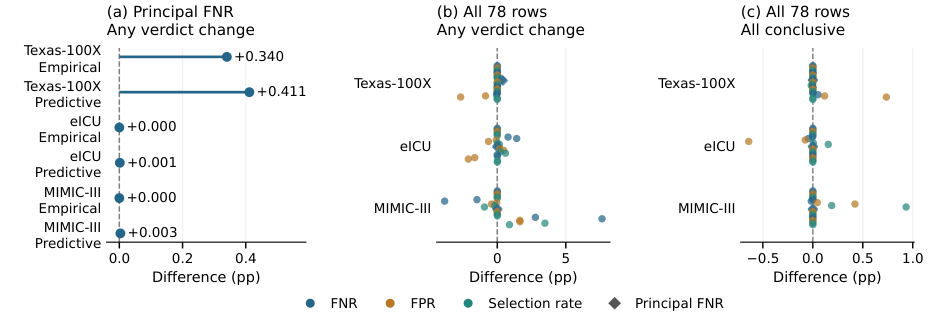

**Figure 3.** Independent marginal products minus shared-reference probabilities (all 78 clinical rows). Diamonds: principal FNR families. Mean conclusiveness is the unchanged marginal control.

In [13]:
record('Main Tables IV and VI',True,'Saved phase-cost arithmetic and feasibility partition reconciled')
show_table('IV')
show_table('VI')
show_figure('3')

### 3.2 External methods: same samples, explicit targets

The Cherian–Candès adapter jointly bootstraps the positive-outcome loss and shared reference. It uses 1,999 draws, group mass floor 0.01 and full shrinkage to the overall-loss scale; minimum-support one and twenty retain other boundary and undefined-bootstrap safeguards. Its asymptotic population-gap target differs from UM's predictive target.

Uncertainty Matters uses a Dirichlet(1,1,1,1) confusion-table prior and 19,999 posterior-predictive draws, sharing the reference across comparisons. Undefined positive denominators remain [-1,1]. Its future-gap evaluation uses 100 independently generated same-size future confusion tables per clinical audit. The population-gap diagnostic applies the unchanged predictive intervals to a different target and is labelled accordingly.

The following reconstruction averages audit-level outcomes, retaining unsupported categories in the resolution denominator. A wrong family assertion means at least one wrong pass or fail. These saved experiments comprise 8,000 synthetic audits and 1,800 clinical replacement audits; they do not validate an arbitrary future hospital population.

In [14]:
audits = frame('matched_replicates')
support1 = frame('matched_support1')
assert len(audits) == 29400 and len(support1)==9800
metrics = ['correct_resolution','any_wrong','inconclusive','supported_family_inclusion']
reconstructed = audits.groupby(['scenario','method'])[metrics].mean()
stored = frame('matched_scenarios').set_index(['scenario','method'])
np.testing.assert_allclose(reconstructed.sort_index(),stored.loc[reconstructed.index,metrics].sort_index(),atol=1e-12)
all_rules = pd.concat([audits,support1],ignore_index=True)
synthetic = all_rules[all_rules.scenario.str.startswith('syn_')]
display(100*synthetic.groupby('method')[metrics].mean())
display(100*all_rules[~all_rules.scenario.str.startswith('syn_')].groupby(['scenario','method'])[metrics].mean())
show_table('VII')
record('Main Table VII',True,'Recomputed summaries from 39,200 audit-method records, retaining all sizes')
display(frame('native_prediction'))

,correct_resolution,any_wrong,inconclusive,supported_family_inclusion
method,,,,
cc_bootstrap,24.65417,0.5625,75.15833,95.0875
cc_support_1,24.3875,0.55,75.42917,95.0125
uaf_cp_rule,12.275,0,87.725,99.8375
um_predictive_wrapper,13.77083,0.0125,86.225,99.875


correct_resolution  any_wrong  \
scenario       method                                                 
eicu_iid_f025  cc_bootstrap                            0          0   
               cc_support_1                    0.3333333          0   
               uaf_cp_rule                             0          0   
               um_predictive_wrapper                   0          0   
eicu_iid_f050  cc_bootstrap                   0.08333333          0   
               cc_support_1                            0          1   
               uaf_cp_rule                             0          0   
               um_predictive_wrapper                   0          0   
eicu_iid_f100  cc_bootstrap                    0.9166667        0.5   
               cc_support_1                    0.9166667        0.5   
               uaf_cp_rule                    0.08333333          0   
               um_predictive_wrapper                   0          0   
mimic_iid_f025 cc_bootstrap                        0.025          0   
               cc_support_1                       0.0375          0   
               uaf_cp_rule                             0          0   
               um_predictive_wrapper                   0          0   
mimic_iid_f050 cc_bootstrap                       0.0625        0.5   
               cc_support_1                       0.0375        0.5   
               uaf_cp_rule                        0.0125          0   
               um_predictive_wrapper              0.0125          0   
mimic_iid_f100 cc_bootstrap                        0.075          0   
               cc_support_1                         0.45          0   
               uaf_cp_rule                        0.0375          0   
               um_predictive_wrapper                   0          0   
texas_iid_f025 cc_bootstrap                         37.5          0   
               cc_support_1                         37.5          0   
               uaf_cp_rule                            28          0   
               um_predictive_wrapper                  26          0   
texas_iid_f050 cc_bootstrap                       45.625          0   
               cc_support_1                       45.625          0   
               uaf_cp_rule                        39.125          0   
               um_predictive_wrapper               33.75          0   
texas_iid_f100 cc_bootstrap                       55.875          0   
               cc_support_1                       55.875          0   
               uaf_cp_rule                        62.625          0   
               um_predictive_wrapper               54.25          0   

                                      inconclusive  supported_family_inclusion  
scenario       method                                                           
eicu_iid_f025  cc_bootstrap                    100                        95.5  
               cc_support_1               99.66667                          94  
               uaf_cp_rule                     100                        99.5  
               um_predictive_wrapper           100                         100  
eicu_iid_f050  cc_bootstrap               99.91667                          96  
               cc_support_1               99.83333                          97  
               uaf_cp_rule                     100                          99  
               um_predictive_wrapper           100                         100  
eicu_iid_f100  cc_bootstrap                     99                          94  
               cc_support_1                     99                        94.5  
               uaf_cp_rule                99.91667                        98.5  
               um_predictive_wrapper           100                         100  
mimic_iid_f025 cc_bootstrap                 99.975                        96.5  
               cc_support_1                99.9625                        93.5  
               uaf_cp_rule                 

Population,Size,Records,UAF CP,C--C adapter: 1,C--C adapter: 20,UM population diagnostic
Synthetic grid,pooled,"3,000/12,000",12.275 / 0.000,24.388 / 0.550,24.654 / 0.563,13.771 / 0.013
Texas,$.25N$,"42,484",28.000 / 0,37.500 / 0,37.500 / 0,26.000 / 0
,$.50N$,"84,967",39.125 / 0,45.625 / 0,45.625 / 0,33.750 / 0
,$N$,"169,933",62.625 / 0,55.875 / 0,55.875 / 0,54.250 / 0
eICU,$.25N$,"5,143",0 / 0,0.333 / 0,0 / 0,0 / 0
,$.50N$,"10,286",0 / 0,0 / 1.000,0.083 / 0,0 / 0
,$N$,"20,572",0.083 / 0,0.917 / 0.500,0.917 / 0.500,0 / 0
MIMIC-III,$.25N$,"1,212",0 / 0,0.038 / 0,0.025 / 0,0 / 0
,$.50N$,"2,424",0.013 / 0,0.038 / 0.500,0.063 / 0.500,0.013 / 0
,$N$,"4,848",0.038 / 0,0.450 / 0,0.075 / 0,0 / 0


,scenario,audits,future_replicates_per_audit,full_family_set_inclusion,audit_cluster_mc_se,defined_gap_family_inclusion,defined_target_fraction,mean_comparison_set_inclusion
0,texas_iid_f025,200,100,0.94955,0.004728454,0.94955,1,0.9870875
1,texas_iid_f050,200,100,0.95455,0.004235408,0.95455,1,0.9884875
2,texas_iid_f100,200,100,0.9477,0.005015909,0.9477,1,0.9866125
3,eicu_iid_f025,200,100,0.9588,0.003213164,0.96515,0.984175,0.9929583
4,eicu_iid_f050,200,100,0.95845,0.003974224,0.95995,0.9990167,0.992825
5,eicu_iid_f100,200,100,0.95125,0.004994941,0.9513,0.9999917,0.9917
6,mimic_iid_f025,200,100,0.99645,0.0007190778,0.99715,0.220435,0.9999113
7,mimic_iid_f050,200,100,0.99135,0.001404726,0.99215,0.2760275,0.99978
8,mimic_iid_f100,200,100,0.9898,0.003100462,0.9903,0.3416025,0.9997413


### 3.3 Scaling, memory and reuse costs

Measured setup, law-generation and integration costs belong to the recorded single-thread benchmark environment: Intel Core Ultra 9 275HX, Windows 11, Python 3.11.9, NumPy 2.4.2 and SciPy 1.15.3. The 21-design grid has two fresh processes per method and retains preflight exclusions and timeouts. An unfinished query has no imputed speedup. The million-reference, thousand-group example uses only three boundary types; its compression is not representative of every workload.

The full grid and candidate replay below preserve both favorable and unfavorable timings. The figures plot measured records; running this notebook does not remeasure them on the reviewer's machine.

,case,repeat,method,G,n0,minimum_group_denominator,maximum_group_denominator,status,completed_queries,setup_seconds,endpoint_seconds,boundary_seconds,run_partition_seconds,reference_runs,mass_generation_seconds,integration_seconds,cold_seconds,reuse10_seconds,process_wall_seconds,peak_MiB
0,ratio_10,0,run_compressed,40,10000,10,10,complete,10,0.0356037,0.0353116,0.0001648001,0.0001143999,33,0.0578831,0.0857326,0.0502043,0.179273,2.296,90.90625
1,ratio_10,0,indexed,40,10000,10,10,complete,10,0.0343892,0.0342147,0.0001683,NaN,NaN,0.0612838,0.2751493,0.0697879,0.3708835,2.297,92.10547
2,ratio_10,0,direct,40,10000,10,10,complete,10,0.0342544,0.0342479,1.400011e-06,NaN,NaN,0.0528302,0.2493074,0.0682133,0.3364497,2.532,90.70703
3,ratio_10,1,run_compressed,40,10000,10,10,complete,10,0.0353411,0.0350719,0.0001711999,8.730008e-05,33,0.0581676,0.0884753,0.052975,0.1820366,2.281,90.99609
4,ratio_10,1,indexed,40,10000,10,10,complete,10,0.0184924,0.0183975,9.14e-05,NaN,NaN,0.037898,0.1572207,0.0398888,0.2136498,2.046,91.59766
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121,distinct_1000,0,indexed,1000,10000,500,1499,complete,10,2.823057,2.301091,0.5219568,NaN,NaN,3.079126,10.51981,4.363012,16.42205,18.812,419.6055
122,distinct_1000,0,direct,1000,10000,500,1499,query_time_censored,1,2.323934,2.323924,2.200017e-06,NaN,NaN,0.4015014,17.00026,19.72571,NaN,24.313,124.0586
123,distinct_1000,1,run_compressed,1000,10000,500,1499,complete,10,3.10742,2.592182,0.4789816,0.0361939,10001,2.89894,9.819254,4.623221,15.82567,18.11,420.1445
124,distinct_1000,1,indexed,1000,10000,500,1499,complete,10,3.277449,2.690015,0.5874231,NaN,NaN,2.498302,8.448833,4.70442,14.22463,16.312,419.9297


,design,case,G,n0,group_n_min,group_n_max,boundary_types,laws_per_preparation,total_runs,positive_runs_min,...,indexed_completed_queries,indexed_setup_median_s,indexed_total10_median_s,indexed_peak_max_mib,indexed_over_run_paired_median,direct_completed_queries,direct_setup_median_s,direct_total10_median_s,direct_peak_max_mib,direct_over_run_paired_median
0,1,ratio_10,40,10000,10,10,1,10,33,13,...,10/10,0.0264408,0.2922666,92.10547,1.621242,10/10,0.03227885,0.3309589,90.70703,1.832336
1,2,ratio_30,40,10000,30,30,1,10,103,34,...,10/10,0.03494645,0.3545793,92.18359,2.188485,10/10,0.0231422,0.3517675,91.09766,2.1013
2,3,ratio_100,40,10000,100,100,1,10,355,110,...,10/10,0.0267309,0.2855456,92,1.833089,10/10,0.03430565,0.6756756,91.98438,4.759918
3,4,ratio_300,40,10000,300,300,1,10,1039,321,...,10/10,0.032131,0.3453329,92.54688,1.56366,10/10,0.0253121,2.108096,94.57031,9.502551
4,5,ratio_1000,40,10000,1000,1000,1,10,3119,971,...,10/10,0.0341646,0.6047075,94.07422,1.367286,10/10,0.0343586,8.91546,102.2383,19.90567
5,6,ratio_3000,40,10000,3000,3000,1,10,7137,2169,...,10/10,0.0454963,0.6737034,94.32422,0.8278163,10/10,0.0382753,17.00414,113.8477,20.87777
6,7,ratio_10000,40,10000,10000,10000,1,10,10001,2970,...,10/10,0.0323068,1.26756,94.39844,0.8599737,7/7,0.0277875,NaN,133.5898,NaN
7,8,denominator_types_3,40,10000,100,1000,3,10,4533,1399,...,10/10,0.03685105,0.3986167,94.15625,1.61349,10/10,0.02954485,4.871916,103.4453,19.76082
8,9,denominator_types_10,40,10000,100,1000,10,10,8541,2590,...,10/10,0.0452159,0.5002968,96.86719,1.564335,10/10,0.04099005,5.169013,102.6562,16.14499
9,10,denominator_types_40,40,10000,100,1000,40,10,9993,2969,...,10/10,0.06960595,0.4313499,106.9648,0.9270623,10/10,0.0909001,5.356818,102.7109,11.47087


,cohort,original_candidates,unique_prediction_vectors,unique_count_inputs,unique_queries,preparations,G,n0,eligible_groups,boundary_types,K,M0_min,M0_max,Kq_min,Kq_max,uncompressed_queries,nominal_rows,run_rows,removed_row_fraction
0,texas,2,2,2,4,1,4,52770,4,4,42517,6470,9553,5501,8121,0,127708,107876,0.1552918
1,eicu,32,31,31,62,1,6,1505,6,6,775,540,1506,269,775,0,427512,224016,0.4760007
2,mimic,32,31,31,62,1,40,372,17,7,273,296,373,213,273,0,914880,669480,0.2682319


median       min       max
cohort method                                      
eicu   direct         0.1937933 0.1646488 0.2317293
       indexed        0.1845383  0.139488 0.2146598
       run_compressed 0.1709449 0.1368004 0.2572097
mimic  direct         0.2952763  0.231104 0.4335824
       indexed          0.40447  0.320001 0.4931266
       run_compressed 0.3336991 0.2792724 0.4292197
texas  direct          1.608018   1.27268  2.011698
       indexed        0.3752612 0.2442046 0.4334863
       run_compressed 0.2921172 0.2576008 0.4377099

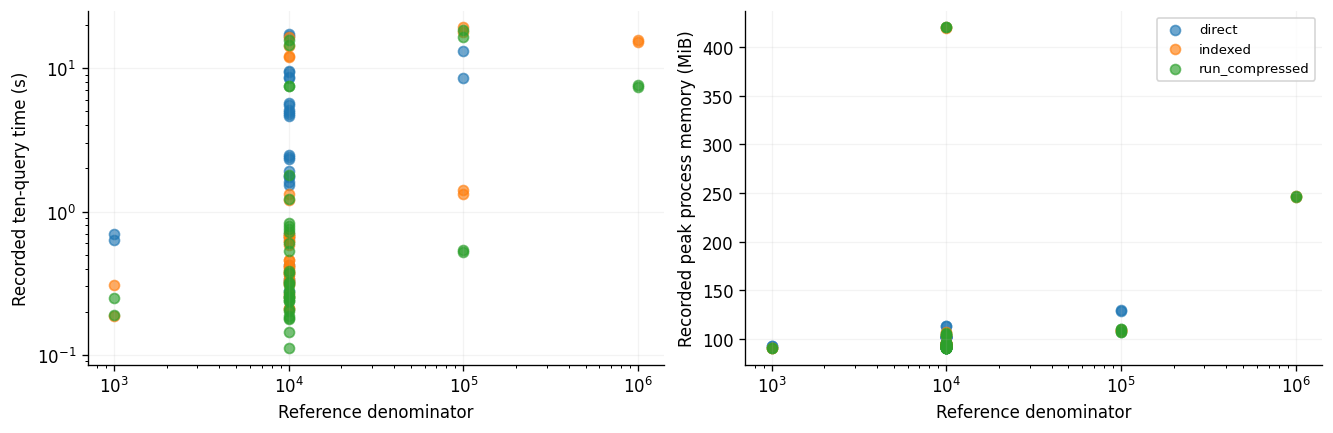

In [15]:
scaling = frame('scaling_grid')
assert len(scaling)==126 and scaling.case.nunique()==21
display(scaling)
display(frame('scaling_regimes'))
display(frame('candidate_structure'))
display(frame('candidate_timings').groupby(['cohort','method']).computation_seconds.agg(['median','min','max']))
fig, ax = plt.subplots(1,2,figsize=(11,3.5),layout='constrained')
complete = scaling[scaling.status.eq('complete')].copy()
assert len(complete)>0
for method, group in complete.groupby('method'):
    ax[0].scatter(group.n0,group.reuse10_seconds,label=method,alpha=.65)
    ax[1].scatter(group.n0,group.peak_MiB,label=method,alpha=.65)
for a in ax: a.set_xscale('log'); a.set_xlabel('Reference denominator'); a.grid(alpha=.15)
ax[0].set_yscale('log'); ax[0].set_ylabel('Recorded ten-query time (s)')
ax[1].set_ylabel('Recorded peak process memory (MiB)'); ax[1].legend(fontsize=8)
plt.show()

## 4. C2: source variation and conditional evidence limits

The historical sex-FNR analysis separates supported-hospital variation from sampling variation. It has 58 supported Texas hospitals and nine eICU hospitals; MIMIC cannot identify between-hospital variation. The count guard assumes one random supported hospital and sampling variance c/n. It is sufficient under fitted Gaussian inputs, not a minimum count or a clinical recruitment guarantee. The following code recomputes the two-source attribution and guard rather than refitting source data. Table VIII uses the sampling constant from the supported cells (eICU 0.339752, sufficient count 621); the companion's Tables S16 and S17 use the pooled eligible records (0.3370806, count 616). The difference is the record set entering $c$, not the formula.

In [16]:
def two_tail_risk(mu, variance):
    if variance == 0:
        return float(abs(mu) > .10)
    sd = np.sqrt(variance)
    return norm.cdf((-.10 - mu) / sd) + norm.sf((.10 - mu) / sd)

source_summary = []
for row in pd.DataFrame(data["source fits"]).itertuples():
    mu, sampling, hospital = row.mean_gap, row.observed_cell_sampling_variance, row.site_variance
    sampling_only = two_tail_risk(mu, sampling)
    hospital_only = two_tail_risk(mu, hospital)
    full = two_tail_risk(mu, sampling + hospital)
    sampling_share = (sampling_only + full - hospital_only) / 2
    hospital_share = (hospital_only + full - sampling_only) / 2
    np.testing.assert_allclose([sampling_share, hospital_share],
        [row.observed_cell_sampling_shapley, row.observed_cell_site_shapley], atol=1e-12, rtol=0)
    allowed = ((.10 - abs(mu)) / norm.isf(.05 / 2)) ** 2
    count = int(np.ceil(row.sampling_constant / (allowed - hospital))) if allowed > hospital else None
    risk500 = two_tail_risk(mu, hospital + row.sampling_constant / 500)
    np.testing.assert_allclose(risk500, row.risk_at_n500, atol=1e-12, rtol=0)
    source_summary.append({
        "Cohort": cohort_name[row.dataset], "Hospitals": row.supported_hospitals, "Mean gap (pp)": 100 * mu,
        "Sampling risk (pp)": 100 * sampling_share, "Hospital risk (pp)": 100 * hospital_share,
        "Sufficient positives per sex": count if count is not None else "None finite",
        "Exact fitted risk at 500 (%)": 100 * risk500,
    })
assert [r["Sufficient positives per sex"] for r in source_summary] == ["None finite", 621]
display(pd.DataFrame(source_summary))

,Cohort,Hospitals,Mean gap (pp),Sampling risk (pp),Hospital risk (pp),Sufficient positives per sex,Exact fitted risk at 500 (%)
0,Texas-100X,58,4.270655,9.829075,18.48544,None finite,22.72401
1,eICU,9,-3.890297,26.45878,0.7032698,621,3.297819


In [17]:
record('Main Table VIII',True,'Fitted risks and sufficient counts recomputed; resampling ranges checked as saved results')
show_table('VIII')
display(frame('source_sensitivity'))
display(frame('source_recovery'))

Quantity,Texas,eICU
Supported hospitals,58,9
Mean gap (pp),$+4.27$,$-3.89$
Sampling variance ($\times10^{-3}$),2.36845,6.24312
Hospital variance ($\times10^{-3}$),4.35101,0.42436
Sampling/hospital Shapley (risk pp),9.83/18.49,26.46/0.70
Hospital share: point [range] (%),"65.29 / [40.75,76.26]","2.59 / [0,28.45]"
Nearest boundary margin (pp),5.73,6.11
Sampling constant $c$,0.273856,0.339752
Allowed variance ($\times10^{-3}$),0.85450,0.97173
Sufficient positives/sex,None finite,621


,dataset,method,replicates,convergence_fraction,finite_count_fraction,no_finite_count_fraction,zero_site_variance_fraction,mean_outside_tolerance_fraction,n500_risk_at_most_05_fraction,infinite_n_risk_at_most_05_fraction,...,observed_cell_total_risk_q975,observed_cell_site_shapley_q025,observed_cell_site_shapley_q50,observed_cell_site_shapley_q975,observed_cell_sampling_shapley_q025,observed_cell_sampling_shapley_q50,observed_cell_sampling_shapley_q975,observed_cell_site_fraction_q025,observed_cell_site_fraction_q50,observed_cell_site_fraction_q975
0,eicu,hospital_pairs,2000,1,0.81,0.19,0.4635,0,0.544,0.9105,...,0.4126069,0,0.00177651,0.07701355,0.1371,0.2652697,0.4126069,0,0.006941156,0.2844531
1,eicu,two_stage_binomial_sensitivity,2000,1,0.329,0.671,0.2085,0.01,0.221,0.3665,...,0.5233989,0,0.09848975,0.2892818,0.1128104,0.2314298,0.4110463,0,0.3060039,0.6437381
2,texas,hospital_pairs,2000,1,0.008,0.992,0,0,0.0075,0.024,...,0.3780383,0.06925672,0.1831047,0.2600234,0.05816406,0.09993935,0.1394119,0.4074866,0.6452597,0.7625887
3,texas,two_stage_binomial_sensitivity,2000,1,0.0075,0.9925,0,0,0.007,0.0145,...,0.4057186,0.0798815,0.2066235,0.2894777,0.05621841,0.0958627,0.1416916,0.4541953,0.6786518,0.795848


,hospitals,scenario,true_mu,true_site_variance,repetitions,mean_bias,mean_rmse,variance_bias,finite_count_fraction,true_finite_count,finite_state_accuracy,zero_site_variance_fraction,probabilities_clipped,convergence_fraction
0,9,0,0.02,0,300,2.712728e-05,0.02299469,0.0009056321,0.78,True,0.78,0.5633333,0,1
1,9,1,0.02,0.0004,300,0.0004063971,0.02329201,0.0008662584,0.67,True,0.67,0.4466667,0,1
2,9,2,0.085,0.0004,300,-0.0003601309,0.02523121,0.0008566026,0.4066667,False,0.5933333,0.5133333,0,1
3,58,0,0.02,0,300,0.001070218,0.00960498,0.0008184382,0.8133333,True,0.8133333,0.31,0,1
4,58,1,0.02,0.0004,300,-0.00011605,0.01003202,0.0008343833,0.6766667,True,0.6766667,0.1733333,0,1
5,58,2,0.085,0.0004,300,0.0007336005,0.009978122,0.0009036586,0.1833333,False,0.8166667,0.1966667,0,1


The hospital-share percentiles describe the chosen resampling law, not a calibrated confidence interval. In eICU, 46.35% of hospital-pairs draws estimated zero hospital variance, and finite guards occurred in 81.0% versus 32.9% under the two resampling designs. Binomial-normal likelihood profiles provide a separate hospital-variance analysis. The two parameterizations are not interchangeable.

In [18]:
source_coverage=[]
for cohort in ['texas','eicu']:
    simulations=frame('source_'+cohort+'_simulation')
    assert len(simulations)==200
    source_coverage.append({'Cohort':cohort_name[cohort],'Retained true variance':int(simulations.retains_true_variance.sum()),'Simulations':len(simulations)})
display(pd.DataFrame(source_coverage))
record('Hospital-binomial simulation counts',[x['Retained true variance'] for x in source_coverage]==[185,199],'Reaggregated recorded simulation fits')

,Cohort,Retained true variance,Simulations
0,Texas-100X,185,200
1,eICU,199,200


## 5. C3: confirmation allocation and forecast evidence

### 5.1 Algorithm 2 in readable form

For each group, $N_g$ is the complete positive-frame size, $m_g$ the pilot reviews and $k_g$ the pilot errors. The remaining frame is $N_g-m_g$. A confirmation allocation chooses additional counts from a declared grid while respecting capacity and total budget. The utility $U_g(n_g,n_0)$ is the expected probability of a conclusive full-frame decision, conditional on the pilot model. The reference allocation influences every comparison.

For a fixed reference increment, the recurrence is
$$D_g(b)=\max_{e\in E_g,\ e\leq b}\{D_{g-1}(b-e)+U_g(a_g+e,n_0)\}.$$
The algorithm saves the best reachable value and backtracks the allocation. Infeasibility is explicit. Maximizing this predicted average does not prove that every group's true resolution improves. The next cell checks the allocation recurrence against exhaustive enumeration on a small labelled numerical example; the empirical results are then reconstructed from their saved policy records.

In [19]:
def allocate(utilities, group_grids, reference_grid, budget):
    """Maximize total supplied utility at exactly the feasible extra budget."""
    if not isinstance(budget,int) or budget<0:
        raise ValueError('budget must be a nonnegative integer')
    best = None
    for reference in reference_grid:
        if reference>budget: continue
        reachable = {0:(0.0,())}
        for g, grid in enumerate(group_grids):
            updated = {}
            for used,(value,allocation) in reachable.items():
                for increment in grid:
                    cost=used+increment
                    if cost>budget-reference: continue
                    candidate=(value+utilities[g][reference,increment],allocation+(increment,))
                    if cost not in updated or candidate[0]>updated[cost][0]:
                        updated[cost]=candidate
            reachable=updated
        if budget-reference in reachable:
            value,allocation=reachable[budget-reference]
            if best is None or value>best[0]: best=(value,(reference,)+allocation)
    return best

# Synthetic recurrence check; these values are not clinical findings.
group_grids=[[0,2,4],[0,2,4]]
reference_grid=[0,2,4]
utilities=[{(r,e):1-np.exp(-(.15+.05*g)*(r+e)) for r in reference_grid for e in group_grids[g]} for g in range(2)]
answer=allocate(utilities,group_grids,reference_grid,6)
enumerated=[(sum(utilities[g][r,e] for g,e in enumerate(es)),(r,)+es)
            for r in reference_grid for es in product(*group_grids) if r+sum(es)==6]
assert abs(answer[0]-max(v for v,_ in enumerated))<1e-14
assert sum(answer[1])==6 and allocate(utilities,group_grids,reference_grid,1) is None
record('Algorithm 2 recurrence and infeasibility',True,'Fresh synthetic exhaustive check; no experimental result changed')
print('Checked allocation:',answer)

Checked allocation: (np.float64(1.1499941519937715), (4, 0, 2))


In [20]:
plan = pd.DataFrame(data["planning"])
assert len(plan) == 160 and (plan.target_lower <= plan.target_truth + 1e-12).all()
assert (plan.target_truth <= plan.target_upper + 1e-12).all()
plan["Forecast"] = np.select(
    [plan.target_lower >= plan.target, plan.target_upper < plan.target],
    ["Met", "Not met"], default="Unresolved")
plan["Forecast width"] = plan.target_upper - plan.target_lower
plan["DP correct (%)"] = 100 * plan.dp_correct
plan["Balancing correct (%)"] = 100 * plan.baseline_correct
plan["Certified gain"] = plan.correct_gain_lower > 0
plan["Cohort"] = plan.dataset.map(cohort_name)
design = ["Cohort", "pilot_cap", "budget"]
by_design = plan.groupby(design)
outcome_counts = plan.groupby(design + ["Forecast"]).size().unstack(fill_value=0)
display(by_design[["reviews", "DP correct (%)", "Balancing correct (%)", "Forecast width"]].mean()
        .join(outcome_counts).rename_axis(["Cohort", "Pilot cap", "Extra budget"]))
assert plan.Forecast.value_counts().to_dict() == {"Unresolved": 146, "Met": 9, "Not met": 5}
assert not plan["Certified gain"].any() and plan.identical.sum() == 71
truth_met = (plan.loc[plan.Forecast == "Unresolved", "target_truth"] >= .10).sum()
assert truth_met == 111
large_texas = plan.query("dataset == 'texas' and pilot_cap == 200 and budget == 2000")
np.testing.assert_allclose(large_texas[["DP correct (%)", "Balancing correct (%)"]].mean().round(2),
                           [41.64, 30.23], atol=1e-9, rtol=0)
print("Target forecasts: 9 met, 5 not met, 146 unresolved. Of the unresolved, 111 reach the target with full totals.")
print("Certified gain over balancing: 0/160.")
grid_labels = {"coarse": "50-record grid", "intermediate25": "25-record grid", "sparse": "Finest grid"}
grids = pd.DataFrame(data["planning grids"]).set_index("grid").rename(index=grid_labels)
display(grids.rename(columns={"records": "Pilot-budget records", "balancing_correct_percent": "Balancing correct (%)",
                             "dp_correct_percent": "DP correct (%)", "oracle_correct_percent": "Oracle correct (%)"}))

reviews  DP correct (%)  \
Cohort     Pilot cap Extra budget                            
MIMIC-III  20        250               435        39.89081   
           200       250               508        40.00181   
Texas-100X 20        250               473    4.521129e-10   
                     2000             2223        29.02727   
           200       250              1128    3.968146e-07   
                     2000             2878        41.64435   
eICU       20        250               475        26.07998   
           200       250               661        37.22786   

                                   Balancing correct (%)  Forecast width  Met  \
Cohort     Pilot cap Extra budget                                               
MIMIC-III  20        250                        39.89081       0.4076405    1   
           200       250                        40.00181       0.2651407    8   
Texas-100X 20        250                      8.7066e-10       0.9134004    0   
                     2000                       26.44291       0.9999917    0   
           200       250                    7.954655e-09       0.1875366    0   
                     2000                       30.22795       0.7239354    0   
eICU       20        250                        24.91552       0.9963837    0   
           200       250                        37.22786       0.9294399    0   

                                   Not met  Unresolved  
Cohort     Pilot cap Extra budget                       
MIMIC-III  20        250                 0          19  
           200       250                 0          12  
Texas-100X 20        250                 0          20  
                     2000                0          20  
           200       250                 5          15  
                     2000                0          20  
eICU       20        250                 0          20  
           200       250                 0          20

Target forecasts: 9 met, 5 not met, 146 unresolved. Of the unresolved, 111 reach the target with full totals.
Certified gain over balancing: 0/160.


,Pilot-budget records,Balancing correct (%),DP correct (%),Oracle correct (%)
grid,,,,
50-record grid,40,4.412653e-09,1.986334e-07,3.218937e-07
25-record grid,40,2.052121e-06,3.671267,6.174348
Finest grid,40,1.35302e-09,19.78824,21.51358


In [21]:
records = frame('planning_records')
assert len(records)==800 and records.policy.nunique()==5
keys=['dataset','pilot_cap','budget']
summary=records.groupby(keys+['policy']).agg(reviews=('cost','mean'), correct=('correct_resolution','mean'),
    wrong=('any_wrong_full','mean'),all_correct=('all_resolution','mean')).reset_index()
assert records.groupby(keys+['replicate']).cost.nunique().eq(1).all()
correct=summary.pivot(index=keys,columns='policy',values='correct')
np.testing.assert_allclose(correct['balance'],correct['uniform'],atol=1e-15)
display(100*correct)
show_table('X')
record('Main Table X',True,'800 saved policy-pilot records; five comparators; exact matched review costs; 160 forecast statuses')
show_table('IX')
display(frame('planning_grids'))
display(frame('planning_completions'))
record('Main Table IX',True,'Complete grid summaries and the same-40-pilot sensitivity panel retained')

policy                        balance           dp       greedy       oracle  \
dataset pilot_cap budget                                                       
eicu    20        250        24.91552     26.07998     26.07998     27.40084   
        200       250        37.22786     37.22786     37.22786     37.22786   
mimic   20        250        39.89081     39.89081     39.89081     39.89081   
        200       250        40.00181     40.00181     40.00181     40.00181   
texas   20        250    8.706474e-10 4.521215e-10 4.521998e-10 4.832733e-08   
                  2000       26.44291     29.02727     28.80487     40.16488   
        200       250     7.95466e-09 3.968146e-07  3.81187e-07 5.954601e-07   
                  2000       30.22795     41.64435     22.55459     43.58036   

policy                        uniform  
dataset pilot_cap budget               
eicu    20        250        24.91552  
        200       250        37.22786  
mimic   20        250        39.89081  
        200       250        40.00181  
texas   20        250    8.706474e-10  
                  2000       26.44291  
        200       250     7.95466e-09  
                  2000       30.22795

Cohort,Cap / extra,Total reviews,Correct resolution (%) / DP / B=U / G / O,"Any wrong, DP (%)",Forecast width,Met / not met / I
Texas,20 / 250,473,$<10^{-6}$ / $<10^{-6}$ / $<10^{-6}$ / $<10^{-6}$,0.00803,0.913,0 / 0 / 20
Texas,200 / 250,"1,128",$<10^{-6}$ / $<10^{-6}$ / $<10^{-6}$ / $<10^{-6}$,0.012176,0.188,0 / 5 / 15
Texas,20 / 2000,"2,223",29.03 / 26.44 / 28.80 / 40.16,0.000951,1.000,0 / 0 / 20
Texas,200 / 2000,"2,878",41.64 / 30.23 / 22.55 / 43.58,0.037724,0.724,0 / 0 / 20
eICU,20 / 250,475,26.08 / 24.92 / 26.08 / 27.40,0.000382,0.996,0 / 0 / 20
eICU,200 / 250,661,37.23 / 37.23 / 37.23 / 37.23,0.000203,0.929,0 / 0 / 20
MIMIC,20 / 250,435,39.89 / 39.89 / 39.89 / 39.89,$<10^{-6}$,0.408,1 / 0 / 19
MIMIC,200 / 250,508,40.00 / 40.00 / 40.00 / 40.00,0.001181,0.265,8 / 0 / 12


,dataset,grid,rule,policy,records,actual_target_met_records,group_comparisons,supported_comparisons,group_loss_pilots,group_losses,...,correct_resolution,mean_resolution,mean_wrong_pass,mean_wrong_fail,any_wrong_full,all_resolution,supported_min_correct,supported_mean_correct,mean_correct_gain_vs_balance,mean_resolution_regret_to_oracle
0,eicu,coarse,primary,balance,40,40,240,240,0,0,...,0.3107169,0.3107175,3.855187e-07,2.048137e-07,3.538714e-06,2.910795e-21,7.775515e-13,0.3107169,0,0.0124264
1,eicu,coarse,primary,dp,40,40,240,240,9,10,...,0.3165392,0.3165397,2.835781e-07,2.042411e-07,2.924371e-06,1.77672e-21,7.775515e-13,0.3165392,0.005822333,0.006604169
2,eicu,coarse,primary,greedy,40,40,240,240,9,10,...,0.3165392,0.3165397,2.835781e-07,2.042411e-07,2.924371e-06,1.77672e-21,7.775515e-13,0.3165392,0.005822333,0.006604169
3,eicu,coarse,primary,oracle,40,40,240,240,19,26,...,0.3231435,0.3231439,1.697383e-07,1.895466e-07,2.154375e-06,3.453132e-22,7.775417e-13,0.3231435,0.01242663,0
4,eicu,coarse,primary,uniform,40,40,240,240,0,0,...,0.3107169,0.3107175,3.855187e-07,2.048137e-07,3.538714e-06,2.910795e-21,7.775515e-13,0.3107169,0,0.0124264
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,texas,sparse,split,balance,40,0,160,160,0,0,...,1.532825e-11,1.75665e-06,0,1.756634e-06,7.014095e-06,7.872471e-17,0,1.532825e-11,0,0.2239671
86,texas,sparse,split,dp,40,40,160,160,39,67,...,0.2061908,0.2062045,0,1.371787e-05,5.487013e-05,6.038041e-15,0,0.2061908,0.2061908,0.01776434
87,texas,sparse,split,greedy,40,0,160,160,37,64,...,1.209544e-10,1.600023e-06,0,1.599902e-06,6.372384e-06,5.20778e-12,4.46256e-17,1.209544e-10,1.056261e-10,0.2239672
88,texas,sparse,split,oracle,40,40,160,160,40,73,...,0.223952,0.2239688,0,1.681667e-05,6.726492e-05,8.731379e-15,0,0.223952,0.223952,0


,manifest,dataset,grid,rule,status,records,observed_seconds
0,direct_manifest.json,eicu,coarse,direct,completed,40,407.0716
1,direct_manifest.json,eicu,sparse,direct,not_attempted_input_cap,40,2.670079e-05
2,direct_manifest.json,mimic,coarse,direct,completed,40,92.99521
3,direct_manifest.json,mimic,sparse,direct,not_attempted_input_cap,40,2.310076e-05
4,direct_manifest.json,texas,coarse,direct,not_attempted_input_cap,80,3.330014e-05
5,direct_manifest.json,texas,sparse,direct,not_attempted_input_cap,80,2.62002e-05
6,intermediate_manifest.json,eicu,intermediate25,primary,completed,40,5.397616
7,intermediate_manifest.json,eicu,intermediate25,split,completed,40,5.201497
8,intermediate_manifest.json,mimic,intermediate25,primary,completed,40,8.369623
9,intermediate_manifest.json,mimic,intermediate25,split,completed,40,8.021517


### 5.2 Forecasts, correctness and group losses

Nine of 160 forecasts support the 10% total-conclusiveness target, five exclude it and 146 remain unresolved. This is not a count of correct or failed fairness verdicts. Complete totals show that 111 unresolved records attain the target. No gain over matched balancing is certified. Texas's 41.64% versus 30.23% result is an average correct-resolution improvement at equal cost, not a uniformly beneficial group allocation.

Uniform increments coincide with balancing in these 160 records. Greedy chooses immediate gain per review, DP optimizes the full finite grid, and the oracle uses unavailable full totals. Its objective is total conclusiveness, so it is not a correctness upper bound. Finer grids change feasible plans; unmatched completed subsets must not be compared as if they contained the same pilots.

The synthetic factorial uses 640 pilots in 64 fixed cells. Predictive floors and the DP-or-balancing switch reduce group losses at the cost of average gain. The confidence safeguard always retains balancing. All these results are preserved in Table XI and the complete groupwise results catalogue.

Available factorial policy identifiers: ['balance', 'constrained', 'dp', 'greedy', 'oracle', 'switch']


,correct_resolution,all_correct_resolution
policy,,
Balancing,23.57285,18.97222
Predictive constrained,24.01304,18.97127
Unrestricted DP,28.98743,8.841563
Greedy,28.20559,6.306984
Oracle,35.49076,19.02651
DP-or-balancing switch,23.98409,18.97222


,pilots,losses,worst
policy,,,
Balancing,640,0,0
Predictive constrained,640,100,-0.1088645
Unrestricted DP,640,356,-1
Greedy,640,403,-0.9999971
Oracle,640,269,-0.6481605
DP-or-balancing switch,640,19,-0.002234955


Policy,Mean (%),All (%),Any loss,Worst (pp)
Balancing,23.5728,18.9722,0/640,0.0000
Unrestricted DP,28.9874,8.8416,356/640,100.0000
Predictive constrained,24.0130,18.9713,100/640,10.8864
DP-or-balancing switch,23.9841,18.9722,19/640,0.2235
Confidence safeguard,23.5728,18.9722,0/640,0.0000


,dataset,pilot_cap,budget,pilots,primary_dp_correct_percent,unrestricted_dp_correct_percent,unrestricted_balance_correct_percent,primary_dp_max_family_wrong_percent,unrestricted_dp_max_family_wrong_percent,unrestricted_balance_max_family_wrong_percent
0,eicu,20,250,20,26.07998,22.33183,22.91761,0.000697178,0.0006622423,0.001000636
1,eicu,200,250,20,37.22786,31.51194,31.51194,0.0003655885,0.0007651401,0.0007651401
2,mimic,20,250,20,39.89081,39.13956,39.13956,1.045087e-08,7.560431e-13,7.560431e-13
3,mimic,200,250,20,40.00181,40.00116,40.00116,0.02244259,0,0
4,texas,20,250,20,4.521215e-10,0,0,0.01434804,0.2237289,0.06263653
5,texas,20,2000,20,29.02727,33.4479,29.53744,0.00396728,0.03731762,0.006119433
6,texas,200,250,20,3.968146e-07,0,0,0.01661874,0.206184,0.05875193
7,texas,200,2000,20,41.64435,43.19832,31.56696,0.04696034,0.2022705,0.004778248


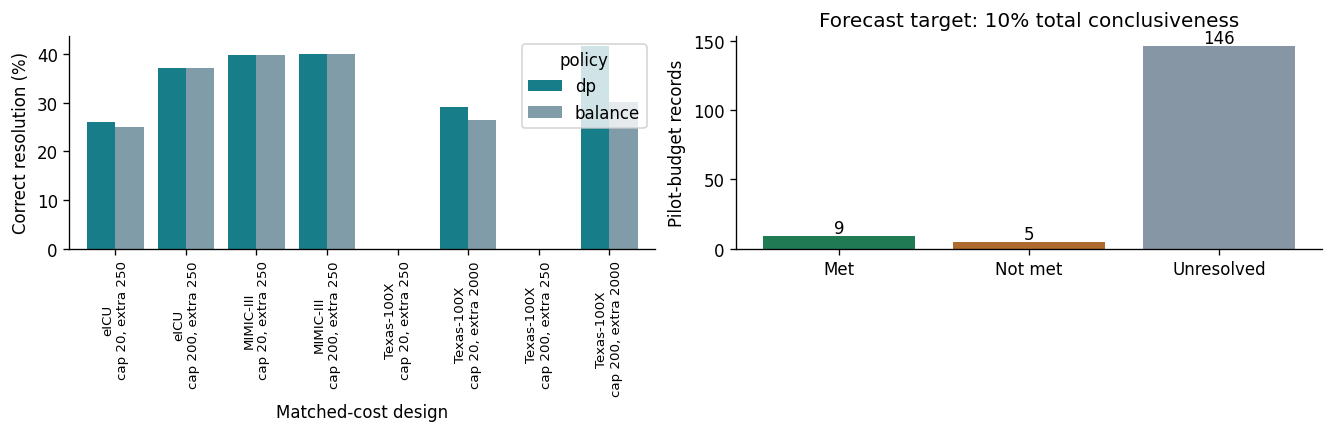

In [22]:
factorial=frame('factorial_current')
group_results=frame('factorial_groups')
labels={'balance':'Balancing','dp':'Unrestricted DP','constrained':'Predictive constrained','switch':'DP-or-balancing switch','greedy':'Greedy','oracle':'Oracle'}
print('Available factorial policy identifiers:',sorted(factorial.policy.unique()))
display((factorial.groupby('policy')[['correct_resolution','all_correct_resolution']].mean()*100).rename(index=labels))
group_minimum=group_results.groupby(['policy','name']).correct_gain_vs_balance.min()
display(group_minimum.groupby('policy').agg(pilots='size',losses=lambda x:int((x < -1e-10).sum()),worst='min').rename(index=labels))
show_table('XI')
display(frame('rule_changes'))
record('Main Table XI supporting records',factorial.name.nunique()==640,'Reaggregated current factorial means and per-pilot group losses')
fig,ax=plt.subplots(1,2,figsize=(11,3.5),layout='constrained')
plot=100*correct[['dp','balance']]
plot.index=[f'{cohort_name[d]}\ncap {c}, extra {b}' for d,c,b in plot.index]
plot.plot.bar(ax=ax[0],color=['#177e89','#819ca9'],width=.8)
ax[0].set_ylabel('Correct resolution (%)');ax[0].set_xlabel('Matched-cost design');ax[0].tick_params(axis='x',labelsize=8)
forecast_counts=plan.Forecast.value_counts().reindex(['Met','Not met','Unresolved'])
ax[1].bar(forecast_counts.index,forecast_counts.values,color=['#207b55','#ae6b30','#8796a5'])
ax[1].set_ylabel('Pilot-budget records');ax[1].set_title('Forecast target: 10% total conclusiveness')
for i,v in enumerate(forecast_counts):ax[1].text(i,v+2,str(v),ha='center')
plt.show()

## 6. C4: policy construction, finite-population review and six comparators

The 42 single-direction policies are study-generated threshold changes; they are not 42 methods proposed by external publications. Six frozen XGBoost models (two ICU cohorts × seeds 11/29/47) supply six calibration sensitivity targets 60/70/75/85/90/95%, each compared with its original 80% threshold. Existing group/global/budget contrasts complete the 54-policy panel. Forty-two have a single prediction-change direction and qualify for pooling; the 12 mixed-direction cases retain strata. These correlated policies share patients.

The primary criterion requires no net subgroup increase in missed outcomes and positive utility $\Delta TP-w\Delta FP$, with research weight $w=0.10$. Single-direction additions cannot increase misses, so their criterion reduces to the total number of positives among disagreements; removals require zero removed positives. These simplifications do not validate subgroup false-alert caps.

At each policy's matched review count, the six comparators are pooled exact SRS; stratified exact SRS; equal-allocation stratified exact; equal-allocation Gaussian stratified; SRS Gaussian prediction-powered inference; and SRS finite-sample betting prediction-powered inference. SRS methods share reviewed records. Equal allocation changes acquisition while matching the total review count. The next cell reruns hypergeometric inversion for every observed pooled-review count and checks all 42,000 primary decisions.

In [23]:
def exact_total_interval(N, n, x, alpha=.05):
    # Each integer total is retained when both tail probabilities meet alpha/2.
    lower, upper = x.copy(), N - n + x
    while np.any(lower < upper):
        mid = (lower + upper) // 2
        keep = hypergeom.sf(x - 1, N, mid, n) >= alpha / 2
        lower, upper = np.where(keep, lower, mid + 1), np.where(keep, mid, upper)
    left = lower.copy()
    lower, upper = x.copy(), N - n + x
    while np.any(lower < upper):
        mid = (lower + upper + 1) // 2
        keep = hypergeom.cdf(x, N, mid, n) >= alpha / 2
        lower, upper = np.where(keep, mid, lower), np.where(keep, upper, mid - 1)
    return left, upper

outcomes = pd.DataFrame(data["policy outcomes"])
pooled = outcomes.query("method == 'srs_exact_pooled'").set_index("case")
for case, N, n, direction, histogram in data["policy review histograms"]:
    x, frequency = np.array(histogram, dtype=int).T
    L, U = exact_total_interval(N, n, x)
    assert np.all((x <= L) & (L <= U) & (U <= N - n + x))
    # Weight 0.10: multiply utility by ten to use integer comparisons.
    if direction == "addition":
        accept, reject = 11 * L > N, 11 * U <= N
    else:
        assert direction == "removal"
        accept, reject = U == 0, L > 0
    assert not (accept & reject).any()
    actual = [frequency[reject].sum(), frequency[accept].sum(), frequency[~(accept | reject)].sum()]
    expected = pooled.loc[case, ["correct_reject_count", "wrong_accept_count", "defer_count"]].tolist()
    assert actual == expected, case
    assert frequency.sum() == 1000

counts = ["correct_reject_count", "wrong_accept_count", "defer_count", "included"]
assert outcomes.groupby("case").reviews_per_decision.nunique().eq(1).all()
assert outcomes.groupby("method").case.nunique().eq(42).all()
assert (outcomes[counts[:3]].sum(axis=1) == outcomes.decisions).all()
totals = outcomes.groupby("method")[counts + ["decisions"]].sum()
assert totals.decisions.eq(42000).all()
rates = 100 * totals[counts].div(totals.decisions, axis=0)
rates.columns = ["Correct reject (%)", "Wrong accept (%)", "Defer (%)", "Count inclusion (%)"]
method_name = {
    "srs_exact_pooled": "SRS, exact pooled",
    "srs_exact_stratified": "SRS, exact stratified",
    "equal_exact_stratified": "Equal, exact stratified",
    "equal_neyman_gaussian": "Equal, Gaussian stratified",
    "srs_ppi_gaussian": "SRS, Gaussian PPI",
    "srs_ppi_betting": "SRS, betting PPI",
}
display(rates.reindex(method_name).rename(index=method_name).round(3))
assert totals.loc["srs_exact_pooled", counts[:2]].tolist() == [33578, 40]
assert totals.loc["srs_ppi_betting", counts[:2]].tolist() == [32387, 6]
gain = rates.loc["srs_exact_pooled", "Correct reject (%)"] - rates.loc["srs_ppi_betting", "Correct reject (%)"]
print(f"Exact pooled replay passed for all 42 policies. Gain over betting PPI: {gain:.2f} percentage points.")
print(f"Average matched reviews per policy per draw: {pooled.reviews_per_decision.mean():.2f}.")

,Correct reject (%),Wrong accept (%),Defer (%),Count inclusion (%)
method,,,,
"SRS, exact pooled",79.948,0.095,19.957,96.624
"SRS, exact stratified",61.852,0,38.148,100
"Equal, exact stratified",71.286,0.005,28.71,99.664
"Equal, Gaussian stratified",75.486,0.033,24.481,91.029
"SRS, Gaussian PPI",80.107,1.493,18.4,92.733
"SRS, betting PPI",77.112,0.014,22.874,98.05


Exact pooled replay passed for all 42 policies. Gain over betting PPI: 2.84 percentage points.
Average matched reviews per policy per draw: 756.52.


In [24]:
record('Main Table XII',True,'42,000 exact pooled decisions recomputed; six-method recorded counts and inclusion reconciled')
show_table('XII')
display(frame('policy_strata'))
display(frame('policy_panel'))
display(frame('betting_policy'))

Review/inference,Correct / reject,Wrong / accept,Defer,Total-count / inclusion
"SRS, exact pooled",79.948,0.095,19.957,96.624
"SRS, exact stratified",61.852,0.000,38.148,100.000
"Equal, exact stratified",71.286,0.005,28.710,99.664
"Equal, Gaussian stratified",75.486,0.033,24.481,91.029
"SRS, Gaussian PPI",80.107,1.493,18.400,92.733
"SRS, betting PPI",77.112,0.014,22.874,98.050


,weight,direction,truth,method,policies,decisions,review_count_mean,review_count_min,review_count_max,disagreements_total,...,correct_accept_count,correct_accept_percent,wrong_accept_count,wrong_accept_percent,correct_reject_count,correct_reject_percent,wrong_reject_count,wrong_reject_percent,defer_count,defer_percent
0,0.1,addition,unacceptable,srs_exact_pooled,20,20000,992.2,33,2989,39679,...,0,0,40,0.2,12230,61.15,0,0,7730,38.65
1,0.1,addition,unacceptable,srs_exact_stratified,20,20000,992.2,33,2989,39679,...,0,0,0,0,4630,23.15,0,0,15370,76.85
2,0.1,addition,unacceptable,equal_exact_stratified,20,20000,992.2,33,2989,39679,...,0,0,2,0.01,8547,42.735,0,0,11451,57.255
3,0.1,addition,unacceptable,equal_neyman_gaussian,20,20000,992.2,33,2989,39679,...,0,0,14,0.07,12397,61.985,0,0,7589,37.945
4,0.1,addition,unacceptable,srs_ppi_gaussian,20,20000,992.2,33,2989,39679,...,0,0,27,0.135,13364,66.82,0,0,6609,33.045
5,0.1,addition,unacceptable,srs_ppi_betting,20,20000,992.2,33,2989,39679,...,0,0,6,0.03,11039,55.195,0,0,8955,44.775
6,0.1,removal,unacceptable,srs_exact_pooled,22,22000,542.2727,10,1665,23848,...,0,0,0,0,21348,97.03636,0,0,652,2.963636
7,0.1,removal,unacceptable,srs_exact_stratified,22,22000,542.2727,10,1665,23848,...,0,0,0,0,21348,97.03636,0,0,652,2.963636
8,0.1,removal,unacceptable,equal_exact_stratified,22,22000,542.2727,10,1665,23848,...,0,0,0,0,21393,97.24091,0,0,607,2.759091
9,0.1,removal,unacceptable,equal_neyman_gaussian,22,22000,542.2727,10,1665,23848,...,0,0,0,0,19307,87.75909,0,0,2693,12.24091


,weight,method,truth_set,policies,acceptable_policies,rejected_policies,simulation_decisions,actual_reviews_mean,actual_reviews_min,actual_reviews_max,...,wrong_decision,wrong_decision_mc_low,wrong_decision_mc_high,wrong_decision_policy_min,wrong_decision_policy_median,wrong_decision_policy_max,conditional_correct_accept,conditional_correct_accept_denominator,conditional_correct_reject,conditional_correct_reject_denominator
0,0.05,equal_exact_stratified,all42,42,20,22,42000,756.5238,10,2989,...,0,0,0,0,0,0,0.4717,20000,0.9724091,22000
1,0.05,equal_exact_stratified,acceptable,20,20,0,20000,992.2,33,2989,...,0,0,0,0,0,0,0.4717,20000,NaN,0
2,0.05,equal_exact_stratified,rejected,22,0,22,22000,542.2727,10,1665,...,0,0,0,0,0,0,NaN,0,0.9724091,22000
3,0.05,equal_neyman_gaussian,all42,42,20,22,42000,756.5238,10,2989,...,0.0001666667,4.325125e-05,0.0002900821,0,0,0.003,0.5528,20000,0.8775909,22000
4,0.05,equal_neyman_gaussian,acceptable,20,20,0,20000,992.2,33,2989,...,0.00035,9.082763e-05,0.0006091724,0,0,0.003,0.5528,20000,NaN,0
5,0.05,equal_neyman_gaussian,rejected,22,0,22,22000,542.2727,10,1665,...,0,0,0,0,0,0,NaN,0,0.8775909,22000
6,0.05,srs_exact_pooled,all42,42,20,22,42000,756.5238,10,2989,...,0,0,0,0,0,0,0.71275,20000,0.9703636,22000
7,0.05,srs_exact_pooled,acceptable,20,20,0,20000,992.2,33,2989,...,0,0,0,0,0,0,0.71275,20000,NaN,0
8,0.05,srs_exact_pooled,rejected,22,0,22,22000,542.2727,10,1665,...,0,0,0,0,0,0,NaN,0,0.9703636,22000
9,0.05,srs_exact_stratified,all42,42,20,22,42000,756.5238,10,2989,...,0,0,0,0,0,0,0.3105,20000,0.9703636,22000


,case,dataset,weight,truth,reviews,N,inclusion,invalid,correct_accept,wrong_accept,correct_reject,wrong_reject,defer,correct_decision,wrong_decision
0,0,eicu,0.1,-1,1543,3086,0.968,0,0,0,1,0,0,1,0
1,0,eicu,0.05,-1,1543,3086,0.968,0,0,0,1,0,0,1,0
2,0,eicu,0.25,-1,1543,3086,0.968,0,0,0,1,0,0,1,0
3,1,eicu,0.1,-1,880,1760,0.977,0,0,0,1,0,0,1,0
4,1,eicu,0.05,-1,880,1760,0.977,0,0,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121,50,mimic,0.05,1,825,1650,0.977,0,0.125,0,0,0.001,0.874,0.125,0.001
122,50,mimic,0.25,-1,825,1650,0.977,0,0,0,1,0,0,1,0
123,52,mimic,0.1,-1,29,57,1,0,0,0,0.882,0,0.118,0.882,0
124,52,mimic,0.05,-1,29,57,1,0,0,0,0.882,0,0.118,0.882,0


The six-method primary panel contains only policies that fail the chosen criterion. Correct rejection therefore measures resolved review, not improved treatment. Pooling trades more correct rejections for more incorrect acceptances than betting PPI. At weight 0.05 the 20 addition policies become acceptable, providing a separate acceptance sensitivity; no removal is acceptable. A weight choice changes the target and must not be selected after observing the preferred conclusion.

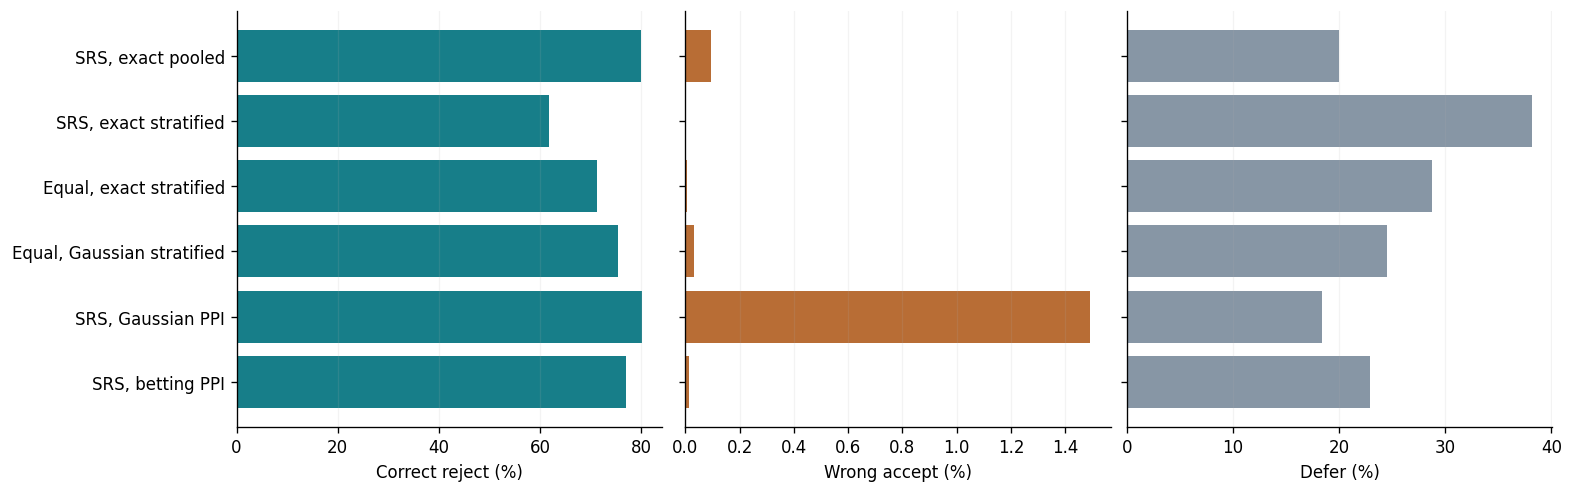

In [25]:
fig,ax=plt.subplots(1,3,figsize=(13,4),layout='constrained')
ordered=rates.reindex(list(method_name))
assert ordered.notna().all().all()
labels=list(method_name.values())
for a,column,color in zip(ax,['Correct reject (%)','Wrong accept (%)','Defer (%)'],['#177e89','#b86d35','#8796a5']):
    a.barh(labels,ordered[column],color=color);a.invert_yaxis();a.set_xlabel(column);a.grid(axis='x',alpha=.15)
for a in ax[1:]:a.set_yticklabels([])
plt.show()

## 7. Numerical checks and aggregate-input catalogue

The following assertions check the numerical summaries at their reported precision. The input catalogue lists the aggregate records used in these calculations, with separate entries for the principal experiments and sensitivity analyses.

In [26]:
# Compare recomputed or reaggregated values with the paper's actual printed cells.
printed_checks = []
def rows(number):
    table=next(t for t in evidence['main_tables'] if t['number']==number)
    return [[value for span,value in row] for row in table['rows']]

def printed(value, cell, location):
    text=cell.replace('$','').replace(',','').replace('{','').replace('}','').strip()
    text=text.replace(r'\times10^','e')
    text=re.sub(r'^10\^([+-]?\d+)$',r'1e\1',text)
    text=re.sub(r'^<10\^([+-]?\d+)$',r'<1e\1',text)
    text=text.replace(r'^\dagger','')
    match=re.fullmatch(r'(<)?([+-]?(?:\d+(?:\.\d*)?|\.\d+))(?:e([+-]?\d+))?',text)
    assert match, (location,cell)
    less,mantissa,exponent=match.groups()
    power=int(exponent or 0)
    target=float(mantissa)*10**power
    decimals=len(mantissa.split('.')[1]) if '.' in mantissa else 0
    tolerance=.500001*10**(power-decimals)+1e-14
    valid=value<target if less else abs(value-target)<=tolerance
    assert valid,(location,value,cell)
    printed_checks.append({'Table':location.split()[0],'Cell':location,'Calculated':float(value),'Printed':cell})

cohort_ids={'Texas':'texas','Texas-100X':'texas','eICU':'eicu','MIMIC':'mimic','MIMIC-III':'mimic'}
for r in rows('III')[1:]:
    d=cohort_ids[r[0]]
    for value,cell,label in [(analytic[d],r[1],'analytic'),(test.loc[d,'records'],r[2],'test'),
            (test.loc[d,'positive_outcomes'],r[3].split()[0],'positives'),
            (100*test.loc[d,'positive_outcomes']/test.loc[d,'records'],r[3].split('(')[1].rstrip(')'),'prevalence')]:
        printed(value,cell,f'III {d} {label}')

engines=['run_compressed','indexed','direct']
stress=frame('scaling_stress').set_index('method')
traces=frame('clinical_trace_times').set_index(['cohort','method'])
single=frame('workflow_single').set_index('method')
repeat_times=frame('workflow_repetitions').groupby('method').total.median()
candidate=frame('candidate_timings').groupby(['cohort','method']).computation_seconds.median()
for index,method in enumerate(engines):
    r=rows('IV')[2+index]
    for field,cell in zip(['completed_queries','process_wall_seconds','peak_rss_mib'],r[1:]):
        printed(stress.loc[method,field],cell,f'IV stress {method} {field}')
    printed(single.loc[method,'total_seconds'],rows('IV')[11][1+index],f'IV workflow {method}')
    printed(repeat_times[method],rows('IV')[13][1+index],f'IV repetitions {method}')
    for offset,d in enumerate(['texas','eicu','mimic']):
        printed(traces.loc[(d,method),'total_seconds'],rows('IV')[7+offset][1+index],f'IV trace {d} {method}')
        printed(candidate.loc[(d,method)],rows('IV')[15+offset][1+index],f'IV candidates {d} {method}')

d=None
for r in rows('V')[1:]:
    if r[0]: d=cohort_ids[r[0]]
    if r[1] in ['EB','JP']:
        law={'EB':'plugin_binomial','JP':'jeffreys_predictive'}[r[1]]
        x=principal[(principal.dataset==d)&(principal.law==law)].iloc[0]
        values=x[['r_any','c_mean','c_all']].to_numpy(float)
    else:
        candidates=frame('primary_texas_bootstrap').query('seed==11') if d=='texas' else bu[bu.dataset==d]
        law={'texas':'empirical_hospital_bootstrap','eicu':'empirical_unit_bootstrap','mimic':'empirical_row_bootstrap'}[d]
        x=candidates[candidates.law==law]
        assert len(x)==1
        values=100*x.iloc[0][['r_any','c_mean','c_all']].to_numpy(float)
    for label,value,cell in zip(['change','mean','all'],values,r[2:]):printed(value,cell,f'V {d} {r[1]} {label}')
for r in rows('VI')[1:]:
    for value,cell in zip(feasible.loc[cohort_ids[r[0]]].iloc[:5],r[1:]):printed(value,cell,f'VI {r[0]} {cell}')

method_ids=['uaf_cp_rule','cc_support_1','cc_bootstrap','um_predictive_wrapper']
clinical_means=all_rules[~all_rules.scenario.str.startswith('syn_')].groupby(['scenario','method'])[metrics].mean()
synthetic_means=synthetic.groupby('method')[metrics].mean()
scenarios=[None]+[f'{d}_iid_f{f}' for d in ['texas','eicu','mimic'] for f in ['025','050','100']]
for r,scenario in zip(rows('VII')[1:],scenarios):
    for method,cell in zip(method_ids,r[3:]):
        values=synthetic_means.loc[method] if scenario is None else clinical_means.loc[(scenario,method)]
        for field,part in zip(['correct_resolution','any_wrong'],cell.split('/')):
            printed(100*values[field],part.strip(),f'VII {scenario or "synthetic"} {method} {field}')

for column,d in enumerate(['texas','eicu'],1):
    x=frame('source_fits').set_index('dataset').loc[d]
    values={1:x.supported_hospitals,2:100*x.mean_gap,3:1000*x.observed_cell_sampling_variance,
        4:1000*x.site_variance,7:100*(.10-abs(x.mean_gap)),8:x.sampling_constant,
        9:1000*((.10-abs(x.mean_gap))/norm.isf(.025))**2}
    for index,value in values.items():printed(value,rows('VIII')[index][column],f'VIII {d} row {index}')
    for value,part in zip([100*x.observed_cell_sampling_shapley,100*x.observed_cell_site_shapley],rows('VIII')[5][column].split('/')):
        printed(value,part,f'VIII {d} Shapley')
printed(621,rows('VIII')[10][2],'VIII eICU sufficient count')

grid_result=frame('planning_grids').query("rule=='primary'").set_index(['dataset','grid','policy'])
for i,d in enumerate(['texas','eicu','mimic']):
    for j,grid in enumerate(['coarse','intermediate25','sparse']):
        r=rows('IX')[1+3*i+j]
        for policy,cell in zip(['dp','balance','oracle'],r[2:5]):
            printed(100*grid_result.loc[(d,grid,policy),'correct_resolution'],cell,f'IX {d} {grid} {policy}')
        completed=int(grid_result.loc[(d,grid,'dp'),'records'])
        assert int(r[5].split('/')[0])==completed
        assert int(r[6].split('/')[0])==int(grid_result.loc[(d,grid,'dp'),'group_loss_pilots_gt_1pp'])
same40=frame('planning_same40').query("rule=='primary'").set_index('grid')
for r,grid in zip(rows('IX')[11:],['coarse','intermediate25','sparse']):
    for field,cell in zip(['dp_correct_percent','balancing_correct_percent','oracle_correct_percent'],r[2:5]):
        printed(same40.loc[grid,field],cell,f'IX same40 {grid} {field}')

for r in rows('X')[1:]:
    d=cohort_ids[r[0]]; cap,budget=[int(x.strip()) for x in r[1].split('/')]
    selected=records[(records.dataset==d)&(records.pilot_cap==cap)&(records.budget==budget)]
    p=plan[(plan.dataset==d)&(plan.pilot_cap==cap)&(plan.budget==budget)]
    printed(selected.cost.mean(),r[2],f'X {d} {cap}/{budget} reviews')
    for policy,part in zip(['dp','balance','greedy','oracle'],r[3].split('/')):
        printed(100*selected[selected.policy==policy].correct_resolution.mean(),part.strip(),f'X {d} {cap}/{budget} {policy}')
    printed(100*selected[selected.policy=='dp'].any_wrong_full.mean(),r[4],f'X {d} {cap}/{budget} error')
    printed(p['Forecast width'].mean(),r[5],f'X {d} {cap}/{budget} width')
    assert [int(x.strip()) for x in r[6].split('/')]==[int((p.Forecast==state).sum()) for state in ['Met','Not met','Unresolved']]

safe=frame('factorial_safeguards')
assert len(safe)==640 and not safe.safe_selects_dp.any() and safe.correct_lower.max()<=0
for r,policy in zip(rows('XI')[1:],['balance','dp','constrained','switch','balance']):
    f=factorial[factorial.policy==policy]
    loss=group_minimum.loc[policy]
    printed(100*f.correct_resolution.mean(),r[1],f'XI {r[0]} mean')
    printed(100*f.all_correct_resolution.mean(),r[2],f'XI {r[0]} all')
    assert r[3]==f'{int((loss < -1e-10).sum())}/640'
    printed(max(0,-100*loss.min()),r[4],f'XI {r[0]} worst')
for r in rows('XII')[1:]:
    for column,cell in zip(rates.columns,r[1:]):printed(rates.rename(index=method_name).loc[r[0],column],cell,f'XII {r[0]} {column}')

record('Printed numerical cells in main Tables III–XII',len(printed_checks)>250,
       'Calculated/reaggregated values checked against the source table cells at printed precision')
display(pd.DataFrame(printed_checks).groupby('Table',sort=False).size().rename('Numeric cells checked').to_frame())

,Numeric cells checked
Table,
III,12
IV,33
V,27
VI,15
VII,80
VIII,19
IX,36
X,56
XI,15


In [27]:
display(pd.DataFrame(checks))
display(pd.DataFrame(evidence['provenance']).drop(columns=['source_sha256','embedded_sha256']))

,Check,Status,Scope
0,Embedded numerical evidence integrity,Passed,Aggregate-file checksums and row counts
1,Main Table III,Passed,Reconstructed from all 12 partition records
2,Stored partition and preprocessing checks,Passed,Rechecked exported audit results; no raw patie...
3,Predictive confusion-count consistency,Passed,12 frozen fits; score metrics retained from re...
4,All 234 exact family forecasts,Passed,Fresh count-law integration
5,Main Table V,Passed,All six EB/JP rows recomputed; three unit-boot...
6,Main Tables IV and VI,Passed,Saved phase-cost arithmetic and feasibility pa...
7,Main Table VII,Passed,"Recomputed summaries from 39,200 audit-method ..."
8,Main Table VIII,Passed,Fitted risks and sufficient counts recomputed;...
9,Hospital-binomial simulation counts,Passed,Reaggregated recorded simulation fits


,key,source,rows,columns
0,comparisons,comparison_counts276.csv,276,36
1,comparison_probabilities,exact_comparison_probabilities1656.csv,1656,24
2,all_forecasts,exact_forecasts234.csv,234,27
3,all_feasibility,feasibility117.csv,117,21
4,comparison_feasibility,comparison_feasibility828.csv,828,20
5,partitions,partition_counts.csv,12,7
6,flow,participant_flow.csv,19,5
7,categories,test_category_composition.csv,105,10
8,saved_unit_laws,family_results.csv,228,28
9,primary_texas_bootstrap,current_texas_seed_transitions.csv,9,28


## 8. Complete technical-companion evidence catalogue

This reference section contains every numbered companion table, every displayed scientific figure, and the main table definitions. Tables are converted from the frozen manuscript source without changing numbers. Figures are rendered from the original figure files, not redrawn from invented data. Their displayed values remain those of the original experiment. Historical analyses are retained under their original section titles and must not be pooled with later corrected designs.

For a numerical question, locate the matching section below and expand its exhibits. The full arrays used by the current calculations are available through `frame(key)`; Section 7 lists the keys. Where a companion experiment is available only as a reported table in this notebook, that table is documentation rather than a freshly executed check. The code never labels document display as experiment replication.

In [28]:
catalogue=pd.DataFrame([{'Section':t['section'],'Table':t['number'],'Caption':t['caption']} for t in evidence['supp_tables']])
display(catalogue)
assert len(catalogue)==len(evidence['supp_tables'])

,Section,Table,Caption
0,Evidence index,S1,Current-analysis index. Main-paper analyses ar...
1,"Cohorts, prediction settings and audit definit...",S2,Development partitions. Outcomes are stays exc...
2,"Cohorts, prediction settings and audit definit...",S3,Verified prediction-model settings. A dash mea...
3,"Cohorts, prediction settings and audit definit...",S4,Predictive performance of all twelve fixed see...
4,Protected-category denominators,S5,Texas-100X held-out demographic support. Posit...
...,...,...,...
96,Matched finite-sample prediction-powered review,S97,Complete declared-workflow times in seconds. A...
97,Current workload and decision diagnostics,S98,All nonempty direction/truth strata. Entries a...
98,Current workload and decision diagnostics,S99,Correct resolution (%) on the same 40 Texas $B...
99,Current workload and decision diagnostics,S100,Exploratory decision-loss sensitivity. Each me...


### Cohorts, prediction settings and audit definitions

**How were cohorts, predictions and thresholds defined?** Section 2 gives the complete model search, selected settings, preprocessing, partitions and calibration rule. These tables retain all predictive metrics, group operating points and sensitivity settings; timing-available ICU features are distinct from the exploratory Texas diagnosis model.

Cohort,Count,Training,Tuning,Threshold selection,Test
Texas-100X,Discharge records,"549,370","106,239","98,212","169,933"
,Positive outcomes,"251,498","45,991","42,923","75,316"
,Hospitals,241,66,66,66
eICU,ICU stays,"61,714","13,309","15,619","20,572"
,Positive outcomes,"5,495","1,291","1,303","1,792"
,Hospitals,113,31,31,32
MIMIC-III,Patients,"17,773","4,847","4,847","4,848"
,Positive outcomes,"1,854",498,473,541
,Hospitals,1,1,1,1


Model,Search and fixed settings,Selected Texas / eICU / MIMIC,Optimization
Logistic regression,"$C\in\{0.1,1\}$; $L_2$ penalty; training-only standardization and sparse categorical encoding",$1/0.1/0.1$,"LBFGS; at most 1,000 iterations"
XGBoost,"Depth $\{3,6\}$; at most 1,000 trees; learning rate 0.05; row/column subsampling 0.8; child weight 10; $L_2=1$",Depth $6/6/6$,Histogram method; 40-round early stopping; four CPU threads or recorded GPU
MLP,"Two hidden layers; width $\{64,128\}$; ReLU; dropout 0.1",-- / 64 / 128,"AdamW; batches 2,048"
Residual network,"Two residual blocks; width $\{64,128\}$; dropout 0.1",-- / 128 / 128,"AdamW; batches 2,048"
Attention,"Two pre-normalized blocks; four heads; width $\{16,32\}$; GELU; dropout 0.1",-- / 32 / 16,AdamW; batches 256



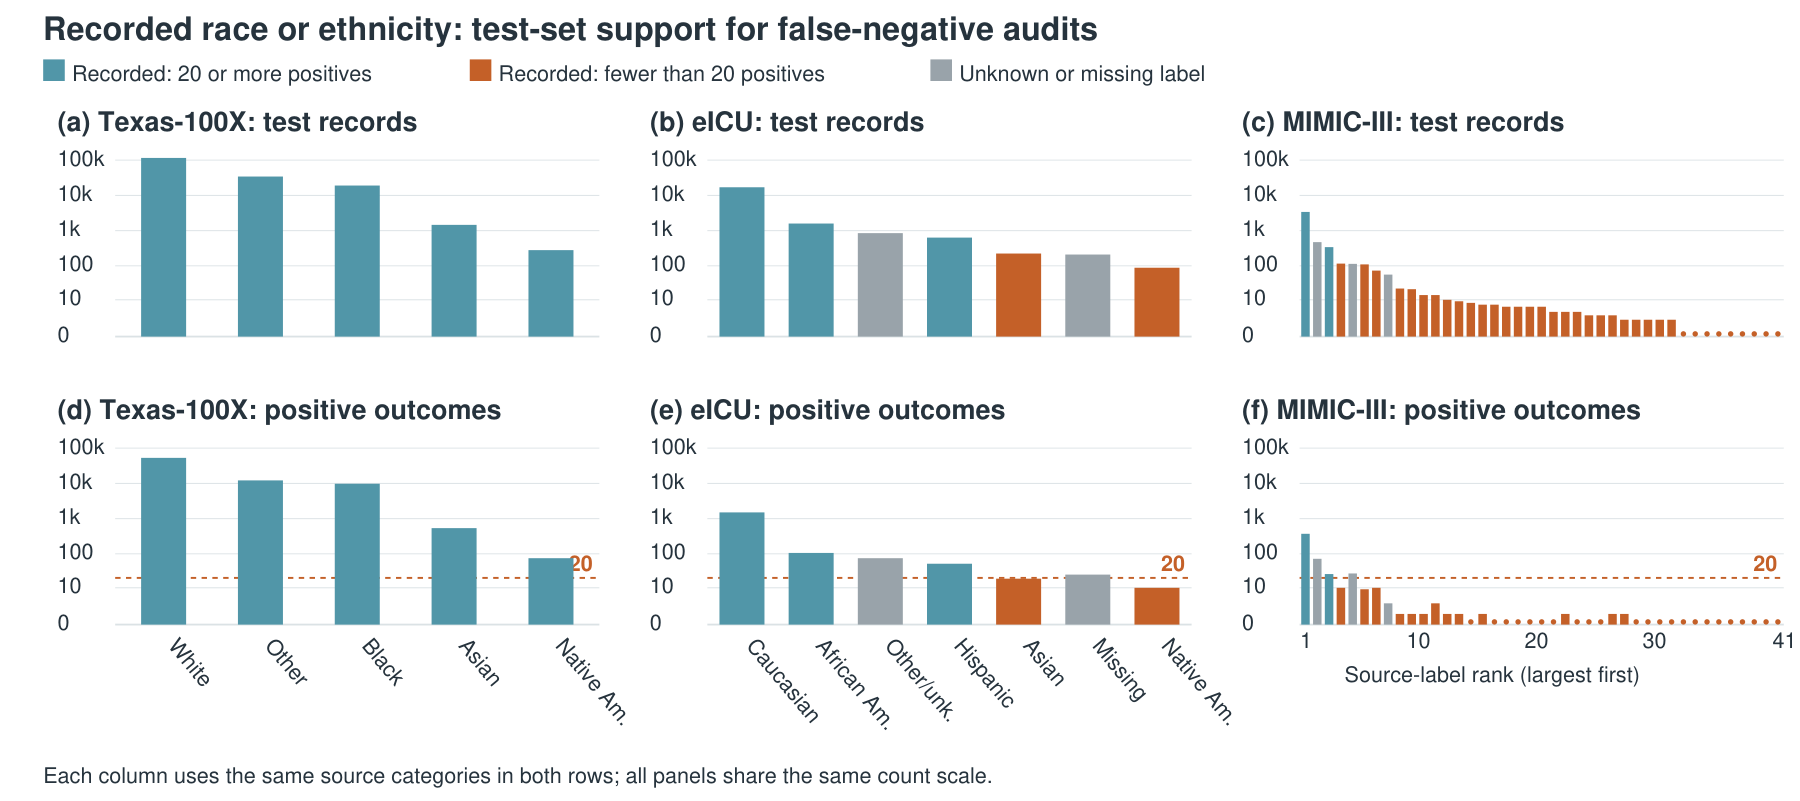

In [29]:
section_title = 'Cohorts, prediction settings and audit definitions'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

### Protected-category denominators

**Which groups and denominators were actually audited?** Every source category is retained. Records, positive outcomes and reference groups determine whether each FNR, FPR or selection-rate contrast is defined. Missing identities and zero-support groups remain explicit instead of being discarded.

In [30]:
section_title = 'Protected-category denominators'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Attribute,Recorded category,Records,Positive outcomes,Outcome (%)
Sex/gender,Female,"109,571","44,004",40.16
Sex/gender,Male (ref),"60,362","31,312",51.87
Age,0-17,"5,686","1,528",26.87
Age,18-39,"46,505","8,925",19.19
Age,40-64 (ref),"53,890","24,873",46.16
Age,65-79,"41,552","24,554",59.09
Age,80+,"22,300","15,436",69.22
Race,Asian,"1,458",540,37.04
Race,Black,"19,005","9,779",51.45
Race,Native American,280,75,26.79


Attribute,Recorded category,Records,Positive outcomes,Outcome (%)
Sex/gender,Female,"9,578",861,8.99
Sex/gender,Male (ref),"10,984",930,8.47
Sex/gender,Other,0,0,Unavailable
Sex/gender,Unknown,10,1,10.00
Age,18-39,"1,843",74,4.02
Age,40-64 (ref),"7,924",521,6.57
Age,65-79,"6,778",680,10.03
Age,80+,"4,027",517,12.84
Ethnicity,African American,"1,595",106,6.65
Ethnicity,Asian,224,19,8.48


Attribute,Recorded category,Records,Positive outcomes,Outcome (%)
Sex/gender,Female,"2,113",270,12.78
Sex/gender,Male (ref),"2,735",271,9.91
Age,18-39,480,29,6.04
Age,40-64 (ref),"1,849",150,8.11
Age,65-79,"1,499",166,11.07
Age,80+,"1,020",196,19.22
Ethnicity,AMERICAN INDIAN/ALASKA NATIVE,2,1,50.00
Ethnicity,AMERICAN INDIAN/ALASKA NATIVE FEDERALLY RECOGNIZED TRIBE,0,0,Unavailable
Ethnicity,ASIAN,73,10,13.70
Ethnicity,ASIAN - ASIAN INDIAN,10,1,10.00


Attribute,Recorded category,Records,Positive outcomes,Outcome (%)
Ethnicity,HISPANIC/LATINO - COLOMBIAN,0,0,Unavailable
Ethnicity,HISPANIC/LATINO - CUBAN,2,0,0.00
Ethnicity,HISPANIC/LATINO - DOMINICAN,6,0,0.00
Ethnicity,HISPANIC/LATINO - GUATEMALAN,0,0,Unavailable
Ethnicity,HISPANIC/LATINO - HONDURAN,0,0,Unavailable
Ethnicity,HISPANIC/LATINO - MEXICAN,2,0,0.00
Ethnicity,HISPANIC/LATINO - PUERTO RICAN,14,1,7.14
Ethnicity,HISPANIC/LATINO - SALVADORAN,3,0,0.00
Ethnicity,MIDDLE EASTERN,7,0,0.00
Ethnicity,MULTI RACE ETHNICITY,9,1,11.11


### Leakage and numerical repetition checks

**What was checked for leakage and cross-device reproduction?** Stored partition-overlap and preprocessing checks are rechecked above. Raw timestamp audits and device-replay evidence are recorded results here. Texas patient linkage and prospective timing remain unavailable; CPU/GPU differences are not hidden.

In [31]:
section_title = 'Leakage and numerical repetition checks'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Check,Executed evidence,Scope boundary
Partition separation,48 required cross-partition identifier checks; zero shared IDs,Texas patient linkage unavailable; MIMIC hospital intentionally shared
Training preprocessing,All 3 saved preprocessors match training-only refits exactly,Does not remove exploratory feature-view selection
Recorded availability,"210,879,247 eICU and 330,712,483 MIMIC source rows rescanned","Clinical timestamp semantics, not a prospective deployment guarantee"
Feature reconstruction,"88 eICU summaries for 1,024 records and 40 MIMIC summaries for 32,315 patients match",eICU value reconstruction sampled; MIMIC raw-value extraction not repeated
Threshold and artifact provenance,"34 calibration thresholds reproduced; 2,458,166 saved decisions reconcile",No retraining or test-set retuning
Arithmetic reproducibility,"All 192,126 attention outputs reproduce exactly on CUDA","CPU changes 11 decisions, including 3 test decisions; all failures retained"


### C1: exact count computation and reference dependence

**Why does shared-reference integration matter?** Each group uses the same reference count, so independent marginal multiplication changes family-event probabilities. Exact integration retains that dependence under independent group-count laws; it does not justify those laws for a new hospital.

In [32]:
section_title = 'C1: exact count computation and reference dependence'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Cohort,Count law,Exact any change,Marginal product,Difference
Texas-100X,Empirical binomial,53.8039,54.1439,+0.3401
Texas-100X,Jeffreys predictive,59.8159,60.2272,+0.4113
eICU,Empirical binomial,0.3613,0.3613,+0.0000
eICU,Jeffreys predictive,3.4476,3.4491,+0.0015
MIMIC-III,Empirical binomial,0.5075,0.5075,+0.0000
MIMIC-III,Jeffreys predictive,2.8282,2.8315,+0.0033


### Hospital dependence and the population target

**Does exact computation establish future-hospital coverage?** No. Future-unit intervals and random access to a known finite frame target different populations. The tables retain coverage, errors and resolution together, including undercoverage and conservative unresolved outputs.

Cohort,Law,Units,Method,Coverage,Wrong,Resolution
texas,whole profile,66,KL,100.00,0.00,0.00
texas,whole profile,66,Count CP,45.05,4.25,55.93
texas,whole profile,66,EB,100.00,0.00,0.00
texas,whole profile,66,JK,99.75,0.00,25.61
texas,whole profile,264,KL,100.00,0.00,0.00
texas,whole profile,264,Count CP,44.40,0.30,95.43
texas,whole profile,264,EB,100.00,0.00,0.00
texas,whole profile,264,JK,99.85,0.00,64.44
texas,two stage,66,KL,100.00,0.00,0.00
texas,two stage,66,Count CP,41.05,5.00,55.09


Cohort,Equal HG / $R$ / $A$,Proportional HG / $R$ / $A$,Equal HG / lower bound (%)
Texas,"19,400 / 64.45","57,058 / 65.86",81.96
eICU,932 / 22.52,"1,720 / 23.95",83.52



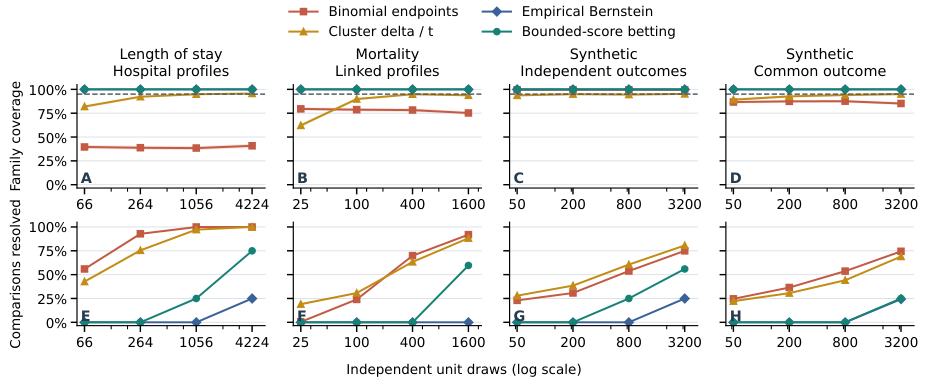

In [33]:
section_title = 'Hospital dependence and the population target'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

### C2: conditional source analysis and evidence limits

**Which variation can more observations reduce?** C2 separates fitted sampling and supported-hospital components, then attributes conditional reversal risk. Its guard is a sufficient fitted-model bound. Resampling sensitivity and unidentifiable sources limit collection recommendations.

Quantity,Texas,eICU
Mean gap and plug-in interval,"0.042707 [0.023337,0.062076]","$-0.038903$ [$-0.082167$,0.004361]"
Mean sampling variance $\overline D$,0.00236845,0.00624312
Hospital variance $\widehat v_H$,0.00435101,0.000424361
Total fixed-design risk,28.3145%,27.1620%
Hospital risk increment (share),18.4854 points (65.29%),0.7033 points (2.59%)
Sampling risk increment (share),9.8291 points (34.71%),26.4588 points (97.41%)
Sampling constant $c$ in hypothetical $c/n$,0.2736380,0.3370806


Cohort,Mean used,Sufficient guard count,Exact two-tail count
Texas,Lower endpoint 0.023337,None,None
Texas,Estimate 0.042707,None,None
Texas,Upper endpoint 0.062076,None,None
eICU,Lower endpoint $-0.082167$,None,None
eICU,Estimate $-0.038903$,616,354
eICU,Upper endpoint 0.004361,173,157


Quantity,Texas,eICU
"Observed-cell site share, point",65.29,2.59
"Observed-cell site share, hospital-pairs 2.5--97.5%",40.75--76.26,0--28.45
"Observed-cell site share, two-stage 2.5--97.5%",45.42--79.58,0--64.37
"$c/500$ site share, point",94.14,37.82
"$c/500$ site share, hospital-pairs 2.5--97.5%",82.66--95.65,0--85.42
"$c/500$ site share, two-stage 2.5--97.5%",84.70--96.86,0--97.35
"$n=500$ total risk, hospital-pairs 2.5--97.5%",8.03--34.59,.081--15.62
"Infinite-sampling risk, hospital-pairs 2.5--97.5%",5.28--33.38,0--8.22
"Finite sufficient guards, hospital-pairs",16/2000 (.80%),1620/2000 (81.0%)
"Finite sufficient guards, two-stage",15/2000 (.75%),658/2000 (32.9%)


Hospitals,"True $(\mu,v_H)$",True guard,Finite fitted / 300,Meet true guard / finite (%)
9,"(.02,0)",Finite,234,145/234 (61.97)
9,"(.02,.0004)",Finite,201,85/201 (42.29)
9,"(.085,.0004)",Nonfinite,122,0/122 (0)
58,"(.02,0)",Finite,244,184/244 (75.41)
58,"(.02,.0004)",Finite,203,117/203 (57.64)
58,"(.085,.0004)",Nonfinite,55,0/55 (0)


Source,Truth,Mean,SD,Zero (%)
Hospital,2.000,2.013,1.857,0.00
Period,1.000,1.095,0.822,0.00
Curation,0.500,0.400,0.364,3.33
Randomized model,0.300,0.230,0.291,10.00



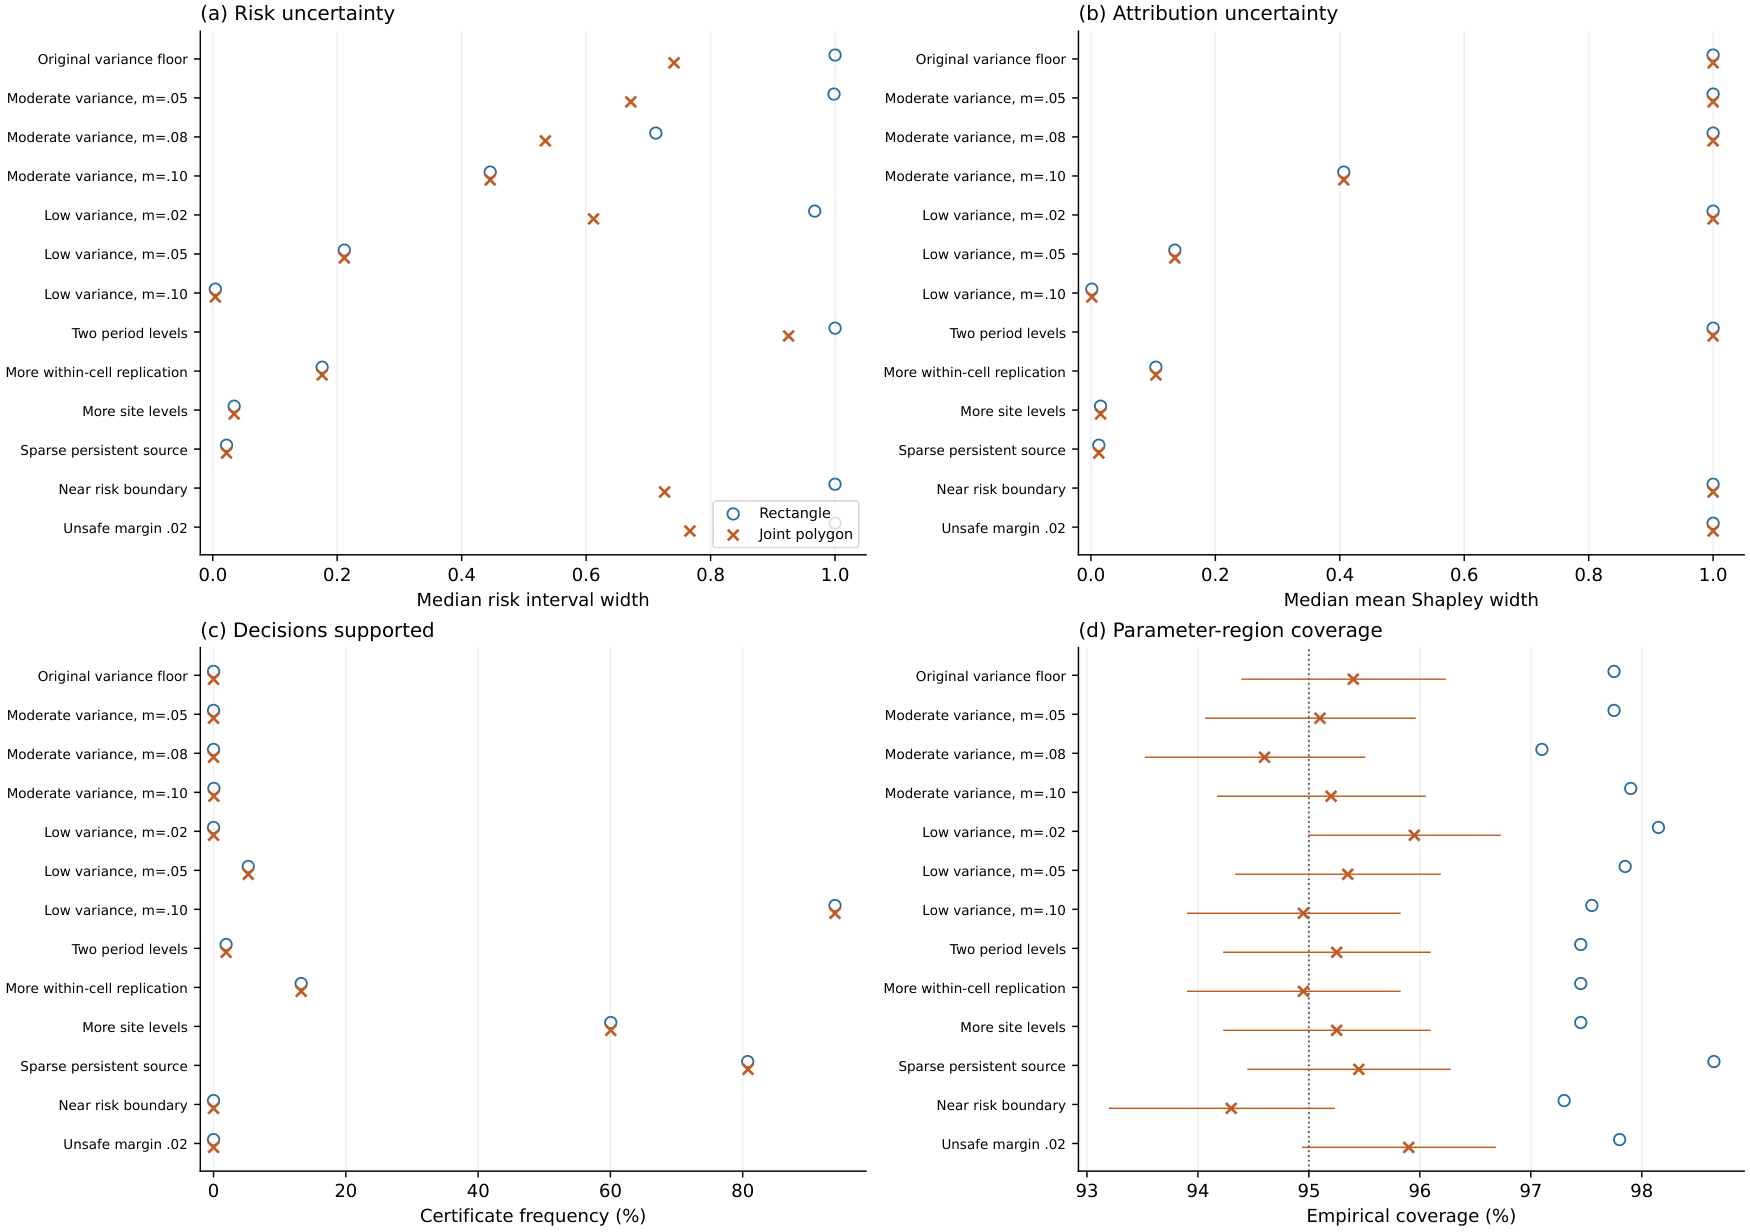

In [34]:
section_title = 'C2: conditional source analysis and evidence limits'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

### C3: confirmation allocation and forecast interpretation

**What is bought by the review budget?** The positive-frame membership and sizes are known, and review reveals prediction linkage. Pilot and confirmation costs are counted. Correct resolution, total conclusiveness and certification of a forecast are different outputs.

Cohort,Grid,Cap,Cost,I,U,L
eICU,coarse,20,475,24.227398,22.884306,30.064711
eICU,sparse,20,475,37.008597,18.490438,37.215871
eICU,coarse,200,661,37.765281,31.747494,40.402548
eICU,sparse,200,661,51.118779,41.420704,51.134494
MIMIC,coarse,20,435,39.911023,39.003559,39.911880
MIMIC,sparse,20,435,39.487777,38.419556,39.487777
MIMIC,coarse,200,508,40.002478,40.000313,40.002478
MIMIC,sparse,200,508,40.002478,40.000313,40.002478


Cohort,Grid,Cap,Mean wrong pass,Mean wrong fail,Any wrong: I,Any wrong: L
eICU,coarse,20,0.000073,0.000128,0.000697,0.001191
eICU,sparse,20,0.000268,0.000070,0.001058,0.002028
eICU,coarse,200,0.000021,0.000059,0.000310,0.000481
eICU,sparse,200,0.000021,0.000004,0.000062,0.000149
MIMIC,coarse,20,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$
MIMIC,sparse,20,0.000014,$<10^{-6}$,0.000569,0.000569
MIMIC,coarse,200,0.000009,0,0.000357,0.000357
MIMIC,sparse,200,0.000009,0,0.000357,0.000357


Cohort,Grid,Cap,Extra,Cost,DP,B,G,H,O
Texas,coarse,20,250,473,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$
Texas,coarse,200,250,1128,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$
Texas,coarse,20,2000,2223,29.03,26.44,28.80,24.98,40.16
Texas,coarse,200,2000,2878,41.64,30.23,22.55,39.12,43.58
eICU,coarse,20,250,475,26.08,24.92,26.08,25.71,27.40
eICU,sparse,20,250,475,40.76,24.92,26.08,25.71,41.73
eICU,coarse,200,250,661,37.23,37.23,37.23,33.11,37.23
eICU,sparse,200,250,661,49.29,37.23,37.23,33.11,49.98
MIMIC,coarse,20,250,435,39.89,39.89,39.89,39.89,39.89
MIMIC,sparse,20,250,435,39.45,39.89,39.89,39.89,39.89


Cohort,Grid,Cap,Extra,Width,Method,Bias,MSE,Met,Not met / I
Texas,coarse,20,250,0.9134,Envelope,+10.609,0.01621,0,0 / 20
Texas,coarse,200,250,0.1875,Envelope,+0.405,0.00004,0,5 / 15
Texas,coarse,20,2000,1.0000,Envelope,+12.791,0.03031,0,0 / 20
Texas,coarse,200,2000,0.7239,Envelope,-12.741,0.01985,0,0 / 20
eICU,coarse,20,250,0.9964,Exact,+12.487,0.01797,0,0 / 20
eICU,sparse,20,250,0.9949,Exact,+7.701,0.00878,0,0 / 20
eICU,coarse,200,250,0.9294,Exact,+1.183,0.00161,0,0 / 20
eICU,sparse,200,250,0.9053,Exact,-0.042,0.00292,0,0 / 20
MIMIC,coarse,20,250,0.4076,Exact,-3.650,0.00146,1,0 / 19
MIMIC,sparse,20,250,0.4105,Exact,-2.822,0.00095,1,0 / 19


Cohort,Cap,Extra,Within tolerance,Higher miss,Lower miss,Undefined
Texas,20,250,$<10^{-6}$ (4),0.0000 (0),0.0000 (0),0.0000 (0)
Texas,200,250,$<10^{-6}$ (4),0.0000 (0),0.0000 (0),0.0000 (0)
Texas,20,2000,29.0273 (4),0.0000 (0),0.0000 (0),0.0000 (0)
Texas,200,2000,41.6443 (4),0.0000 (0),0.0000 (0),0.0000 (0)
eICU,20,250,6.8990 (4),2.5565 (1),16.6245 (1),0.0000 (0)
eICU,200,250,17.6005 (4),2.9634 (1),16.6640 (1),0.0000 (0)
MIMIC,20,250,9.8906 (4),10.0002 (5),20.0000 (8),0.0000 (23)
MIMIC,200,250,10.0000 (4),10.0018 (5),20.0000 (8),0.0000 (23)


Cohort,Pilot cap,Cost,DP,Balancing,Greedy,Oracle
eICU,20,475,40.7614,37.3604,37.3604,41.7258
eICU,200,661,49.2879,49.7879,49.7879,49.9782
MIMIC,20,435,39.4455,39.4240,39.4240,39.8908
MIMIC,200,508,40.0927,40.1168,40.1168,40.1168


... (10 outputs left out)

Cohort,Cap,Extra,Cost,DP,Balance,Uniform,Oracle,Gain,MCSE
Texas,20,250,473,0.001758,0.000535,0.000535,0.004373,$<.01$,$<.01$
Texas,200,250,1128,0.003149,0.000532,0.000532,0.004358,$<.01$,$<.01$
Texas,20,2000,2223,10.96,10.85,10.85,23.13,0.10,0.81
Texas,200,2000,2878,19.06,12.20,12.20,23.24,6.86,0.74
eICU,20,250,475,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$,$<.01$,$<.01$
eICU,200,250,661,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$,$<.01$,$<.01$
MIMIC,20,250,435,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$,0.00,0.00
MIMIC,200,250,508,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$,$<10^{-6}$,0.00,0.00


Cohort,Cap,Extra,Allocation,Resolution,Wrong P,Wrong F,Any wrong
Texas,20,250,DP,0.001822,0,0.001822,0.007288
Texas,20,250,Balance,0.000587,0,0.000587,0.002346
Texas,20,250,Uniform,0.000587,0,0.000587,0.002346
Texas,20,250,Original oracle,0.004411,0,0.004411,0.017644
Texas,200,250,DP,0.002875,0,0.002874,0.011496
Texas,200,250,Balance,0.000539,0,0.000539,0.002154
Texas,200,250,Uniform,0.000539,0,0.000539,0.002154
Texas,200,250,Original oracle,0.004051,0,0.004051,0.016203
Texas,20,2000,DP,24.98,0,0.000176,0.000705
Texas,20,2000,Balance,26.44,0,0.000103,0.000410


Evaluation,Design / extra cost,Raw / forecast (%),Corrected / (%),Expected / DP (%),Balancing / (%),MSE / raw / corrected
Original simulation,Stable; 32 settings,36.71,23.00,24.44,23.83,0.0436 / 0.0278
Original simulation,Shifted; 32 settings,36.71,23.00,19.43,18.12,0.0525 / 0.0211
Texas-100X,250,10.35,4.21,0.002,$<$0.001,0.0159 / 0.0033
Texas-100X,500,16.03,7.41,0.002,$<$0.001,0.0346 / 0.0089
Texas-100X,1000,23.44,11.68,0.055,$<$0.001,0.0669 / 0.0200
Texas-100X,2000,34.47,18.77,11.98,9.74,0.0626 / 0.0140
eICU,250,4.22,1.20,$<$0.001,$<$0.001,0.0033 / 0.0005
eICU,500,6.02,1.99,$<$0.001,$<$0.001,0.0060 / 0.0010
eICU,1000,7.43,2.67,$<$0.001,$<$0.001,0.0085 / 0.0015


Setting,Forecast,Predicted,Expected,Bias (points),MSE
Simulation shifted,Original raw,36.4228,19.4479,16.9749,0.0506238
Simulation shifted,Frozen isotonic,22.7812,19.4479,3.3333,0.0201461
Simulation shifted,Expanded binomial,24.9615,19.4479,5.5136,0.0208598
Simulation shifted,Expanded predictive,26.4379,19.4479,6.9900,0.0191669
Simulation stable,Original raw,36.4228,24.5661,11.8567,0.0416972
Simulation stable,Frozen isotonic,22.7812,24.5661,-1.7848,0.0269726
Simulation stable,Expanded binomial,24.9615,24.5661,0.3955,0.00739114
Simulation stable,Expanded predictive,26.4379,24.5661,1.8718,0.00699687
eICU 250,Original raw,4.2167,0.0000,4.2167,0.00326172
eICU 250,Frozen isotonic,1.2021,0.0000,1.2021,0.000481563



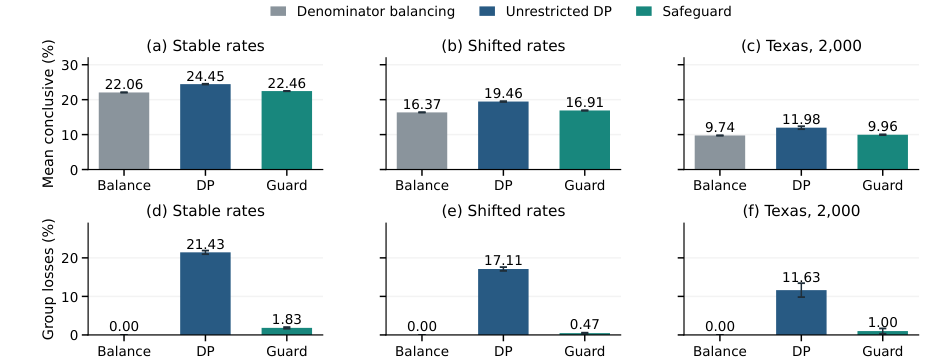


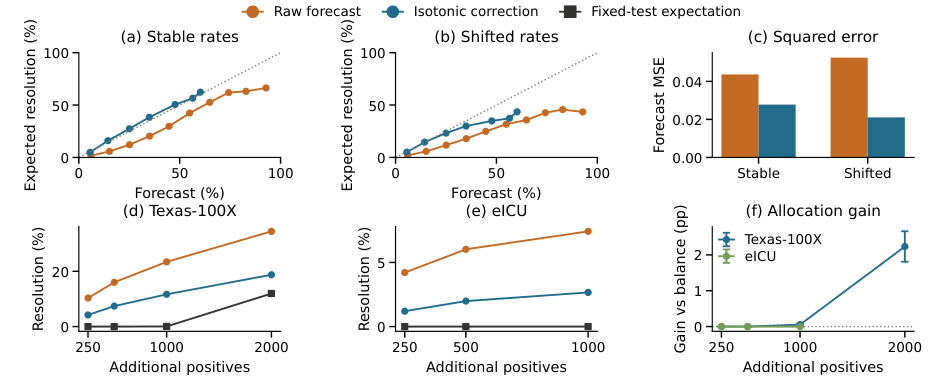

In [35]:
section_title = 'C3: confirmation allocation and forecast interpretation'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

### C4: intervention targets, errors and review costs

**What does policy review accept or reject?** Reviewed disagreement outcomes bound incremental detections and false alerts under a declared criterion. Acquisition and inference are compared at matched costs. This is a policy-audit conclusion, not a treatment-effect estimate.

In [36]:
section_title = 'C4: intervention targets, errors and review costs'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Cohort,Contrast,Seed,Changed,Cohort (%),$\Delta TP$,$\Delta FP$,Groups with a net miss increase
eICU,B vs O,11,66,0.321,6,60,0
eICU,G vs B,11,188,0.914,1,67,2
eICU,G vs O,11,250,1.215,7,127,2
eICU,B vs O,29,66,0.321,5,61,0
eICU,G vs B,29,207,1.006,1,30,2
eICU,G vs O,29,265,1.288,6,91,2
eICU,B vs O,47,20,0.097,-1,-19,1
eICU,G vs B,47,246,1.196,1,37,2
eICU,G vs O,47,230,1.118,0,18,2
MIMIC-III,B vs O,11,61,1.258,-7,-54,3


Budget (%),$w$,Review,Resolved,Supported,Error,Records
1,0,point uniform,1.314,0.181,0.181,126.50
1,0,targeted,96.919,11.111,0.000,99.83
1,0,uniform,26.800,0.572,0.000,126.50
1,0.1,point uniform,1.314,0.736,0.736,126.50
1,0.1,targeted,96.919,0.000,0.000,99.83
1,0.1,uniform,4.814,0.000,0.000,126.50
1,0.25,point uniform,1.314,0.736,0.736,126.50
1,0.25,targeted,96.919,0.000,0.000,99.83
1,0.25,uniform,4.814,0.000,0.000,126.50
1,1,point uniform,1.314,0.725,0.725,126.50


Cases / budget,Mean actual reviews,Equal,Proportional,Uniform
All 18 / .5% maximum,54.4444,85.5389,85.2444,2.3778
15 below census / .5% maximum,55.2000,82.6467,82.2933,2.8533
All 18 / disagreement census,141.7778,100,100,9.07


Recorded category,$\Delta TP$,$\Delta FP$,$\Delta$FNR,$\Delta$FPR,$\Delta$PPV
BLACK/AFRICAN AMERICAN,$-5$,$-58$,$+19.23$,$-18.41$,$+4.51$
UNKNOWN/NOT SPECIFIED,$+3$,$+27$,$-4.17$,$+6.73$,$-2.71$
WHITE,$-4$,$-44$,---,---,---


### Historical reweighing and protocol separation

In [37]:
section_title = 'Historical reweighing and protocol separation'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Cohort,Model,Weighting,Seed,Support,Improved,Worsened,Same
texas,LR,Age/outcome independence,11,31/66,31,0,0
texas,LR,Age/outcome independence,29,31/66,31,0,0
texas,LR,Age/outcome independence,47,31/66,31,0,0
texas,LR,Uniform age/outcome,11,31/66,31,0,0
texas,LR,Uniform age/outcome,29,31/66,31,0,0
texas,LR,Uniform age/outcome,47,31/66,31,0,0
texas,LR,Demographic cells,11,31/66,31,0,0
texas,LR,Demographic cells,29,31/66,31,0,0
texas,LR,Demographic cells,47,31/66,31,0,0
texas,XGB,Age/outcome independence,11,31/66,31,0,0


### Additional retrospective policy and paired-planning validation

In [38]:
section_title = 'Additional retrospective policy and paired-planning validation'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Recorded category,Positives,Negatives,Added TP,Added FP
African American,106,1489,4,99
Asian,19,205,2,18
Caucasian,1505,15463,96,1249
Hispanic,52,585,4,41
Missing,25,185,4,16
Native American,10,78,0,5
Other/Unknown,75,775,5,52


### Reproducibility and scope

In [39]:
section_title = 'Reproducibility and scope'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

False-alert weight,Review and inference,Correct accept,Wrong accept,Correct reject,Wrong reject,Defer
0.1,Equal,0.000,0.000,71.160,0.000,28.840
,Proportional,0.000,0.000,61.767,0.000,38.233
,Whole-cohort SRS,0.000,0.000,39.876,0.000,60.124
,"Disagreement SRS, stratified",0.000,0.000,61.688,0.000,38.312
,"Disagreement SRS, pooled",0.000,0.095,80.083,0.000,19.821
0.05,Equal,22.338,0.000,50.995,0.000,26.667
,Proportional,15.100,0.000,50.495,0.000,34.405
,Whole-cohort SRS,0.169,0.000,39.757,0.000,60.074
,"Disagreement SRS, stratified",14.929,0.000,50.893,0.000,34.179
,"Disagreement SRS, pooled",34.164,0.000,50.893,0.005,14.938


Weight,Method,Correct reject (%),Wrong accept (%),Defer (%)
0.1,Equal,98.200,0.000,1.800
,Proportional,97.133,0.000,2.867
,Whole-cohort SRS,6.167,0.000,93.833
,"Disagreement SRS, stratified",97.408,0.000,2.592
0.05,Equal,98.200,0.000,1.800
,Proportional,97.133,0.000,2.867
,Whole-cohort SRS,6.167,0.000,93.833
,"Disagreement SRS, stratified",97.408,0.000,2.592


Cohort,Pilot,Extra,Replicate,Work position,Original bounds,Exact bounds
eicu,20,250,03,minimum,"[-16.969, 31.801]","[-16.479, 15.134]"
eicu,20,250,12,lower median,"[-33.636, 47.144]","[-16.479, 14.970]"
eicu,20,250,17,maximum,"[-33.626, 46.889]","[-16.446, 14.877]"
texas,20,250,04,minimum,"[-50.000, 50.000]","[-24.488, 9.029]"
texas,20,250,12,lower median,"[-98.198, 82.272]",--
texas,20,250,18,maximum,"[-99.807, 94.702]",--
texas,20,2000,04,minimum,"[-100.000, 100.000]",--
texas,20,2000,08,lower median,"[-100.000, 100.000]",--
texas,20,2000,18,maximum,"[-100.000, 100.000]",--
texas,200,250,11,minimum,"[-14.778, 23.186]","[-0.810, 9.219]"


Statement,Randomization and conditioning,Controlled event,Error budget
C1 repeat probabilities,Supplied independent group-count laws and fixed audit rule,Numerical calculation of specified state probabilities,No population-coverage claim
C3 forecast or gain enclosure,Pilot sampling from a fixed recorded frame; all pilot-selected plans use the same region,Candidate-total region covers truth and hence the selected forecast/gain,$\eta$
C3 conclusive gap decisions,Fresh uniform confirmation conditional on the pilot and selected fixed allocation,No incorrect full-frame assertion across declared comparisons,$\alpha$
Forecast and confirmation together,Both randomizations; no independence assumption needed,Both preceding events hold,At most $\eta+\alpha$
C4 paired policy decision,Fixed policy and budget; random outcome review in the declared frame,Supported criterion decision agrees with complete-frame truth,$\alpha$ per fixed comparison


### Matched comparison of uncertainty-based audit rules

In [40]:
section_title = 'Matched comparison of uncertainty-based audit rules'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

### Additional numerical detail retained from the conference condensation

In [41]:
section_title = 'Additional numerical detail retained from the conference condensation'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Component,Method and comparator,Matched inputs,Outcome and result section
C1,"Count-region computation versus enumeration, direct integration and shared-reference Monte Carlo; marginal-product ablation","Count law, decision map, support; setup and reuse measured separately",Probability error/runtime; coverage and resolution under each sampling design (main results)
C2,"REML/Shapley/guards versus supplied truth, exhaustive calculations and joint resampling","Replication, variances, margin and sampling intervention","Recovery, attribution sensitivity and finite-guard reliability (main results)"
C3,"Full-frame DP versus balancing, whole-objective greedy and truth-total oracle; predictive and confidence safeguards; direct-gap sensitivity","Pilot, total review cost, capacities, grid and target cohort","Correct/wrong conclusions, group losses, forecast error and target attainment (main results)"
C4,Reweighing/group thresholds versus unweighted/global/alert-matched predictions; equal/proportional versus disagreement/whole-cohort SRS; known-direction pooling,"Features/partitions, frozen scores, actual review counts and criterion",Signed error/alert changes and supported criterion decisions (main results)


### Additional structural, support-gate and bounded scalability checks

In [42]:
section_title = 'Additional structural, support-gate and bounded scalability checks'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Cohort,Repetition law,$100r_{\rm any}$,$100Gc_{\rm mean}$,Difference
eICU,Empirical binomial,.361288560,.361336782,.000048222
,Jeffreys predictive,3.447644164,3.466357293,.018713129
,Unit bootstrap,.780078008,.780078008,0
MIMIC-III,Empirical binomial,.507498001,.507513317,.000015316
,Jeffreys predictive,2.828192830,2.840309814,.012116984
,Row bootstrap,.440044004,.440044004,0


### Post-review blocked direct comparator

In [43]:
section_title = 'Post-review blocked direct comparator'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

### Complete family inventory and deterministic tolerance sensitivity

In [44]:
section_title = 'Complete family inventory and deterministic tolerance sensitivity'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Cohort,Attribute,Metric,$\delta$,$G$,$Z$,$P^-$,$F^-$,$U$,Obs. P/I/F,Ceiling
Texas,Sex,FNR,0.05,1,0,0,0,0,1/0/0,100
Texas,Sex,FNR,0.10,1,0,0,0,0,1/0/0,100
Texas,Sex,FNR,0.15,1,0,0,0,0,1/0/0,100
Texas,Sex,FPR,0.05,1,0,0,0,0,0/0/1,100
Texas,Sex,FPR,0.10,1,0,0,0,0,0/0/1,100
Texas,Sex,FPR,0.15,1,0,0,0,0,0/0/1,100
Texas,Sex,SPD,0.05,1,0,0,0,0,0/0/1,100
Texas,Sex,SPD,0.10,1,0,0,0,0,0/0/1,100
Texas,Sex,SPD,0.15,1,0,0,0,0,0/0/1,100
Texas,Age,FNR,0.05,4,0,0,0,0,0/0/4,100


Cohort,Attribute,Metric,$\delta$,EB R,EB M,EB A,JP R,JP M,JP A
Texas,Sex,FNR,0.05,3.278,96.72,96.72,9.629,90.37,90.37
Texas,Sex,FNR,0.10,$1.80\!\times\!10^{-87}$,100,100,$5.85\!\times\!10^{-44}$,100,100
Texas,Sex,FNR,0.15,0,100,100,$4.28\!\times\!10^{-161}$,100,100
Texas,Sex,FPR,0.05,0,100,100,$2.79\!\times\!10^{-307}$,100,100
Texas,Sex,FPR,0.10,0,100,100,$7.23\!\times\!10^{-162}$,100,100
Texas,Sex,FPR,0.15,$7.86\!\times\!10^{-126}$,100,100,$7.12\!\times\!10^{-63}$,100,100
Texas,Sex,SPD,0.05,0,100,100,0,100,100
Texas,Sex,SPD,0.10,$1.35\!\times\!10^{-293}$,100,100,$1.08\!\times\!10^{-145}$,100,100
Texas,Sex,SPD,0.15,$5.22\!\times\!10^{-58}$,100,100,$6.69\!\times\!10^{-29}$,100,100
Texas,Age,FNR,0.05,$1.48\!\times\!10^{-100}$,100,100,$2.73\!\times\!10^{-50}$,100,100


Cohort,Attribute,Metric,Unit R,Unit M,Unit A,Row R,Row M,Row A
Texas,Sex,FNR,0,100,100,0,100,100
Texas,Sex,FPR,0,100,100,0,100,100
Texas,Sex,SPD,0.05003,100,100,0,100,100
Texas,Age,FNR,0.1501,99.96,99.85,0,100,100
Texas,Age,FPR,0,100,100,0,100,100
Texas,Age,SPD,0,100,100,0,100,100
Texas,Race,FNR,72.14,55.59,4.29,54.55,59.19,0.03
Texas,Race,FPR,57.18,58.3,2.601,3.652,50.91,0
Texas,Race,SPD,66.33,64.23,9.305,8.604,52.18,0.1001
Texas,Ethnicity,FNR,34.62,68.83,68.83,3.902,96.1,96.1


Cohort,Split,Records,Positive outcomes,Hospitals,Patients
Texas,calibration,"98,212","42,923",66,---
Texas,test,"169,933","75,316",66,---
Texas,train,"549,370","251,498",241,---
Texas,tune,"106,239","45,991",66,---
eICU,calibration,"15,619","1,303",31,"13,718"
eICU,test,"20,572","1,792",32,"18,118"
eICU,train,"61,714","5,495",113,"54,181"
eICU,tune,"13,309","1,291",31,"11,939"
MIMIC,calibration,"4,847",473,1,"4,847"
MIMIC,test,"4,848",541,1,"4,848"


Cohort,Stage,Remaining,Excluded
Texas,raw discharge records,"925,128",0
Texas,exclude suppressed hospital codes,"923,928","1,200"
Texas,exclude exact duplicate rows,"923,754",174
eICU,all\ unit\ stays,"200,859",0
eICU,available\ linkage\ and\ relative\ admission\ time,"200,859",0
eICU,first\ icu\ stay\ per\ hospital\ encounter,"166,355","34,504"
eICU,known\ adult\ age,"165,795",560
eICU,still\ in\ icu\ after\ 24h,"115,941","49,854"
eICU,hospital\ outcome\ occurs\ after\ 24h,"115,877",64
eICU,known\ subsequent\ hospital\ outcome,"114,810","1,067"


### Separate wide-family computational stress check

In [45]:
section_title = 'Separate wide-family computational stress check'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

### Separate pass/fail error-allocation sensitivity

In [46]:
section_title = 'Separate pass/fail error-allocation sensitivity'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Cohort,Attribute,Metric,$G$,$Z$,$P^-$,$F^-$,$U$,Original,Split
Texas,Sex,FNR,1,0,0,0,0,1/0/0,1/0/0
Texas,Sex,FPR,1,0,0,0,0,0/0/1,0/0/1
Texas,Sex,SPD,1,0,0,0,0,0/0/1,0/0/1
Texas,Age,FNR,4,0,0,0,0,0/0/4,0/0/4
Texas,Age,FPR,4,0,0,0,0,0/0/4,0/0/4
Texas,Age,SPD,4,0,0,0,0,0/0/4,0/0/4
Texas,Race,FNR,4,0,0,0,0,3/1/0,3/1/0
Texas,Race,FPR,4,0,0,0,0,1/2/1,1/2/1
Texas,Race,SPD,4,0,0,0,0,1/2/1,1/2/1
Texas,Ethnicity,FNR,1,0,0,0,0,1/0/0,1/0/0


Cohort,Attribute,Metric,Law,Split R,Orig. M,Split M,Orig. A,Split A
Texas,Sex,FNR,EB,$8.88\!\times\!10^{-14}$,100,100,100,100
Texas,Sex,FNR,JP,$5.14\!\times\!10^{-50}$,100,100,100,100
Texas,Sex,FPR,EB,$9.99\!\times\!10^{-14}$,100,100,100,100
Texas,Sex,FPR,JP,$1.55\!\times\!10^{-176}$,100,100,100,100
Texas,Sex,SPD,EB,$3.33\!\times\!10^{-13}$,100,100,100,100
Texas,Sex,SPD,JP,$2.44\!\times\!10^{-13}$,100,100,100,100
Texas,Age,FNR,EB,$8.13\!\times\!10^{-5}$,100,100,100,100
Texas,Age,FNR,JP,0.03488,100,99.99,99.98,99.97
Texas,Age,FPR,EB,$7.77\!\times\!10^{-14}$,100,100,100,100
Texas,Age,FPR,JP,$5.55\!\times\!10^{-14}$,100,100,100,100


### C4: acquisition and auxiliary-prediction comparators

In [47]:
section_title = 'C4: acquisition and auxiliary-prediction comparators'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

$w$,Method,Correct accept,Wrong accept,Correct reject,Wrong reject,Defer
0.10,SRS exact pooled,0.000,0.095,79.948,0.000,19.957
0.10,SRS exact stratified,0.000,0.000,61.852,0.000,38.148
0.10,"SRS, Gaussian PPI",0.000,1.493,80.107,0.000,18.400
0.10,Equal exact stratified,0.000,0.005,71.286,0.000,28.710
0.10,"Equal, Gaussian stratified",0.000,0.033,75.486,0.000,24.481
0.05,SRS exact pooled,33.940,0.000,50.829,0.000,15.231
0.05,SRS exact stratified,14.786,0.000,50.829,0.000,34.386
0.05,"SRS, Gaussian PPI",31.660,1.429,48.288,0.074,18.550
0.05,Equal exact stratified,22.462,0.000,50.936,0.000,26.602
0.05,"Equal, Gaussian stratified",26.324,0.000,45.969,0.017,27.690


Method,Inclusion: all,Inclusion: valid,Invalid,Valid count,Width
SRS exact pooled,96.624,96.624,0.000,"42,000",0.052800
SRS exact stratified,100.000,100.000,0.000,"42,000",0.131709
"SRS, Gaussian PPI",92.733,92.851,0.126,"41,947",0.043699
Equal exact stratified,99.664,99.664,0.000,"42,000",0.089572
"Equal, Gaussian stratified",91.029,94.845,4.024,"40,310",0.054652


### Texas principal-model rebuild and portable source check

In [48]:
section_title = 'Texas principal-model rebuild and portable source check'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Category,Records,Positive outcomes,Misses,False positives,State
White,"115,030","52,770","8,496","24,729",Reference
Asian,"1,458",540,111,275,P
Black,"19,005","9,779","1,734","3,587",P
Native American,280,75,12,70,I
Other,"34,160","12,152","2,954","5,162",P


### Runtime and memory curves from the frozen blocked-direct run


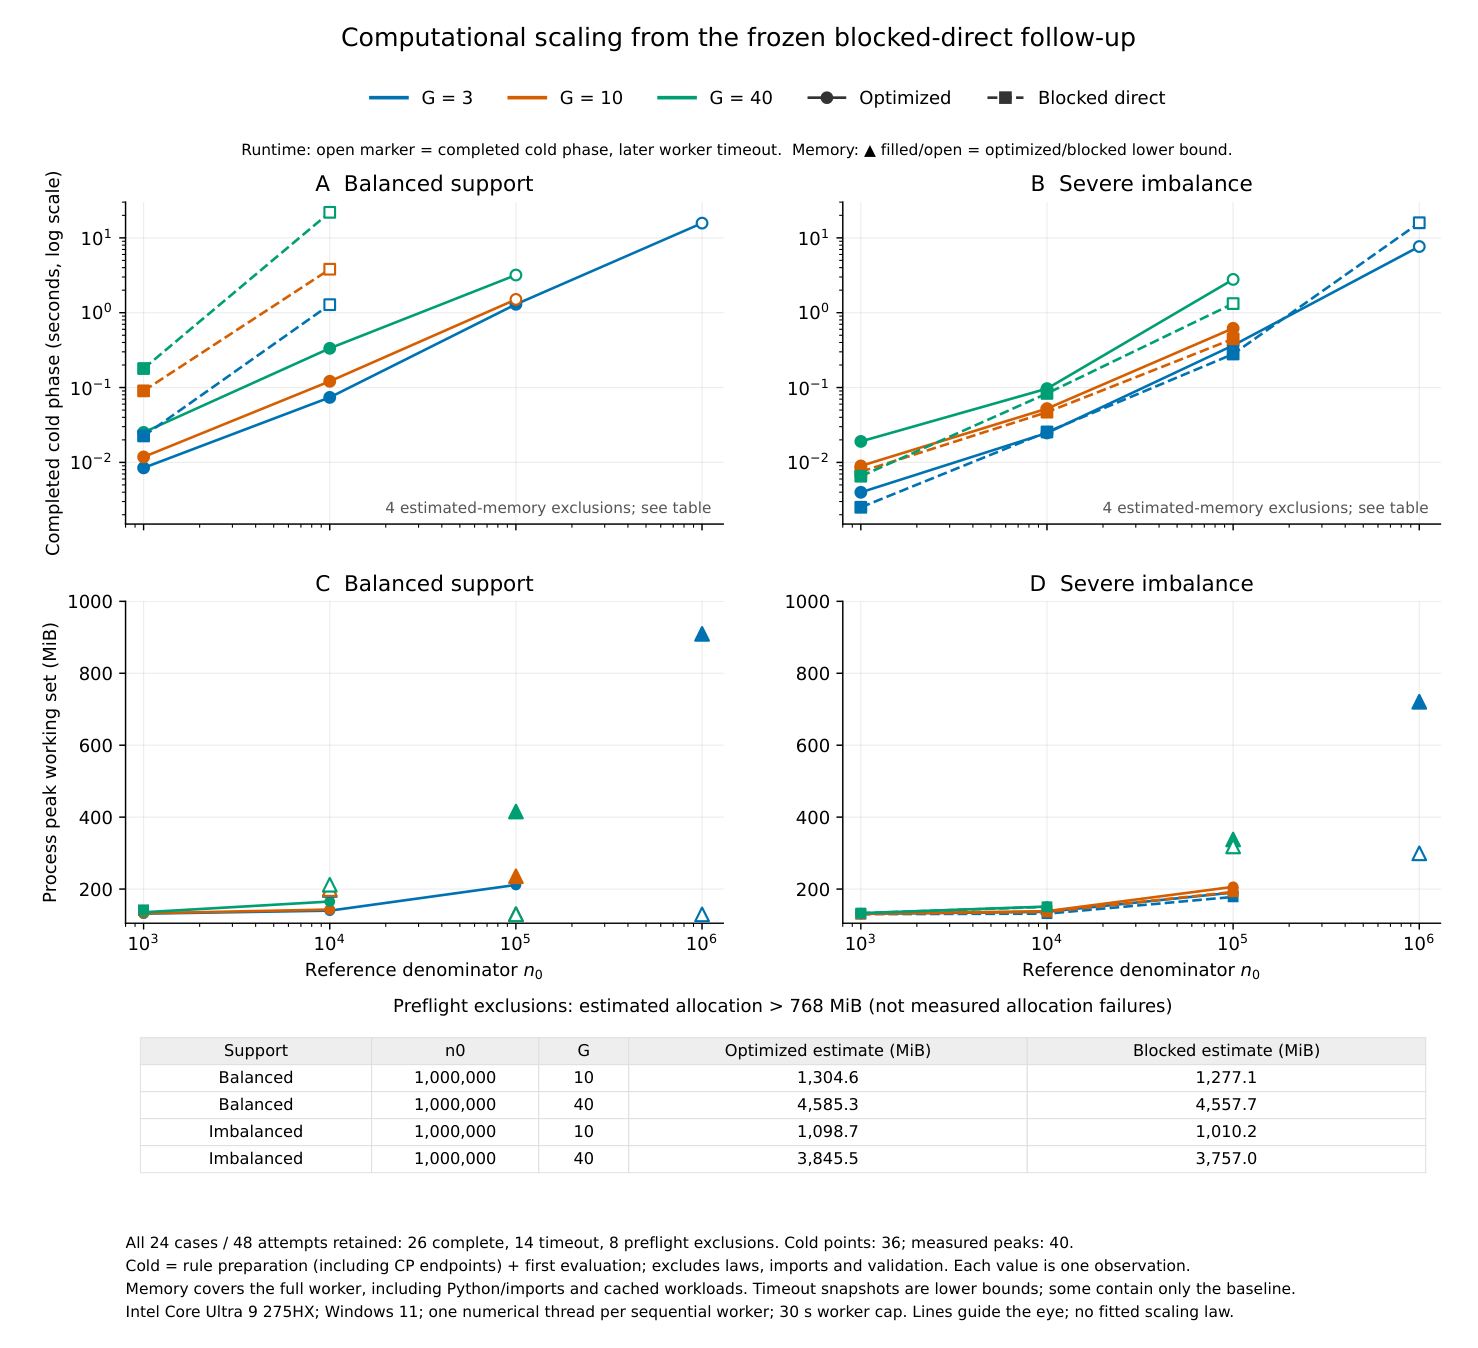

In [49]:
section_title = 'Runtime and memory curves from the frozen blocked-direct run'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

### What the 160 forecast decisions establish

In [50]:
section_title = 'What the 160 forecast decisions establish'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Pilot forecast,True target met,True target below,Total
Met,9,0,9
Not met,0,5,5
Unresolved,111,35,146
Total,120,40,160


Outcome,25% shift,50% shift
Requested/completed simulations,480/480,480/480
Target supported as met,262,319
Target supported as not met,0,0
Target unresolved,218,161
Supported met among originally unresolved,235/438,292/438
Original unresolved records met in all three repeats,63/146,88/146
Original unresolved records met in at least one repeat,90/146,109/146
Wrong supported target classifications,0,0


### Native audit components and matched allocation adaptations

In [51]:
section_title = 'Native audit components and matched allocation adaptations'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Cohort,Metric--attribute cells,Mixed cells,Largest minority VFR
Texas,35,6,.420
eICU,28,15,.446
MIMIC-III,28,8,.352


Cohort,Records,Diameter,Balancing,DP,Greedy
Texas,80,0.0000,14.1677,17.6679,12.8399
eICU,40,31.0717,31.0717,31.6539,31.6539
MIMIC-III,40,39.9463,39.9463,39.9463,39.9463


### C1 boundary reuse: invariant, cost and cache scope

In [52]:
section_title = 'C1 boundary reuse: invariant, cost and cache scope'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

### Joint thousand-group, million-reference scaling

Group laws,Method,Laws,Endpoints (s),Index (s),Peak MiB
"Distinct, balanced",Direct,0,9.930,0,289.4
"Distinct, balanced",Indexed,0,9.110,.288,374.1
"Distinct, imbalanced",Direct,0,2.813,0,188.6
"Distinct, imbalanced",Indexed,6,2.656,.091,246.9
"Repeated, balanced",Direct,3,8.094,0,290.0
"Repeated, balanced",Indexed,100,10.013,.306,352.0
"Repeated, imbalanced",Direct,100,2.732,0,221.0
"Repeated, imbalanced",Indexed,100,2.435,.068,247.2



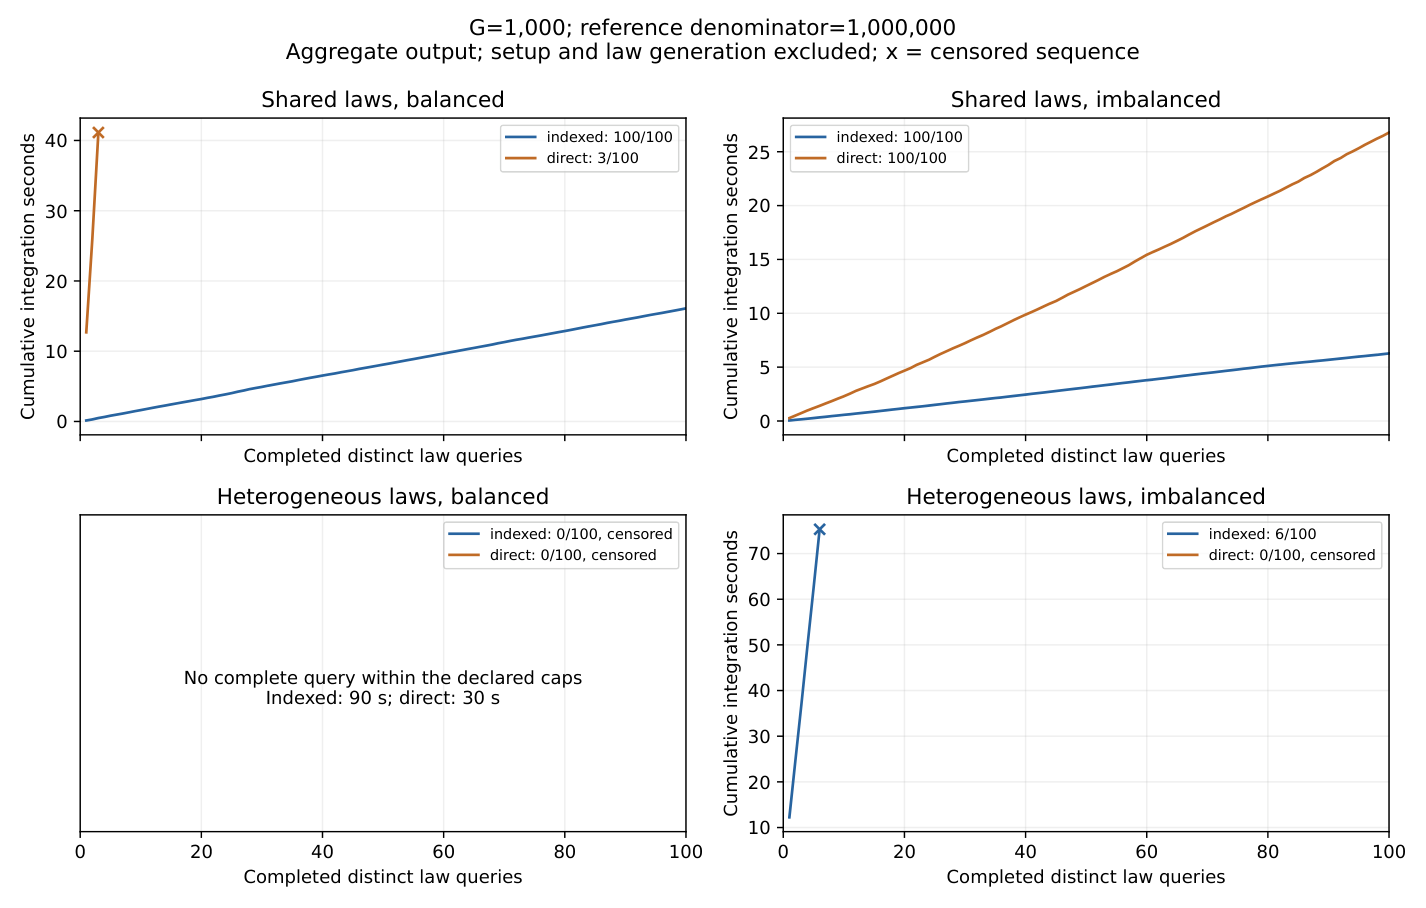

In [53]:
section_title = 'Joint thousand-group, million-reference scaling'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

### Hospital-binomial source sensitivity

In [54]:
section_title = 'Hospital-binomial source sensitivity'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Quantity,Texas,eICU
Supported hospitals,58,9
Contrast variance $\widehat\sigma_d^2$,.15514,0
Asymptotic profile 95% interval,"[.09495,.26165]","[0,.30180]"
Mean rate gap,.04100,$-.03175$
Rate-gap variance,.003536,.00004849
Parametric percentile interval,"[.001865,.005538]","[$\simeq0$,.003132]"
Generating variance retained,185/200,199/200
Monte Carlo 95% interval (%),"[87.93,95.74]","[97.25,99.99]"


### Complete comparator and operating-point reporting

In [55]:
section_title = 'Complete comparator and operating-point reporting'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Cohort,Size,Group,Method,Defined,Incl.,Issued,Conc.,Wrong,$B$
texas,25%,Asian,UAF,1,100.00,100.00,6.00,0.00,200
texas,25%,Black,UAF,1,100.00,100.00,100.00,0.00,200
texas,25%,Native American,UAF,1,99.50,100.00,0.00,0.00,200
texas,25%,Other,UAF,1,100.00,100.00,6.00,0.00,200
texas,25%,Asian,C--C min20,1,100.00,100.00,0.50,0.00,200
texas,25%,Black,C--C min20,1,98.50,100.00,100.00,0.00,200
texas,25%,Native American,C--C min20,1,100.00,34.00,0.00,0.00,200
texas,25%,Other,C--C min20,1,96.00,100.00,49.50,0.00,200
texas,25%,Asian,UM predictive,1,100.00,100.00,0.00,0.00,200
texas,25%,Black,UM predictive,1,100.00,100.00,100.00,0.00,200


Cohort / group,$n_g$,$n_0$,Feasible P/F,EB P / F,JP P / F
Texas / Asian,540,52770,PF,56.9737 / 1.06889e-07,54.6563 / 0.00188082
Texas / Black,9779,52770,PF,100 / $\le10^{-10}$,100 / $\le10^{-10}$
Texas / Native American,75,52770,PF,$\le10^{-10}$ / 1.51221e-05,$\le10^{-10}$ / 0.0344802
Texas / Other,12152,52770,PF,80.4864 / $\le10^{-10}$,72.7941 / 4.19291e-06
eICU / African American,106,1505,PF,$\le10^{-10}$ / 3.38067e-06,$\le10^{-10}$ / 0.00254648
eICU / Asian,19,1505,F,$\le10^{-10}$ / 0.0118307,$\le10^{-10}$ / 0.552584
eICU / Hispanic,52,1505,PF,$\le10^{-10}$ / 0.000461052,$\le10^{-10}$ / 0.0206159
eICU / Missing,25,1505,F,$\le10^{-10}$ / 0.349033,$\le10^{-10}$ / 2.875
eICU / Native American,10,1505,F,$\le10^{-10}$ / $\le10^{-10}$,$\le10^{-10}$ / 0.00263088
eICU / Other/Unknown,75,1505,PF,$\le10^{-10}$ / 9.02398e-06,$\le10^{-10}$ / 0.0129842


Cohort,Category,$n$,Pos.,PPV,Sens.,Spec.,Alerts,ECE
texas,Asian,"1,458",540,60.9,79.4,70.0,48.3,4.6
texas,Black,"19,005","9,779",69.2,82.3,61.1,61.2,3.8
texas,Native American,280,75,47.4,84.0,65.9,47.5,13.2
texas,Other,"34,160","12,152",64.1,75.7,76.5,42.0,2.3
texas,White (ref.),"115,030","52,770",64.2,83.9,60.3,60.0,2.2
eicu,African American,"1,595",106,18.7,80.2,75.2,28.5,1.6
eicu,Asian,224,19,21.5,73.7,75.1,29.0,2.7
eicu,Caucasian (ref.),"16,968","1,505",21.6,78.3,72.4,32.1,0.6
eicu,Hispanic,637,52,23.4,82.7,75.9,28.9,1.7
eicu,Missing,210,25,25.8,64.0,75.1,29.5,5.8


Cohort,Category,$n$,Pos.,PPV,Sens.,Spec.,Alerts,ECE
texas,Hispanic,"48,366","16,980",62.6,75.9,75.4,42.6,2.4
texas,Not Hispanic (ref.),"121,567","58,336",65.3,84.2,58.7,61.9,1.5


$n_g/n_0$,Method,Setup,Laws,Integration,Total,RSS
0.001,Direct,0.0174,0.0191,0.0405,0.0781,133.4
0.001,Indexed,0.0170,0.0192,0.0412,0.0773,133.4
0.003,Direct,0.0170,0.0199,0.0540,0.0900,133.6
0.003,Indexed,0.0171,0.0193,0.0400,0.0770,133.6
0.01,Direct,0.0209,0.0280,0.1412,0.1949,133.9
0.01,Indexed,0.0215,0.0238,0.0462,0.0915,133.8
0.03,Direct,0.0287,0.0341,0.5092,0.5778,133.4
0.03,Indexed,0.0309,0.0410,0.0881,0.1605,134.4
0.1,Direct,0.0295,0.0625,1.6762,1.7765,135.6
0.1,Indexed,0.0222,0.0360,0.0688,0.1265,135.6


### All-cohort rule and allocation continuation

In [56]:
section_title = 'All-cohort rule and allocation continuation'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Study/grid,Requested,Complete,Input cap,Other
Primary 50,160,160,0,0
Split 50,160,160,0,0
Primary 25,160,160,0,0
Split 25,160,160,0,0
Primary 1/5,160,120,40,0
Split 1/5,160,120,40,0
Unrestricted direct 50,160,80,80,0
Unrestricted direct 1/5,160,0,160,0
Support-aware direct 50,160,40,120,0
Support-aware direct 1/5,160,0,160,0


Cohort,Pilot cap,Extra,Charged,DP,Bal.,Greedy,Uniform,Oracle,Max wrong
eICU,20,250,475,26.080,24.916,26.080,24.916,27.401,0.0006972
eICU,200,250,661,37.228,37.228,37.228,37.228,37.228,0.0003656
MIMIC-III,20,250,435,39.891,39.891,39.891,39.891,39.891,1.045e-08
MIMIC-III,200,250,508,40.002,40.002,40.002,40.002,40.002,0.02244
Texas,20,250,473,4.52e-10,8.71e-10,4.52e-10,8.71e-10,4.83e-08,0.01794
Texas,20,2000,2223,29.027,26.443,28.805,26.443,40.165,0.04508
Texas,200,250,1128,3.97e-07,7.95e-09,3.81e-07,7.95e-09,5.95e-07,0.01662
Texas,200,2000,2878,41.644,30.228,22.555,30.228,43.580,0.06145


Cohort,Records,Rule,Allocation,Changed plans
eICU,40,-0.147952,0.000000,0
MIMIC-III,40,-0.000412,0.000000,0
Texas,80,0.790752,0.127941,27


Cohort,Rule/grid,Records,DP,Bal.,Greedy,Uniform,Oracle,Loss pilots,Supported
Texas,primary/50,80,17.668,14.168,12.840,14.168,20.936,15,4/4
Texas,split/50,80,18.587,15.289,13.744,15.289,21.572,17,4/4
Texas,primary/25,80,31.468,25.035,25.761,25.035,36.456,16,4/4
Texas,split/25,80,32.943,26.435,27.320,26.435,37.762,16,4/4
eICU,primary/50,40,31.654,31.072,31.654,31.072,32.314,9,6/6
eICU,split/50,40,31.506,31.360,31.506,31.360,31.982,9,6/6
eICU,primary/25,40,31.144,28.919,30.514,28.919,32.369,21,6/6
eICU,split/25,40,31.133,29.025,30.689,29.025,32.286,26,6/6
MIMIC-III,primary/50,40,39.946,39.946,39.946,39.946,39.946,0,17/40
MIMIC-III,split/50,40,39.946,39.946,39.946,39.946,39.946,0,17/40


### Predictive-target check for the Uncertainty Matters adapter

In [57]:
section_title = 'Predictive-target check for the Uncertainty Matters adapter'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Cohort,Audit size,Audits,Family inclusion,MC SE,Defined future gaps
texas,$.25N$,200,94.955,0.473,100.000
texas,$.50N$,200,95.455,0.424,100.000
texas,$N$,200,94.770,0.502,100.000
eicu,$.25N$,200,95.880,0.321,98.417
eicu,$.50N$,200,95.845,0.397,99.902
eicu,$N$,200,95.125,0.499,99.999
mimic,$.25N$,200,99.645,0.072,22.044
mimic,$.50N$,200,99.135,0.140,27.603
mimic,$N$,200,98.980,0.310,34.160


### Exact reference-run aggregation at large scale

In [58]:
section_title = 'Exact reference-run aggregation at large scale'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Implementation,Complete/100,Wall (s),Peak (MiB)
Boundary-run indexed,100,62.625,248.605
Streamed indexed,20$^{\dagger}$,304.265,248.816
Direct count-pair,3$^{\dagger}$,305.282,200.484


### Unrestricted-null exact finite-frame rule sensitivity

In [59]:
section_title = 'Unrestricted-null exact finite-frame rule sensitivity'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Cohort,Pilot cap,Extra budget,Pilots,Primary resolution,Exact resolution,Exact correct resolution,Max. family error
eICU,20,250,20,26.0800,22.3319,22.3318,0.0007
eICU,200,250,20,37.2279,31.5120,31.5119,0.0008
MIMIC-III,20,250,20,39.8908,39.1396,39.1396,0.0000
MIMIC-III,200,250,20,40.0018,40.0012,40.0012,0.0000
Texas-100X,20,250,20,0.0020,0.0401,0.0000,0.2237
Texas-100X,20,2000,20,29.0275,33.4512,33.4479,0.0373
Texas-100X,200,250,20,0.0030,0.0410,0.0000,0.2062
Texas-100X,200,2000,20,41.6538,43.2407,43.1983,0.2023


Cohort,Pilot cap,DP,Balancing,Uniform,Greedy,Oracle
eICU,20,22.7440 (22.7440),23.0031 (23.0030),23.0031 (23.0030),22.7440 (22.7440),23.0031 (23.0030)
eICU,200,31.4807 (31.4806),31.4807 (31.4806),31.4807 (31.4806),31.4807 (31.4806),31.4807 (31.4806)
MIMIC-III,20,39.1393 (39.1393),39.1393 (39.1393),39.1393 (39.1393),39.1393 (39.1393),39.1393 (39.1393)
MIMIC-III,200,40.0013 (40.0013),40.0013 (40.0013),40.0013 (40.0013),40.0013 (40.0013),40.0013 (40.0013)
Texas-100X,20,0.0243 (0.0000),0.0153 (0.0000),0.0153 (0.0000),0.0243 (0.0000),0.0555 (0.0000)
Texas-100X,200,0.0252 (0.0000),0.0145 (0.0000),0.0145 (0.0000),0.0300 (0.0000),0.0505 (0.0000)


### Scaling regimes for reusable boundary integration

In [60]:
section_title = 'Scaling regimes for reusable boundary integration'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

ID,Design,$G$,$n_0$,Group counts,Types,Tolerance
1,ratio_10,40,"10,000",10,1,.10
2,ratio_30,40,"10,000",30,1,.10
3,ratio_100,40,"10,000",100,1,.10
4,ratio_300,40,"10,000",300,1,.10
5,ratio_1000,40,"10,000",1000,1,.10
6,ratio_3000,40,"10,000",3000,1,.10
7,ratio_10000,40,"10,000",10000,1,.10
8,denominator_types_3,40,"10,000",100--1000,3,.10
9,denominator_types_10,40,"10,000",100--1000,10,.10
10,denominator_types_40,40,"10,000",100--1000,40,.10


ID,Rep.,Method,Status,Queries,Setup,Cold,Reuse,MiB
1,1,Direct,C,10/10,0.034,0.068,0.336,90.7
1,1,Index,C,10/10,0.034,0.070,0.371,92.1
1,1,Run,C,10/10,0.036,0.050,0.179,90.9
1,2,Direct,C,10/10,0.030,0.063,0.325,90.5
1,2,Index,C,10/10,0.018,0.040,0.214,91.6
1,2,Run,C,10/10,0.035,0.053,0.182,91.0
2,1,Direct,C,10/10,0.018,0.043,0.280,90.7
2,1,Index,C,10/10,0.036,0.074,0.370,91.7
2,1,Run,C,10/10,0.036,0.052,0.144,91.0
2,2,Direct,C,10/10,0.028,0.067,0.423,91.1


### Implementation contract and constructed clinical query traces

In [61]:
section_title = 'Implementation contract and constructed clinical query traces'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Cohort,Engine,Setup,Laws,Integr.,Total
Texas,Run,0.953,1.275,0.565,2.632
Texas,Index,1.420,1.519,0.745,3.684
Texas,Direct,1.246,1.687,22.024,24.957
eICU,Run,0.049,0.073,0.099,0.219
eICU,Index,0.074,0.115,0.194,0.383
eICU,Direct,0.068,0.131,1.248,1.448
MIMIC-III,Run,0.033,0.110,0.528,0.671
MIMIC-III,Index,0.026,0.080,0.398,0.506
MIMIC-III,Direct,0.018,0.078,0.410,0.507


### Additional protocol and sensitivity details

In [62]:
section_title = 'Additional protocol and sensitivity details'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

### Controlled paired integration on native clinical laws

In [63]:
section_title = 'Controlled paired integration on native clinical laws'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Cohort,Run,Index,Direct
Texas,"0.0824 [0.0771, 0.0974]","0.0892 [0.0795, 0.0981]","3.9801 [3.8115, 4.2211]"
eICU,"0.0260 [0.0209, 0.0291]","0.0276 [0.0248, 0.0355]","0.1887 [0.1684, 0.2336]"
MIMIC-III,"0.0682 [0.0577, 0.0799]","0.0688 [0.0603, 0.0797]","0.0750 [0.0660, 0.0804]"


### Current grid, guard and reproduction evidence

In [64]:
section_title = 'Current grid, guard and reproduction evidence'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Cohort,Rule,Grid,C/R,DP,Bal.,Oracle,Loss/C,Seconds
Texas,Primary,50,80/80,17.668,14.168,20.936,15/80,976.13
Texas,Split,50,80/80,18.587,15.289,21.572,17/80,1141.43
Texas,Primary,25,80/80,31.468,25.035,36.456,16/80,835.36
Texas,Split,25,80/80,32.943,26.435,37.762,16/80,1326.95
Texas,Primary,1/5+cap,40/80,19.788,$<.001$,21.514,0/40,743.79
Texas,Split,1/5+cap,40/80,20.619,$<.001$,22.395,0/40,1407.54
eICU,Primary,50,40/40,31.654,31.072,32.314,9/40,4.36
eICU,Split,50,40/40,31.506,31.360,31.982,9/40,4.49
eICU,Primary,25,40/40,31.144,28.919,32.369,21/40,5.40
eICU,Split,25,40/40,31.133,29.025,32.286,26/40,5.20


Engine,Preparation,Laws,Integration,Total,Peak
Run,14.256,1.014,1.675,16.945,177.54
Index,13.667,1.000,1.725,16.393,179.05
Direct,13.995,1.058,62.247,77.299,258.75


Rule,Grid,DP,Balancing,Oracle
Primary,50,$1.9863\!\times\!10^{-7}$,$4.4127\!\times\!10^{-9}$,$3.2189\!\times\!10^{-7}$
Primary,25,3.67127,$2.0521\!\times\!10^{-6}$,6.17435
Primary,1/5+cap,19.78824,$1.3530\!\times\!10^{-9}$,21.51358
Split,50,$5.1746\!\times\!10^{-7}$,$8.0244\!\times\!10^{-9}$,$2.0925\!\times\!10^{-6}$
Split,25,4.79304,$5.6225\!\times\!10^{-5}$,7.53356
Split,1/5+cap,20.61908,$1.5328\!\times\!10^{-9}$,22.39520


### Matched finite-sample prediction-powered review

In [65]:
section_title = 'Matched finite-sample prediction-powered review'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

$w$,Correct accept,Wrong accept,Correct reject,Wrong reject,Deferred
.05,26.4762,.0000,50.8286,.0071,22.6881
.10,.0000,.0143,77.1119,.0000,22.8738
.25,.0000,.0000,94.7048,.0000,5.2952


Engine,Rep. 1,Rep. 2,Rep. 3,Rep. 4,Rep. 5,Median
Run,24.497,26.273,14.447,13.290,15.219,15.219
Index,23.837,24.116,13.999,14.255,14.253,14.255
Direct,108.830,109.502,79.103,73.236,75.143,79.103


### Additional protocol and sensitivity detail retained from the main narrative

In [66]:
section_title = 'Additional protocol and sensitivity detail retained from the main narrative'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

### Current workload and decision diagnostics

In [67]:
section_title = 'Current workload and decision diagnostics'
display(HTML('<details><summary>Scientific protocol, derivation and interpretation</summary>'+evidence['supp_notes'][section_title]+'</details>'))
for t in evidence['supp_tables']:
    if t['section']==section_title:
        display(HTML('<details><summary>Table '+html.escape(str(t['number'])+' — '+t['caption'])+'</summary>'+t['html']+'</details>'))
for f in evidence['supp_figures']:
    if f['section']==section_title:
        display(HTML('<details><summary>Figure '+html.escape(str(f['number'])+' — '+f['caption'])+'</summary><img style="max-width:100%" src="data:image/png;base64,'+f['png']+'"/></details>'))

Weight,Direction/truth,Method,$n$,Correct,Wrong,Deferred
0.10,addition/unacceptable,Pooled exact,"20,000","12,230",40,"7,730"
0.10,addition/unacceptable,SRS stratified exact,"20,000","4,630",0,"15,370"
0.10,addition/unacceptable,Equal stratified exact,"20,000","8,547",2,"11,451"
0.10,addition/unacceptable,Equal Gaussian,"20,000","12,397",14,"7,589"
0.10,addition/unacceptable,Gaussian PPI,"20,000","13,364",27,"6,609"
0.10,addition/unacceptable,Betting PPI,"20,000","11,039",6,"8,955"
0.10,removal/unacceptable,Pooled exact,"22,000","21,348",0,652
0.10,removal/unacceptable,SRS stratified exact,"22,000","21,348",0,652
0.10,removal/unacceptable,Equal stratified exact,"22,000","21,393",0,607
0.10,removal/unacceptable,Equal Gaussian,"22,000","19,307",0,"2,693"


Grid,Rule,DP,Balancing,Oracle
50,primary,1.98633e-07,4.41265e-09,3.21894e-07
50,split,5.17464e-07,8.02439e-09,2.09249e-06
25,primary,3.67127,2.05212e-06,6.17435
25,split,4.79304,5.62245e-05,7.53356
1/5 + terminal,primary,19.7882,1.35302e-09,21.5136
1/5 + terminal,split,20.6191,1.53283e-09,22.3952


$w$,Exact pooled,Betting PPI,Total loss difference
.10,"33,578 / 40 / 8,382","32,387 / 6 / 9,607",$34c_A-1225c_D$
.05,"35,603 / 0 / 6,397","32,468 / 3 / 9,529",$-3c_R-3132c_D$
.25,"40,832 / 0 / 1,168","39,776 / 0 / 2,224",$-1056c_D$


Cohort,Queries,Run,Index,Direct,"Paired Index/Run median [min,max]"
Texas,4,.292117,.375261,1.608018,"1.2846 [.5579,1.6828]"
eICU,62,.170945,.184538,.193793,"1.1069 [.5423,1.3731]"
MIMIC-III,62,.333699,.404470,.295276,"1.3460 [.7483,1.4778]"


## Final execution record

The output below summarizes the numerical checks completed during execution.

In [68]:
record('Complete main exhibit inventory',len(evidence['main_tables'])==12 and len(evidence['main_figures'])==3,'Exact source catalogue')
display(pd.DataFrame(checks))
print(f'Completed {len(checks)} checks in {time.perf_counter()-started:.1f} seconds.')
print('Fresh: exact count-law probabilities, fitted source calculations, allocation recurrence, pooled policy decisions.')
print('Reaggregated: saved matched-method, planning and policy experiments. Recorded: model fits, timings and companion tables.')

,Check,Status,Scope
0,Embedded numerical evidence integrity,Passed,Aggregate-file checksums and row counts
1,Main Table III,Passed,Reconstructed from all 12 partition records
2,Stored partition and preprocessing checks,Passed,Rechecked exported audit results; no raw patie...
3,Predictive confusion-count consistency,Passed,12 frozen fits; score metrics retained from re...
4,All 234 exact family forecasts,Passed,Fresh count-law integration
5,Main Table V,Passed,All six EB/JP rows recomputed; three unit-boot...
6,Main Tables IV and VI,Passed,Saved phase-cost arithmetic and feasibility pa...
7,Main Table VII,Passed,"Recomputed summaries from 39,200 audit-method ..."
8,Main Table VIII,Passed,Fitted risks and sufficient counts recomputed;...
9,Hospital-binomial simulation counts,Passed,Reaggregated recorded simulation fits


Completed 17 checks in 35.8 seconds.
Fresh: exact count-law probabilities, fitted source calculations, allocation recurrence, pooled policy decisions.
Reaggregated: saved matched-method, planning and policy experiments. Recorded: model fits, timings and companion tables.
